In [24]:
import pandas as pd
import numpy as np
import sys
import os
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import mahalanobis
from scipy.linalg import pinv
from scipy.stats import pearsonr
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.covariance import LedoitWolf


sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [25]:
inputs_dirs = "../1_inputs/sqY2H"
output_dirs = "../3_outputs/sqY2H"
meta_outputs = '../../../1_allele_collection/3_outputs'

# Data loading

In [26]:
# Load the data that's already QC/QC'd from the notebook 2_normalize_sqY2H_automated.ipynb

scores = pl.read_csv(f"{output_dirs}/3_automated_qaqc_consensus_scores.csv")
scores


scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth
str,str,str,str,str,str,i64,bool,i64,str,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,i64,i64,str,f64,str
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""",1,false,71704,null,11805,0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,528.001331,false,9.174929,558.350679,"""SMURF2""","""SMAD3""",null,null,"""ENSG00000166949""",null,null,null,null,"""SMAD3""","""11805.0_0.0""","""11805.0_0.0_LW_VUSAPWT1B1""","""71704.0_11805.0_0.0_VUSAPWT1B1""","""71704.0_11805.0_VUSAPWT1B1""",1,1,null,509.083347,null
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""",1,false,13662,null,70497,0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,585.556892,false,9.311877,586.988591,"""CYSRT1""","""AGXT""",null,null,"""ENSG00000172482""",null,null,null,null,"""AGXT""","""70497.0_0.0""","""70497.0_0.0_LW_VUSAPWT1B1""","""13662.0_70497.0_0.0_VUSAPWT1B1""","""13662.0_70497.0_VUSAPWT1B1""",1,1,null,515.308517,null
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""",1,false,11567,null,52920,0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",4.0,572.135977,false,9.281086,578.211793,"""TAX1BP1""","""LITAF""",null,null,"""ENSG00000189067""",null,null,null,null,"""LITAF""","""52920.0_0.0""","""52920.0_0.0_LW_VUSAPWT1B1""","""11567.0_52920.0_0.0_VUSAPWT1B1""","""11567.0_52920.0_VUSAPWT1B1""",1,1,null,549.030745,null
"""VUSAPWT1B1r01_001""","""C03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""",1,false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",4.0,476.3242,false,9.039808,509.349041,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""",1,1,null,494.701983,null
"""VUSAPWT1B1r01_001""","""C07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""",1,false,5441,null,71892,0,"""DisWTGDEh03""","""B03""","""CEGSint_Y8A_5""","""B07""",4.0,447.00917,false,8.957129,529.735972,"""PUF60""","""TH""",null,null,"""ENSG00000180176""",null,null,null,null,"""TH""","""71892.0_0.0""","""71892.0_0.0_LW_VUSAPWT1B1""","""5441.0_71892.0_0.0_VUSAPWT1B1""","""5441.0_71892.0_VUSAPWT1B1""",1,1,null,483.573543,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_033""","""O13""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""",1,false,11922,null,2713,200832,"""VUSMutY8Dh018""","""B04""","""CEGSint_Y8A_6""","""D05""",2.0,48.005229,false,6.614787,null,"""MYOG""","""MLH1""","""Gly147Arg""","""439G>C""","""ENSG00000076242""","""CEGS2""","""3_Conflicting""",null,1.0,"""MLH1_Gly147Arg""","""2713.0_200832.0""","""2713.0_200832.0_LWAH1_VUSAPWT1…","""11922.0_2713.0_200832.0_VUSAPW…","""11922.0_2713.0_VUSAPWT1B1""",1,1,"""Y""",2.590196,"""2.0"""
"""VUSAPWT1B1r06_033""","""O15""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""",1,false,9267,null,3535,201190,"""VUSMutY8Dh018""","""D11""","""CEGSint_Y8A_4""","""G10""",3.0,0.0,false,5.643856,null,"""CCDC155""","""EMD""","""Met1Val""","""1A>G""","""ENSG00000102119""","""CEGS2""","""1_Pathogenic""",9.5000e-7,2.0,"""EMD_Met1Val""","""3535.0_201190.0""","""3535

# Scoring strategies

## Summing all scoring media (LWH1, LWH10, LWH25 and LWA)

In [27]:
scoring_conditions = ["LWH1", "LWH10", "LWH25", "LWA"]
scoring_no_LWA_conditions = ["LWH1", "LWH10", "LWH25"]


# max score is defined as an arbitrary threshold based on the distribution of scores

max_score = 750

aa_id = 0.0
rrs_id = 999999

In [28]:
# # Summing scores

# # Keep a reference to original data with condition names
# original_conditions = scores.filter(pl.col("condition_name").is_in(scoring_conditions)).select([
#     'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'condition_name'
# ]).unique()

# summed_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

# summed_scores_pd = summed_scores.to_pandas()
# print(summed_scores_pd.db_orf_id.nunique())

# # First, sum adjusted scores across conditions for each variant + normalization test
# summed_scores = summed_scores.group_by([
#     'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
# ]).agg([
#     pl.col("condition_name").n_unique().alias("n_conditions"),
#     pl.col("consensus_score").sum().alias("summed_consensus_score"),
#     # Keep LWH1 scores separately
#     pl.col("consensus_score").filter(pl.col("condition_name") == "LWH1").first().alias("lwh1_consensus_score"),
#     pl.col("consensus_score").filter(pl.col("condition_name") == "LWA").first().alias("lwa_consensus_score"),
#     pl.col("consensus_score").filter(pl.col("condition_name").is_in(scoring_no_LWA_conditions)).sum().alias("3at_consensus_score")
# ])


# # Normalization
# summed_scores = summed_scores.with_columns(
#     (pl.col("summed_consensus_score") / (len(scoring_conditions) * max_score)).alias("summed_consensus_score_normalized"),
#     (pl.col("summed_consensus_score") / (pl.col("n_conditions") * max_score)).alias("summed_consensus_score_normalized_used_media"),
#     (pl.col("3at_consensus_score") / (len(scoring_no_LWA_conditions) * max_score)).alias("3at_summed_consensus_score_normalized"),
#     # Normalize LWH1 score
#     (pl.col("lwh1_consensus_score") / max_score).alias("lwh1_consensus_score_normalized"),
#     (pl.col("lwa_consensus_score") / max_score).alias("lwa_consensus_score_normalized")
# )


# summed_scores_pd = summed_scores.to_pandas()
# print(summed_scores_pd.db_orf_id.nunique())

# # Get WT scores (db_mut_id == 0) for normalization - now including LWH1
# wt_scores = summed_scores.filter(pl.col("db_mut_id") == 0).select([
#     "ad_orf_id", "db_orf_id", "retest_batch", 
#     "summed_consensus_score", "summed_consensus_score_normalized",
#     "lwh1_consensus_score", "lwh1_consensus_score_normalized",
#     "lwa_consensus_score_normalized", "lwa_consensus_score",
#     "3at_summed_consensus_score_normalized", "3at_consensus_score"
# ]).rename({
#     "summed_consensus_score": "wt_summed_score",
#     "summed_consensus_score_normalized": "wt_summed_score_normalized",
#     "lwh1_consensus_score": "wt_lwh1_score", 
#     "lwh1_consensus_score_normalized": "wt_lwh1_score_normalized",
#     "3at_consensus_score": "wt_3at_summed_score",
#     "3at_summed_consensus_score_normalized": "wt_3at_summed_score_normalized",
#     "lwa_consensus_score": "wt_lwa_score",
#     "lwa_consensus_score_normalized": "wt_lwa_score_normalized"
# })

# # Join variant scores with their corresponding WT scores
# summed_scores = summed_scores.join(
#     wt_scores, 
#     on=["ad_orf_id", "db_orf_id", "retest_batch"], 
#     how="left"
# ).filter(
#     pl.col("wt_summed_score").is_not_null()  # Only keep variants that have a WT reference measurement
# )


# # Join back with original to get condition names
# summed_scores = summed_scores.join(
#     original_conditions,
#     on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"],
#     how="left"
# )

# summed_scores_pd = summed_scores.to_pandas()
# print(summed_scores_pd.db_orf_id.nunique())

# summed_scores = summed_scores.with_columns(
#     pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
# )

# summed_scores = summed_scores.with_columns(
#     pl.concat_str([
#         pl.col('ad_orf_id').cast(pl.String),
#         pl.col('db_orf_id').cast(pl.String),
#         pl.col('db_mut_id').cast(pl.String),
#         pl.col('retest_batch').cast(pl.String)
#     ], separator="_").alias("ppi_group")
# )

# summed_scores

In [29]:
# Summing scores

# Keep a reference to original data with condition names
original_conditions = scores.filter(pl.col("condition_name").is_in(scoring_conditions)).select([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'condition_name'
]).unique()

summed_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())
# Summing scores

# Keep a reference to original data with condition names
original_conditions = scores.filter(pl.col("condition_name").is_in(scoring_conditions)).select([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'condition_name'
]).unique()

summed_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())
# First, sum adjusted scores across conditions for each variant + normalization test
summed_scores = summed_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg([
    pl.col("condition_name").n_unique().alias("n_conditions"),
    pl.col("consensus_score").sum().alias("summed_consensus_score"),
    # Keep LWH1 scores separately
    pl.col("consensus_score").filter(pl.col("condition_name") == "LWH1").first().alias("lwh1_consensus_score"),
    pl.col("consensus_score").filter(pl.col("condition_name") == "LWA").first().alias("lwa_consensus_score"),
    pl.col("consensus_score").filter(pl.col("condition_name").is_in(scoring_no_LWA_conditions)).sum().alias("3at_consensus_score"),
    # Add weighted 3AT score
    (
        pl.col("consensus_score").filter(pl.col("condition_name") == "LWH1").first() * 1 +
        pl.col("consensus_score").filter(pl.col("condition_name") == "LWH10").first() * 10 +
        pl.col("consensus_score").filter(pl.col("condition_name") == "LWH25").first() * 25
    ).alias("3at_weighted_consensus_score")
])

# Normalization - add the weighted normalization
summed_scores = summed_scores.with_columns(
    (pl.col("summed_consensus_score") / (len(scoring_conditions) * max_score)).alias("summed_consensus_score_normalized"),
    (pl.col("summed_consensus_score") / (pl.col("n_conditions") * max_score)).alias("summed_consensus_score_normalized_used_media"),
    (pl.col("3at_consensus_score") / (len(scoring_no_LWA_conditions) * max_score)).alias("3at_summed_consensus_score_normalized"),
    # Normalize weighted 3AT score (dividing by sum of weights: 1 + 10 + 25 = 36)
    (pl.col("3at_weighted_consensus_score") / (36 * max_score)).alias("3at_weighted_consensus_score_normalized"),
    # Normalize LWH1 score
    (pl.col("lwh1_consensus_score") / max_score).alias("lwh1_consensus_score_normalized"),
    (pl.col("lwa_consensus_score") / max_score).alias("lwa_consensus_score_normalized")
)

# Update WT scores to include weighted score
wt_scores = summed_scores.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", 
    "summed_consensus_score", "summed_consensus_score_normalized",
    "lwh1_consensus_score", "lwh1_consensus_score_normalized",
    "lwa_consensus_score_normalized", "lwa_consensus_score",
    "3at_summed_consensus_score_normalized", "3at_consensus_score",
    "3at_weighted_consensus_score", "3at_weighted_consensus_score_normalized"
]).rename({
    "summed_consensus_score": "wt_summed_score",
    "summed_consensus_score_normalized": "wt_summed_score_normalized",
    "lwh1_consensus_score": "wt_lwh1_score", 
    "lwh1_consensus_score_normalized": "wt_lwh1_score_normalized",
    "3at_consensus_score": "wt_3at_summed_score",
    "3at_summed_consensus_score_normalized": "wt_3at_summed_score_normalized",
    "3at_weighted_consensus_score": "wt_3at_weighted_score",
    "3at_weighted_consensus_score_normalized": "wt_3at_weighted_score_normalized",
    "lwa_consensus_score": "wt_lwa_score",
    "lwa_consensus_score_normalized": "wt_lwa_score_normalized"
})

# Join variant scores with their corresponding WT scores
summed_scores = summed_scores.join(
    wt_scores, 
    on=["ad_orf_id", "db_orf_id", "retest_batch"], 
    how="left"
).filter(
    pl.col("wt_summed_score").is_not_null()  # Only keep variants that have a WT reference measurement
)


# Join back with original to get condition names
summed_scores = summed_scores.join(
    original_conditions,
    on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"],
    how="left"
)

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

summed_scores = summed_scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

summed_scores = summed_scores.with_columns(
    pl.concat_str([
        pl.col('ad_orf_id').cast(pl.String),
        pl.col('db_orf_id').cast(pl.String),
        pl.col('db_mut_id').cast(pl.String),
        pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group")
)

summed_scores

# Join variant scores with their corresponding WT scores
summed_scores = summed_scores.join(
    wt_scores, 
    on=["ad_orf_id", "db_orf_id", "retest_batch"], 
    how="left"
).filter(
    pl.col("wt_summed_score").is_not_null()  # Only keep variants that have a WT reference measurement
)


# # Join back with original to get condition names
# summed_scores = summed_scores.join(
#     original_conditions,
#     on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"],
#     how="left"
# )

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

summed_scores = summed_scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

summed_scores = summed_scores.with_columns(
    pl.concat_str([
        pl.col('ad_orf_id').cast(pl.String),
        pl.col('db_orf_id').cast(pl.String),
        pl.col('db_mut_id').cast(pl.String),
        pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group")
)

summed_scores

204
204
195
195


ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,lwa_consensus_score,3at_consensus_score,3at_weighted_consensus_score,summed_consensus_score_normalized,summed_consensus_score_normalized_used_media,3at_summed_consensus_score_normalized,3at_weighted_consensus_score_normalized,lwh1_consensus_score_normalized,lwa_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,wt_lwa_score_normalized,wt_lwa_score,wt_3at_summed_score_normalized,wt_3at_summed_score,wt_3at_weighted_score,wt_3at_weighted_score_normalized,condition_name,assay_id,ppi_group,wt_summed_score_right,wt_summed_score_normalized_right,wt_lwh1_score_right,wt_lwh1_score_normalized_right,wt_lwa_score_normalized_right,wt_lwa_score_right,wt_3at_summed_score_normalized_right,wt_3at_summed_score_right,wt_3at_weighted_score_right,wt_3at_weighted_score_normalized_right
i64,i64,i64,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
100068229,5431,0,"""VUSAPWT1B2""",4,680.703931,440.680724,0.0,680.703931,4236.996147,0.226901,0.226901,0.302535,0.156926,0.587574,0.0,680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""LWH25""","""1""","""100068229_5431_0_VUSAPWT1B2""",680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926
100068229,5431,0,"""VUSAPWT1B2""",4,680.703931,440.680724,0.0,680.703931,4236.996147,0.226901,0.226901,0.302535,0.156926,0.587574,0.0,680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""LWH1""","""1""","""100068229_5431_0_VUSAPWT1B2""",680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926
100068229,5431,0,"""VUSAPWT1B2""",4,680.703931,440.680724,0.0,680.703931,4236.996147,0.226901,0.226901,0.302535,0.156926,0.587574,0.0,680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""LWA""","""1""","""100068229_5431_0_VUSAPWT1B2""",680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926
100068229,5431,0,"""VUSAPWT1B2""",4,680.703931,440.680724,0.0,680.703931,4236.996147,0.226901,0.226901,0.302535,0.156926,0.587574,0.0,680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""LWH10""","""1""","""100068229_5431_0_VUSAPWT1B2""",680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926
4351,2713,449,"""VUSAPWT6B1""",4,180.716343,94.089218,0.0,180.716343,2228.80166,0.060239,0.060239,0.080318,0.082548,0.125452,0.0,1745.430348,0.58181,470.184985,0.626913,0.243695,182.771576,0.694515,1562.658772,18269.896946,0.676663,"""LWH10""","""6""","""4351_2713_449_VUSAPWT6B1""",1745.430348,0.58181,470.184985,0.626913,0.243695,182.771576,0.694515,1562.658772,18269.896946,0.676663
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
9342,3535,6171,"""VUSAPWT1B1""",4,1527.644496,551.821266,45.421569,1482.222927,16753.69097,0.509215,0.509215,0.658766,0.620507,0.735762,0.060562,606.817003,0.202272,null,null,0.0,0.0,0.269696,606.817003,null,null,"""LWH10""","""1""","""9342_3535_6171_VUSAPWT1B1""",606.817003,0.202272,null,null,0.0,0.0,0.269696,606.817003,null,null
1235,52920,2670,"""VUSAPWT2B1""",4,659.785312,457.38923,83.030394,576.754918,2715.462788,0.219928,0.219928,0.256336,0.100573,0.609852,0.110707,1728.347445,0.576116,479.31309,0.639084,0.274371,205.778435,0.676697,1522.56901,18377.426445,0.680645,"""LWH25""","""2""","""1235_52920_2670_VUSAPWT2B1""",1728.347445,0.576116,479.31309,0.639084,0.274371,205.778435,0.676697,1522.56901,18377.426445,0.680645
1235,52920,2670,"""VUSAPWT2B1""",4,659.785312,457.38923,83.030394,576.754918,2715.462788,0.219928,0.219928,0.256336,0.100573,0.609852,0.110707,1728.347445,0.576116,479.31309,0.639084,0.274371,205.778435,0.676697,1522.56901,18377.426445,0.680645,"""LWH1"

In [30]:
print(summed_scores.shape)
print('ppis', summed_scores.select(pl.col("ppi_group").n_unique()).item())
print('nodes', summed_scores.select(pl.col("db_orf_id").n_unique()).item())
print('ads', summed_scores.select(pl.col("ad_orf_id").n_unique()).item())

(9259, 39)
ppis 2359
nodes 195
ads 543


In [31]:
# map ad_orf_id to ad_symbol
mapping_file = pd.read_csv(f"{inputs_dirs}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

summed_scores = summed_scores.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,lwa_consensus_score,3at_consensus_score,3at_weighted_consensus_score,summed_consensus_score_normalized,summed_consensus_score_normalized_used_media,3at_summed_consensus_score_normalized,3at_weighted_consensus_score_normalized,lwh1_consensus_score_normalized,lwa_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,wt_lwa_score_normalized,wt_lwa_score,wt_3at_summed_score_normalized,wt_3at_summed_score,wt_3at_weighted_score,wt_3at_weighted_score_normalized,condition_name,assay_id,ppi_group,wt_summed_score_right,wt_summed_score_normalized_right,wt_lwh1_score_right,wt_lwh1_score_normalized_right,wt_lwa_score_normalized_right,wt_lwa_score_right,wt_3at_summed_score_normalized_right,wt_3at_summed_score_right,wt_3at_weighted_score_right,wt_3at_weighted_score_normalized_right,ad_symbol
i64,i64,i64,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
100068229,5431,0,"""VUSAPWT1B2""",4,680.703931,440.680724,0.0,680.703931,4236.996147,0.226901,0.226901,0.302535,0.156926,0.587574,0.0,680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""LWH25""","""1""","""100068229_5431_0_VUSAPWT1B2""",680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""KRT76"""
100068229,5431,0,"""VUSAPWT1B2""",4,680.703931,440.680724,0.0,680.703931,4236.996147,0.226901,0.226901,0.302535,0.156926,0.587574,0.0,680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""LWH1""","""1""","""100068229_5431_0_VUSAPWT1B2""",680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""KRT76"""
100068229,5431,0,"""VUSAPWT1B2""",4,680.703931,440.680724,0.0,680.703931,4236.996147,0.226901,0.226901,0.302535,0.156926,0.587574,0.0,680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""LWA""","""1""","""100068229_5431_0_VUSAPWT1B2""",680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""KRT76"""
100068229,5431,0,"""VUSAPWT1B2""",4,680.703931,440.680724,0.0,680.703931,4236.996147,0.226901,0.226901,0.302535,0.156926,0.587574,0.0,680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""LWH10""","""1""","""100068229_5431_0_VUSAPWT1B2""",680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""KRT76"""
4351,2713,449,"""VUSAPWT6B1""",4,180.716343,94.089218,0.0,180.716343,2228.80166,0.060239,0.060239,0.080318,0.082548,0.125452,0.0,1745.430348,0.58181,470.184985,0.626913,0.243695,182.771576,0.694515,1562.658772,18269.896946,0.676663,"""LWH10""","""6""","""4351_2713_449_VUSAPWT6B1""",1745.430348,0.58181,470.184985,0.626913,0.243695,182.771576,0.694515,1562.658772,18269.896946,0.676663,"""NME4"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
9342,3535,6171,"""VUSAPWT1B1""",4,1527.644496,551.821266,45.421569,1482.222927,16753.69097,0.509215,0.509215,0.658766,0.620507,0.735762,0.060562,606.817003,0.202272,null,null,0.0,0.0,0.269696,606.817003,null,null,"""LWH10""","""1""","""9342_3535_6171_VUSAPWT1B1""",606.817003,0.202272,null,null,0.0,0.0,0.269696,606.817003,null,null,"""BEND7"""
1235,52920,2670,"""VUSAPWT2B1""",4,659.785312,457.38923,83.030394,576.754918,2715.462788,0.219928,0.219928,0.256336,0.100573,0.609852,0.110707,1728.347445,0.576116,479.31309,0.639084,0.274371,205.778435,0.676697,1522.56901,18377.426445,0.680645,"""LWH25""","""2""","""1235_52920_2670_VUSAPWT2B1""",1728.347445,0.576116,479.31309,0.639084,0.274371,205.778435,0.676697,1522.56901,18377.426445,0.680645,"""HPCAL4"""
1235,52920,2670,"""VUSAPWT2B1""",4,659.785312,457.38923,83.030394,576.754918,2715.462788,0.219928,0.219928,0.256336,0.100573,0.609852,0.110707,1728.34744

In [32]:
# Append metadata and write out file
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
})

summed_scores = summed_scores.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,lwa_consensus_score,3at_consensus_score,3at_weighted_consensus_score,summed_consensus_score_normalized,summed_consensus_score_normalized_used_media,3at_summed_consensus_score_normalized,3at_weighted_consensus_score_normalized,lwh1_consensus_score_normalized,lwa_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,wt_lwa_score_normalized,wt_lwa_score,wt_3at_summed_score_normalized,wt_3at_summed_score,wt_3at_weighted_score,wt_3at_weighted_score_normalized,condition_name,assay_id,ppi_group,wt_summed_score_right,wt_summed_score_normalized_right,wt_lwh1_score_right,wt_lwh1_score_normalized_right,wt_lwa_score_normalized_right,wt_lwa_score_right,wt_3at_summed_score_normalized_right,wt_3at_summed_score_right,wt_3at_weighted_score_right,wt_3at_weighted_score_normalized_right,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,str,f64,f64,str
100068229,5431,0,"""VUSAPWT1B2""",4,680.703931,440.680724,0.0,680.703931,4236.996147,0.226901,0.226901,0.302535,0.156926,0.587574,0.0,680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""LWH25""","""1""","""100068229_5431_0_VUSAPWT1B2""",680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""KRT76""","""POLR1C""",null,null,"""ENSG00000171453""",null,null,null,null,"""POLR1C"""
100068229,5431,0,"""VUSAPWT1B2""",4,680.703931,440.680724,0.0,680.703931,4236.996147,0.226901,0.226901,0.302535,0.156926,0.587574,0.0,680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""LWH1""","""1""","""100068229_5431_0_VUSAPWT1B2""",680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""KRT76""","""POLR1C""",null,null,"""ENSG00000171453""",null,null,null,null,"""POLR1C"""
100068229,5431,0,"""VUSAPWT1B2""",4,680.703931,440.680724,0.0,680.703931,4236.996147,0.226901,0.226901,0.302535,0.156926,0.587574,0.0,680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""LWA""","""1""","""100068229_5431_0_VUSAPWT1B2""",680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""KRT76""","""POLR1C""",null,null,"""ENSG00000171453""",null,null,null,null,"""POLR1C"""
100068229,5431,0,"""VUSAPWT1B2""",4,680.703931,440.680724,0.0,680.703931,4236.996147,0.226901,0.226901,0.302535,0.156926,0.587574,0.0,680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""LWH10""","""1""","""100068229_5431_0_VUSAPWT1B2""",680.703931,0.226901,440.680724,0.587574,0.0,0.0,0.302535,680.703931,4236.996147,0.156926,"""KRT76""","""POLR1C""",null,null,"""ENSG00000171453""",null,null,null,null,"""POLR1C"""
4351,2713,449,"""VUSAPWT6B1""",4,180.716343,94.089218,0.0,180.716343,2228.80166,0.060239,0.060239,0.080318,0.082548,0.125452,0.0,1745.430348,0.58181,470.184985,0.626913,0.243695,182.771576,0.694515,1562.658772,18269.896946,0.676663,"""LWH10""","""6""","""4351_2713_449_VUSAPWT6B1""",1745.430348,0.58181,470.184985,0.626913,0.243695,182.771576,0.694515,1562.658772,18269.896946,0.676663,"""NME4""","""MLH1""","""Pro28Leu""","""83C>T""","""ENSG00000076242""","""Edgotyping3""","""1_Pathogenic""",6.8405e-7,3.0,"""MLH1_Pro28Leu"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
9342,3535,6171,"""VUSAPWT1B1""",4,1527.644496,551.821266,45.421569,1482.222927,16753.69097,0.509215,0.509215,0.658766,0.620507,0.735762,0.060562,606.817003,0.202272,null,null,0.0,0.0,0.269696,606.817003,null,null,"""LWH10""","""1""","""9342_3535_6171_VUSAPWT1B1""",606.817003,0.202272,null,null,0.0,0.0,0.2696

In [33]:
# Filter to keep only genes that have at least one allele tested and reference WT measurement

orfs_with_alleles = summed_scores.filter(pl.col("db_mut_id") != 0).select("db_orf_id").unique().to_series().to_list()
orfs = summed_scores.filter(pl.col("db_mut_id") == 0).select("db_orf_id").unique().to_series().to_list()

complete_orf_pairs = [i for i in orfs if i in orfs_with_alleles]
summed_scores = summed_scores.filter(pl.col("db_orf_id").is_in(complete_orf_pairs))
genes = summed_scores.select("db_orf_id").to_series().unique().to_list()

# Since scores were summed across conditions, there should be only one entry per ad_orf_id, db_orf_id, db_mut_id, retest_batch combination

summed_scores = summed_scores.unique(subset=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"])


print(summed_scores.select(pl.col('db_orf_id')).n_unique())
summed_scores

73


ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,lwa_consensus_score,3at_consensus_score,3at_weighted_consensus_score,summed_consensus_score_normalized,summed_consensus_score_normalized_used_media,3at_summed_consensus_score_normalized,3at_weighted_consensus_score_normalized,lwh1_consensus_score_normalized,lwa_consensus_score_normalized,wt_summed_score,wt_summed_score_normalized,wt_lwh1_score,wt_lwh1_score_normalized,wt_lwa_score_normalized,wt_lwa_score,wt_3at_summed_score_normalized,wt_3at_summed_score,wt_3at_weighted_score,wt_3at_weighted_score_normalized,condition_name,assay_id,ppi_group,wt_summed_score_right,wt_summed_score_normalized_right,wt_lwh1_score_right,wt_lwh1_score_normalized_right,wt_lwa_score_normalized_right,wt_lwa_score_right,wt_3at_summed_score_normalized_right,wt_3at_summed_score_right,wt_3at_weighted_score_right,wt_3at_weighted_score_normalized_right,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,str,f64,f64,str
7982,7982,202807,"""VUSAPWT1B2""",4,1796.853661,600.491859,494.984655,1301.869007,10382.949674,0.598951,0.598951,0.578608,0.384554,0.800656,0.65998,2341.15434,0.780385,600.396433,0.800529,0.698541,523.905892,0.807666,1817.248448,21544.132652,0.797931,"""LWH1""","""1""","""7982_7982_202807_VUSAPWT1B2""",2341.15434,0.780385,600.396433,0.800529,0.698541,523.905892,0.807666,1817.248448,21544.132652,0.797931,"""HPRT1""","""HPRT1""","""Asp201Gly""","""602A>G""","""ENSG00000165704""","""CEGS2""","""1_Pathogenic""",0.0,null,"""HPRT1_Asp201Gly"""
8843,2713,449,"""VUSAPWT2B1""",4,286.127781,196.116016,0.0,286.127781,2446.410152,0.095376,0.095376,0.127168,0.090608,0.261488,0.0,1350.982395,0.450327,584.047083,0.778729,0.000903,0.677451,0.600136,1350.304944,12477.841441,0.462142,"""LWH10""","""2""","""8843_2713_449_VUSAPWT2B1""",1350.982395,0.450327,584.047083,0.778729,0.000903,0.677451,0.600136,1350.304944,12477.841441,0.462142,"""FAM208B""","""MLH1""","""Pro28Leu""","""83C>T""","""ENSG00000076242""","""Edgotyping3""","""1_Pathogenic""",6.8405e-7,3.0,"""MLH1_Pro28Leu"""
53964,2713,200902,"""VUSAPWT1B1""",4,1496.146773,570.497409,0.0,1496.146773,16665.667612,0.498716,0.498716,0.664954,0.617247,0.760663,0.0,1288.531081,0.42951,569.921595,0.759895,0.002919,2.189216,0.571707,1286.341865,11309.565508,0.418873,"""LWH25""","""1""","""53964_2713_200902_VUSAPWT1B1""",1288.531081,0.42951,569.921595,0.759895,0.002919,2.189216,0.571707,1286.341865,11309.565508,0.418873,"""NFIX""","""MLH1""","""Lys751Arg""","""2252A>G""","""ENSG00000076242""","""CEGS2""","""2_Benign""",0.000148,3.0,"""MLH1_Lys751Arg"""
5772,3535,0,"""VUSAPWT1B1""",3,914.581068,null,5.227124,909.353943,null,0.30486,0.40648,0.404157,null,null,0.006969,914.581068,0.30486,null,null,0.006969,5.227124,0.404157,909.353943,null,null,"""LWH10""","""1""","""5772_3535_0_VUSAPWT1B1""",914.581068,0.30486,null,null,0.006969,5.227124,0.404157,909.353943,null,null,"""BANF1""","""EMD""",null,null,"""ENSG00000102119""",null,null,null,null,"""EMD"""
1611,2713,200832,"""VUSAPWT1B1""",4,991.502314,155.613079,0.0,991.502314,13490.431975,0.330501,0.330501,0.440668,0.499646,0.207484,0.0,1391.643824,0.463881,515.201002,0.686935,0.573678,430.258502,0.427282,961.385322,null,null,"""LWA""","""1""","""1611_2713_200832_VUSAPWT1B1""",1391.643824,0.463881,515.201002,0.686935,0.573678,430.258502,0.427282,961.385322,null,null,"""SPERT""","""MLH1""","""Gly147Arg""","""439G>C""","""ENSG00000076242""","""CEGS2""","""3_Conflicting""",null,1.0,"""MLH1_Gly147Arg"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
8186,4062,201433,"""VUSAPWT2B1""",4,521.779536,372.416133,0.0,521.779536,2731.81487,0.173927,0.173927,0.231902,0.101178,0.496555,0.0,1066.946222,

In [34]:
summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.ppi_group.nunique())

1808


## orf_distances all media

In [35]:
# Create profiles for each profiled gene

profiles = dict()
shape_summary = []
for gene in genes:
    gene_scores = summed_scores.filter(pl.col("db_orf_id") == gene)
    duplicates = gene_scores.group_by(["ad_orf_id", "db_mut_id"]).len().filter(pl.col("len") > 1)
    profile = gene_scores.pivot(
                values="summed_consensus_score_normalized",
                index="ad_orf_id",
                on="db_mut_id"
            )
    profiles[gene] = profile

    shape_summary.append({
        "gene": gene,
        "n_interactors": profile.height,
        "n_alleles": profile.width
    })

shape_summary = pl.DataFrame(shape_summary)

In [36]:
zero_col = "0"

orf_distances = []


for orf, profile in profiles.items():
        
    columns = [col for col in profile.columns if col != "ad_orf_id"]

    # "impute" missing values as the mean for that variant
    profile_filled = profile.with_columns([
        pl.when(pl.col(col).is_null())
        .then(pl.col(col).mean())
        .otherwise(pl.col(col))
        .alias(col)
        for col in columns
    ])
    # print('db_orf_id', orf)
    
    
    # compute distances
    distance_rows = []
    for col in columns:
        if col == zero_col:
            continue
        
        # Euclidean distance
        diff_squared = (profile_filled[col] - profile_filled[zero_col]) ** 2
        distances = np.sqrt(diff_squared.sum())
        
        log2dc_squared = (np.log2((profile_filled[col] + 0.0001) / (profile_filled[zero_col] + 0.0001))) ** 2
        log2dc_distance = np.sqrt(log2dc_squared.sum())

        # Cosine similarity
        wt = profile_filled.select(zero_col).to_numpy()
        var = profile_filled.select(col).to_numpy()
        
        
        if wt.ndim == 1:
            wt = wt.reshape(-1, 1)
        if var.ndim == 1:
            var = var.reshape(-1, 1)
        cos_sim = cosine_similarity(wt.T, var.T)
        cos_dist = 1 - cos_sim

        max_perturbation = (profile_filled[zero_col] - profile_filled[col]).max()
        max_perturbation_abs = abs(max_perturbation)
        max_perturbation_fold = (profile_filled[zero_col] / profile_filled[col]).max()
        # max_perturbation_fold = (profile_filled[col] / profile_filled[zero_col]).max()
        max_perturbation_fold_abs = abs(max_perturbation_fold)
        max_relative_perturbation = ((profile_filled[col] - profile_filled[zero_col]) / profile_filled[zero_col]).max()
        # Log2 fold change calculation
        max_log2_fold_change = np.log2(max_perturbation_fold) if max_perturbation_fold > 0 else np.log2(max_perturbation_fold + 0.0001)
        max_log2_fold_change_abs = abs(max_log2_fold_change) if max_log2_fold_change is not None else None

        
        
        
        # Node removal detection metrics
        # perturbations = profile_filled[zero_col] - profile_filled[col] 
        perturbations = profile_filled[col] -  profile_filled[zero_col] 
        relative_perturbations = perturbations / profile_filled[zero_col]
        # all_perturbations.append(relative_perturbations.to_list())
        # print('var', profile_filled[col])
        # print('wt', profile_filled[zero_col])
        # print('perturb',relative_perturbations)
        
        log2fc = np.log2((profile_filled[col] / profile_filled[zero_col]) + 0.0001)
        mean_log2fc = log2fc.mean()
        median_log2fc = log2fc.median()
        # all_log2s.append(log2fc.to_list())
        

        
        mean_wt = profile_filled[zero_col].mean()
        
        # if (relative_perturbations >5).any():
        #     print(db_orf_id, col)
        #     for a in relative_perturbations.to_list():
        #         print(a)
        #     print('WARNING: relative perturbations > 5, check data')

        # Check if all edges are severely perturbed
        severe_perturbation_threshold = 0.50  # 50% decrease
        low_threshold = 0.25 # 10% decrease
        all_edges_perturbed = (relative_perturbations <= -severe_perturbation_threshold).all()
        # print('all_edges_perturbed', all_edges_perturbed)
        fraction_severely_perturbed = (relative_perturbations <= -severe_perturbation_threshold).mean()
        
        no_edges_perturbed = (relative_perturbations > -low_threshold).all()
        
        perturb_list = []
        
        for perturb in relative_perturbations.to_list():
            if perturb <= -severe_perturbation_threshold:
                perturb_list.append('perturbed')
            elif perturb > -low_threshold:
                perturb_list.append('not_perturbed')
            else:
                perturb_list.append('inconclusive')
                
        
        
        inconclusive = (
            (relative_perturbations <= -low_threshold) & 
            (relative_perturbations > -severe_perturbation_threshold)
        ).all()
        
        log2fc_tresh = -1
        
        
        log2fc_all_perturbed = (log2fc <= log2fc_tresh).all()
        log2fc_no_perturbed = (log2fc > log2fc_tresh).all()  # corresponds to <20% decrease
        # log2fc fraction of edges perturbed
        fraction_log2fc_perturbed = (log2fc <= log2fc_tresh).mean()


        # Mean perturbation across all edges
        mean_perturbation = perturbations.mean()
        mean_relative_perturbation = relative_perturbations.mean()

        # Standard deviation of perturbations (low = uniform perturbation)
        std_relative_perturbation = relative_perturbations.std()

        # Minimum edge value (close to 0 = complete loss)
        min_edge_value = profile_filled[col].min()
        min_relative_edge_value = (profile_filled[col] / profile_filled[zero_col]).min()

        # Mahalanobis distance
        try:
            # Calculate covariance matrix from all profile
            profile_matrix = profile_filled.select([col2 for col2 in columns]).to_numpy().T
            cov_matrix = np.cov(profile_matrix)
            
            # Use pseudo-inverse for numerical stability
            inv_cov_matrix = pinv(cov_matrix)
            
            wt_profile = profile_filled.select(zero_col).to_numpy().flatten()
            var_profile = profile_filled.select(col).to_numpy().flatten()
            
            mahal_distance = mahalanobis(var_profile, wt_profile, inv_cov_matrix)
            # print('mahal_distance', mahal_distance, "for", orf, col)
        
        except:
            # Fallback if covariance matrix is singular
            mahal_distance = None
            # print(profile_matrix)
            # print(cov_matrix)
            

        # In your Mahalanobis calculation:
        try:
            profile_matrix = profile_filled.select([col2 for col2 in columns]).to_numpy().T
            
            # Use regularized covariance instead
            lw = LedoitWolf()
            reg_cov = lw.fit(profile_matrix).covariance_
            
            wt_profile = profile_filled.select(zero_col).to_numpy().flatten()
            var_profile = profile_filled.select(col).to_numpy().flatten()
            
            mahal_distance_reg = mahalanobis(var_profile, wt_profile, pinv(reg_cov))
        except Exception as e:
            mahal_distance_reg = None
            # print(f"Mahalanobis failed for {orf}: {e}")
            

        distance_rows.append({
            "db_orf_id": orf,
            "db_mut_id": int(col),
            "euclid_distance": distances,
            "log2fc_distance": log2dc_distance,
            "max_perturbation": max_perturbation,
            "max_relative_perturbation": max_relative_perturbation,
            "max_perturbation_abs": max_perturbation_abs,
            "max_perturbation_fold": max_perturbation_fold,
            "max_perturbation_fold_abs": max_perturbation_fold_abs,
            "max_log2_fold_change": max_log2_fold_change,
            "max_log2_fold_change_abs": max_log2_fold_change_abs,
            "mahalanobis_distance": mahal_distance,
            "mahalanobis_distance_reg": mahal_distance_reg,
            "cosine_distance": cos_dist,
            "mean_log2fc": mean_log2fc,
            "median_log2fc": median_log2fc,
            "num_edges": profile.shape[0],
            "all_edges_severely_perturbed": all_edges_perturbed,
            "fraction_severely_perturbed": fraction_severely_perturbed,
            "mean_perturbation": mean_perturbation,
            "mean_relative_perturbation": mean_relative_perturbation,
            "std_relative_perturbation": std_relative_perturbation,
            "min_edge_value": min_edge_value,
            "min_relative_edge_value": min_relative_edge_value,
            'no_edges_perturbed': no_edges_perturbed,
            'inconclusive': inconclusive,
            "mean_wt": mean_wt,
            "log2fc_perturbed": log2fc_all_perturbed,
            "log2fc_no_perturbed": log2fc_no_perturbed,
            "fraction_log2fc_perturbed": fraction_log2fc_perturbed,
        })


    result_profile = pl.DataFrame(distance_rows)
    orf_distances.append(result_profile)

# concatentate and normalize wrt dimensionality
orf_distances = pl.concat(orf_distances, how="vertical_relaxed")
orf_distances = orf_distances.with_columns(
    (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
    (pl.col("mahalanobis_distance_reg") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_mahal_distance_reg"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
)

orf_distances = orf_distances.with_columns(
    (pl.col("normalized_euclid_distance") / pl.col("normalized_euclid_distance").max()).alias("normalized_euclid_distance_normalized"),
)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/3495487962.py:133: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/3495487962.py:133: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: Runtime

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/3495487962.py:133: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/3495487962.py:133: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: Runtime

In [37]:
# append metadata and write out scores
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id")
)

orf_distances = orf_distances.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")

# Drop alleles that were tested multiple times, keep only one (the one with the highest db_mut_id, which should be the most recent)
# Cast to int for sorting
orf_distances = orf_distances.with_columns(
    pl.col("db_mut_id").cast(pl.Int64).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.Int64).alias("db_orf_id")
)

orf_distances = orf_distances.sort("db_mut_id", descending=True).unique(subset=["allele_0"], keep="first")
orf_distances

db_orf_id,db_mut_id,euclid_distance,log2fc_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,cosine_distance,mean_log2fc,median_log2fc,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str
71892,4025,0.441191,1.953914,-0.293558,2.340556,0.293558,0.539485,0.539485,-0.890346,0.890346,null,3.503956,0.03035,1.315278,1.315278,2,false,0.0,0.311455,1.597088,1.051422,0.470068,1.853621,true,false,0.242307,false,true,0.0,0.311969,2.477671,0.393315,"""TH""","""Gln39Glu""","""115C>G""","""ENSG00000180176""","""Edgotyping3""","""4_VUS""",null,2.0,"""TH_Gln39Glu"""
7652,1846,1.031195,4.842974,0.648821,-0.602224,0.648821,9.825948,9.825948,3.296597,3.296597,null,4.223694,0.074104,-2.053424,-1.738754,5,true,1.0,-0.42584,-0.734443,0.113686,0.073513,0.101771,false,false,0.559794,true,false,1.0,0.461165,1.888893,0.581413,"""STXBP1""","""Arg551Leu""","""1652G>T""","""ENSG00000136854""","""Edgotyping3""","""1_Pathogenic""",null,2.0,"""STXBP1_Arg551Leu"""
3689,214816,0.028213,0.078133,-0.028213,0.055662,0.028213,0.947273,0.947273,-0.078148,0.078148,null,0.185684,0.0,0.078284,0.078284,1,false,0.0,0.028213,0.055662,null,0.535079,1.055662,true,false,0.506865,false,true,0.0,0.028213,0.185684,0.03557,"""GCK""","""Gly44Asp""","""131G>A""","""ENSG00000106633""","""CEGS2""","""1_Pathogenic""",null,2.0,"""GCK_Gly44Asp"""
71337,3938,0.667254,4.754391,0.614386,-0.769839,0.614386,12.571026,12.571026,3.65203,3.65203,null,3.212264,0.117693,-2.653942,-2.19295,3,true,1.0,-0.327337,-0.823896,0.08382,0.052088,0.079548,false,false,0.380434,true,false,1.0,0.385239,1.854602,0.48569,"""ACSF3""","""Arg10Trp""","""28C>T""","""ENSG00000176715""","""Edgotyping3""","""4_VUS""",0.000226,2.0,"""ACSF3_Arg10Trp"""
4870,215273,0.465999,1.841914,0.326606,-0.324582,0.326606,3.059267,3.059267,1.613186,1.613186,null,3.544979,0.025176,-0.955164,-0.686812,3,false,0.333333,-0.265455,-0.458861,0.187533,0.158603,0.326876,false,false,0.60833,false,false,0.333333,0.269045,2.046695,0.339198,"""KRT6A""","""Ser176Pro""","""526T>C""","""ENSG00000205420""","""CEGS2""","""5_Others""",null,null,"""KRT6A_Ser176Pro"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
70497,3786,0.227015,0.975472,0.227015,-0.491533,0.227015,1.966696,1.966696,0.975774,0.975774,null,1.030613,0.0,-0.97549,-0.97549,1,false,0.0,-0.227015,-0.491533,null,0.234836,0.508467,false,true,0.461852,false,true,0.0,0.227015,1.030613,0.286209,"""AGXT""","""Asn22Ser""","""65A>G""","""ENSG00000172482""","""Edgotyping3""","""2_Benign""",0.006737,2.0,"""AGXT_Asn22Ser"""
52920,2675,0.841312,4.584003,0.48593,6.200416,0.48593,6.388081,6.388081,2.675383,2.675383,null,4.3669,0.083838,-0.286103,-0.401295,15,false,0.2,-0.09169,0.227423,1.69286,0.090186,0.156542,false,false,0.493621,false,false,0.2,0.217226,1.127529,0.273867,"""LITAF""","""Trp116Gly""","""346T>G""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,1.0,"""LITAF_Trp116Gly"""
4870,215272,0.355737,1.539881,0.312163,-0.110559,0.312163,2.803938,2.803938,1.487455,1.487455,null,2.826372,0.034742,-0.672919,-0.362841,3,false,0.333333,-0.179436,-0.325462,0.280935,0.173045,0.356641,false,false,0.60833,false,false,0.333333,0.205385,1.631807,0.258939,"""KRT6A""","""Leu170Phe""","""508C>T""","""ENSG0

In [38]:
# Characterize variants based on perturbation patterns
orf_distances = orf_distances.with_columns(
    pl.when(pl.col("log2fc_perturbed") == True)
    .then(pl.lit("QN"))  # Quasi-null: all edges severely perturbed
    .when(pl.col("log2fc_no_perturbed") == True)
    .then(pl.lit("QW"))  # Wild-type like: no edges perturbed
    .otherwise(pl.lit("E"))  # Edgetic: some but not all edges perturbed
    .alias("variant_class_log2fc")
)

In [39]:
orf_distances

db_orf_id,db_mut_id,euclid_distance,log2fc_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,cosine_distance,mean_log2fc,median_log2fc,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,variant_class_log2fc
i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,str
71892,4025,0.441191,1.953914,-0.293558,2.340556,0.293558,0.539485,0.539485,-0.890346,0.890346,null,3.503956,0.03035,1.315278,1.315278,2,false,0.0,0.311455,1.597088,1.051422,0.470068,1.853621,true,false,0.242307,false,true,0.0,0.311969,2.477671,0.393315,"""TH""","""Gln39Glu""","""115C>G""","""ENSG00000180176""","""Edgotyping3""","""4_VUS""",null,2.0,"""TH_Gln39Glu""","""QW"""
7652,1846,1.031195,4.842974,0.648821,-0.602224,0.648821,9.825948,9.825948,3.296597,3.296597,null,4.223694,0.074104,-2.053424,-1.738754,5,true,1.0,-0.42584,-0.734443,0.113686,0.073513,0.101771,false,false,0.559794,true,false,1.0,0.461165,1.888893,0.581413,"""STXBP1""","""Arg551Leu""","""1652G>T""","""ENSG00000136854""","""Edgotyping3""","""1_Pathogenic""",null,2.0,"""STXBP1_Arg551Leu""","""QN"""
3689,214816,0.028213,0.078133,-0.028213,0.055662,0.028213,0.947273,0.947273,-0.078148,0.078148,null,0.185684,0.0,0.078284,0.078284,1,false,0.0,0.028213,0.055662,null,0.535079,1.055662,true,false,0.506865,false,true,0.0,0.028213,0.185684,0.03557,"""GCK""","""Gly44Asp""","""131G>A""","""ENSG00000106633""","""CEGS2""","""1_Pathogenic""",null,2.0,"""GCK_Gly44Asp""","""QW"""
71337,3938,0.667254,4.754391,0.614386,-0.769839,0.614386,12.571026,12.571026,3.65203,3.65203,null,3.212264,0.117693,-2.653942,-2.19295,3,true,1.0,-0.327337,-0.823896,0.08382,0.052088,0.079548,false,false,0.380434,true,false,1.0,0.385239,1.854602,0.48569,"""ACSF3""","""Arg10Trp""","""28C>T""","""ENSG00000176715""","""Edgotyping3""","""4_VUS""",0.000226,2.0,"""ACSF3_Arg10Trp""","""QN"""
4870,215273,0.465999,1.841914,0.326606,-0.324582,0.326606,3.059267,3.059267,1.613186,1.613186,null,3.544979,0.025176,-0.955164,-0.686812,3,false,0.333333,-0.265455,-0.458861,0.187533,0.158603,0.326876,false,false,0.60833,false,false,0.333333,0.269045,2.046695,0.339198,"""KRT6A""","""Ser176Pro""","""526T>C""","""ENSG00000205420""","""CEGS2""","""5_Others""",null,null,"""KRT6A_Ser176Pro""","""E"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
70497,3786,0.227015,0.975472,0.227015,-0.491533,0.227015,1.966696,1.966696,0.975774,0.975774,null,1.030613,0.0,-0.97549,-0.97549,1,false,0.0,-0.227015,-0.491533,null,0.234836,0.508467,false,true,0.461852,false,true,0.0,0.227015,1.030613,0.286209,"""AGXT""","""Asn22Ser""","""65A>G""","""ENSG00000172482""","""Edgotyping3""","""2_Benign""",0.006737,2.0,"""AGXT_Asn22Ser""","""QW"""
52920,2675,0.841312,4.584003,0.48593,6.200416,0.48593,6.388081,6.388081,2.675383,2.675383,null,4.3669,0.083838,-0.286103,-0.401295,15,false,0.2,-0.09169,0.227423,1.69286,0.090186,0.156542,false,false,0.493621,false,false,0.2,0.217226,1.127529,0.273867,"""LITAF""","""Trp116Gly""","""346T>G""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,1.0,"""LITAF_Trp116Gly""","""E"""
4870,215272,0.355737,1.539881,0.312163,-0.110559,0.312163,2.803938,2.803938,1.487455,1.487455,null,2.826372,0.034742,-0.672919,-0.362841,3,false,0.333333,-0.179436,-0.325462,0.280935,0.173045,0.356641,false,false,0.60833,false,fal

In [40]:
scores_pd = orf_distances.to_pandas()
print(scores_pd['clinvar_clnsig_clean'].value_counts())

clinvar_clnsig_clean
1_Pathogenic     234
4_VUS             91
3_Conflicting     75
5_Others          42
2_Benign          28
Name: count, dtype: int64


In [41]:
def plot_patho_benign(scores=None, metric="normalized_euclid_distance_normalized", num_edge_filter=1, title=None, threshold=None):
    
    palette_str = "clinvar_clnsig_clean_pillar"
    
    if scores is None:
        scores = orf_distances  # This will use the current state of orf_distances
        
    if threshold:    
        path_thres = scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].max() + 0.016
        print('path_thres:', path_thres)

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")[metric].to_numpy(), label='Pathogenic', color=palette_dict[palette_str]["1_Pathogenic"], fill=True, ax=axes[0])
    sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].to_numpy(), label='Benign', color=palette_dict[palette_str]["2_Benign"], fill=True, ax=axes[0])
    if threshold:
        axes[0].axvline(x=path_thres, color=palette_dict[palette_str]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
    axes[0].legend()

    sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")[metric].to_numpy(), label='Pathogenic', color=palette_dict[palette_str]["1_Pathogenic"], kde=True, ax=axes[1])
    sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].to_numpy(), label='Benign', color=palette_dict[palette_str]["2_Benign"], kde=True, ax=axes[1])
    if threshold:
        axes[1].axvline(x=path_thres, color=palette_dict[palette_str]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
    plt.subplots_adjust(hspace=.05)
    if title is not None:
        plt.suptitle(title)
    else:
        plt.suptitle(f"Distribution of {metric} scores")
    plt.show()
    
    if num_edge_filter > 1:
        benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
        # print(benign_scores.shape)

        path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
        # print(path_scores.shape)

        vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
        # print(vus_scores.shape)

        conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
        # print(conf_scores.shape)
    else:
        benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign")
        path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic")
        vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS")
        conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting")
    if threshold:
        print(f"Benign: {benign_scores.filter(pl.col(metric) > path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) > path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
        print(f"Pathogenic: {path_scores.filter(pl.col(metric) > path_thres).shape[0]} ({path_scores.filter(pl.col(metric) > path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
        print(f"VUS: {vus_scores.filter(pl.col(metric) > path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) > path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
        print(f"Conflicting: {conf_scores.filter(pl.col(metric) > path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) > path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")


# plot_patho_benign()

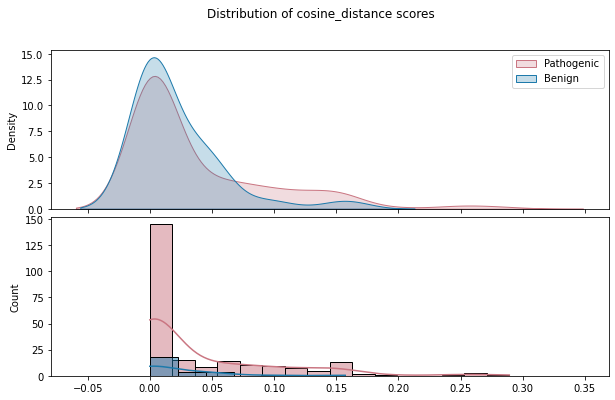

In [42]:
plot_patho_benign(metric="cosine_distance")

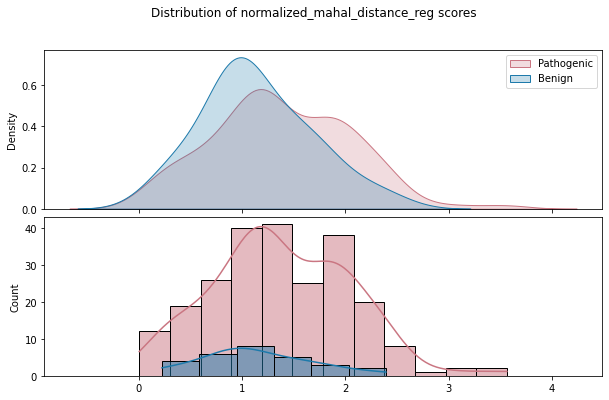

In [43]:
plot_patho_benign(metric="normalized_mahal_distance_reg")

## Log2FC distance

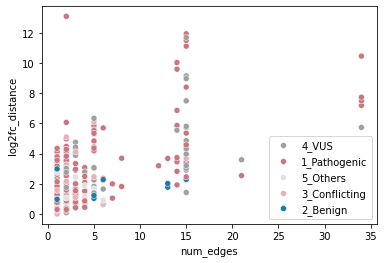

In [44]:
# plot the scores vs num_edges
sns.scatterplot(data=orf_distances.to_pandas(), x="num_edges", y="log2fc_distance", hue="clinvar_clnsig_clean", palette=palette_dict["clinvar_clnsig_clean_pillar"])
# plt.axhline(y=0.16, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
plt.legend()
plt.show()

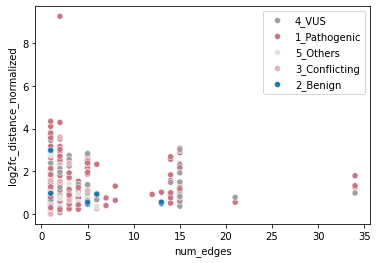

In [45]:
# Correlated between the num_edges -> need to normalize by num_edges

orf_distances = orf_distances.with_columns(
    (pl.col("log2fc_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("log2fc_distance_normalized")
)

sns.scatterplot(data=orf_distances.to_pandas(), x="num_edges", y="log2fc_distance_normalized", hue="clinvar_clnsig_clean", palette=palette_dict["clinvar_clnsig_clean_pillar"])
plt.legend()
plt.show()

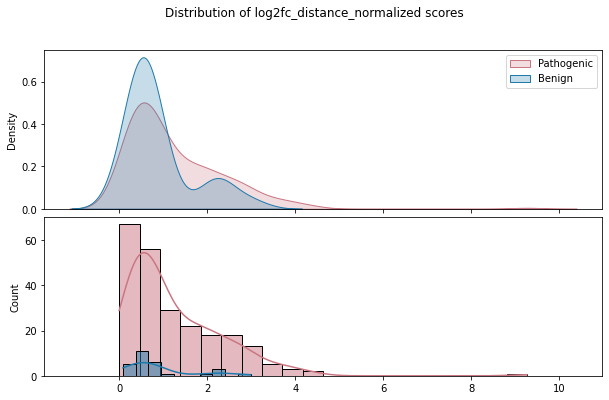

In [46]:
plot_patho_benign(metric="log2fc_distance_normalized")

## mean log2fc

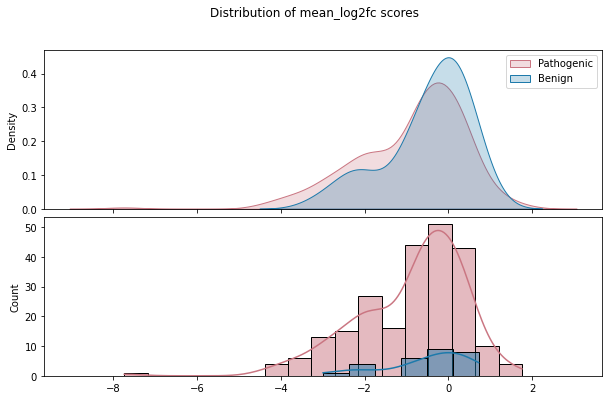

In [47]:
plot_patho_benign(metric="mean_log2fc")

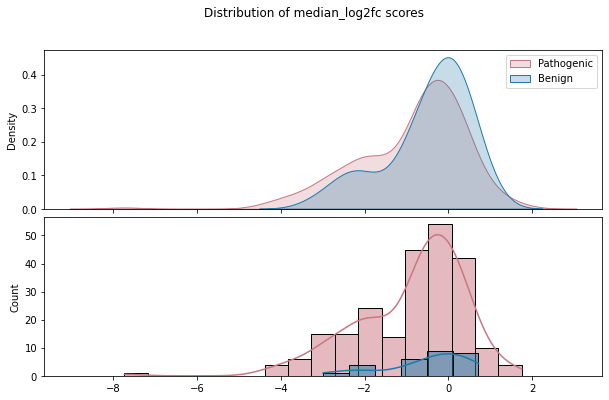

In [48]:
plot_patho_benign(metric="median_log2fc")

## Only 3 AT

In [49]:
# Create profiles_3at for each profiled gene

profiles_3at = dict()
shape_summary = []
for gene in genes:
    gene_scores = summed_scores.filter((pl.col("db_orf_id") == gene) &
                                       (pl.col("3at_consensus_score").is_not_null()))
    duplicates = gene_scores.group_by(["ad_orf_id", "db_mut_id"]).len().filter(pl.col("len") > 1)
    profile = gene_scores.pivot(
                values="3at_consensus_score",
                index="ad_orf_id",
                on="db_mut_id"
            )
    profiles_3at[gene] = profile

    shape_summary.append({
        "gene": gene,
        "n_interactors": profile.height,
        "n_alleles": profile.width
    })

shape_summary = pl.DataFrame(shape_summary)

In [50]:
zero_col = "0"

orf_distances_3at = []


for orf, profile in profiles_3at.items():
    
    columns = [col for col in profile.columns if col != "ad_orf_id"]
    
    profile = profile.filter(~pl.col("0").is_null())

    # "impute" missing values as the mean for that variant
    profile_filled = profile.with_columns([
        pl.when(pl.col(col).is_null())
        .then(pl.col(col).mean())
        .otherwise(pl.col(col))
        .alias(col)
        for col in columns
    ])
    
    
    # print('db_orf_id', orf)
    
    # print(profile_filled)
    
    # compute distances
    distance_rows = []
    for col in columns:
        if col == zero_col:
            continue
        
        # Euclidean distance
        diff_squared = (profile_filled[col] - profile_filled[zero_col]) ** 2
        distances = np.sqrt(diff_squared.sum())
        
        log2dc_squared = (np.log2((profile_filled[col] + 0.0001) / (profile_filled[zero_col] + 0.0001))) ** 2
        log2dc_distance = np.sqrt(log2dc_squared.sum())

        # Cosine similarity
        wt = profile_filled.select(zero_col).to_numpy()
        var = profile_filled.select(col).to_numpy()
        
        
        # if wt.ndim == 1:
        #     wt = wt.reshape(-1, 1)
        # if var.ndim == 1:
        #     var = var.reshape(-1, 1)
        # cos_sim = cosine_similarity(wt.T, var.T)
        # cos_dist = 1 - cos_sim

        max_perturbation = (profile_filled[zero_col] - profile_filled[col]).max()
        max_perturbation_abs = abs(max_perturbation)
        max_perturbation_fold = (profile_filled[zero_col] / profile_filled[col]).max()
        # max_perturbation_fold = (profile_filled[col] / profile_filled[zero_col]).max()
        max_perturbation_fold_abs = abs(max_perturbation_fold)
        max_relative_perturbation = ((profile_filled[col] - profile_filled[zero_col]) / profile_filled[zero_col]).max()
        # Log2 fold change calculation
        max_log2_fold_change = np.log2(max_perturbation_fold) if max_perturbation_fold > 0 else np.log2(max_perturbation_fold + 0.0001)
        max_log2_fold_change_abs = abs(max_log2_fold_change) if max_log2_fold_change is not None else None

        
        
        
        # Node removal detection metrics
        # perturbations = profile_filled[zero_col] - profile_filled[col] 
        perturbations = profile_filled[col] -  profile_filled[zero_col] 
        relative_perturbations = perturbations / profile_filled[zero_col]
        # all_perturbations.append(relative_perturbations.to_list())
        # print('var', profile_filled[col])
        # print('wt', profile_filled[zero_col])
        # print('perturb',relative_perturbations)
        
        log2fc = np.log2((profile_filled[col] / profile_filled[zero_col]) + 0.0001)
        mean_log2fc = log2fc.mean()
        median_log2fc = log2fc.median()
        # all_log2s.append(log2fc.to_list())
        

        
        mean_wt = profile_filled[zero_col].mean()
        
        # if (relative_perturbations >5).any():
        #     print(db_orf_id, col)
        #     for a in relative_perturbations.to_list():
        #         print(a)
        #     print('WARNING: relative perturbations > 5, check data')

        # Check if all edges are severely perturbed
        severe_perturbation_threshold = 0.50  # 50% decrease
        low_threshold = 0.25 # 10% decrease
        all_edges_perturbed = (relative_perturbations <= -severe_perturbation_threshold).all()
        # print('all_edges_perturbed', all_edges_perturbed)
        fraction_severely_perturbed = (relative_perturbations <= -severe_perturbation_threshold).mean()
        
        no_edges_perturbed = (relative_perturbations > -low_threshold).all()
        
        perturb_list = []
        
        for perturb in relative_perturbations.to_list():
            if perturb <= -severe_perturbation_threshold:
                perturb_list.append('perturbed')
            elif perturb > -low_threshold:
                perturb_list.append('not_perturbed')
            else:
                perturb_list.append('inconclusive')
                
        
        
        inconclusive = (
            (relative_perturbations <= -low_threshold) & 
            (relative_perturbations > -severe_perturbation_threshold)
        ).all()
        
        log2fc_tresh = -1
        
        
        log2fc_all_perturbed = (log2fc <= log2fc_tresh).all()
        log2fc_no_perturbed = (log2fc > log2fc_tresh).all()  # corresponds to <20% decrease
        # log2fc fraction of edges perturbed
        fraction_log2fc_perturbed = (log2fc <= log2fc_tresh).mean()


        # Mean perturbation across all edges
        mean_perturbation = perturbations.mean()
        mean_relative_perturbation = relative_perturbations.mean()

        # Standard deviation of perturbations (low = uniform perturbation)
        std_relative_perturbation = relative_perturbations.std()

        # Minimum edge value (close to 0 = complete loss)
        min_edge_value = profile_filled[col].min()
        min_relative_edge_value = (profile_filled[col] / profile_filled[zero_col]).min()

        # Mahalanobis distance
        try:
            # Calculate covariance matrix from all profile
            profile_matrix = profile_filled.select([col2 for col2 in columns]).to_numpy().T
            cov_matrix = np.cov(profile_matrix)
            
            # Use pseudo-inverse for numerical stability
            inv_cov_matrix = pinv(cov_matrix)
            
            wt_profile = profile_filled.select(zero_col).to_numpy().flatten()
            var_profile = profile_filled.select(col).to_numpy().flatten()
            
            mahal_distance = mahalanobis(var_profile, wt_profile, inv_cov_matrix)
            # print('mahal_distance', mahal_distance, "for", orf, col)
        
        except:
            # Fallback if covariance matrix is singular
            mahal_distance = None
            # print(profile_matrix)
            # print(cov_matrix)
            

        # In your Mahalanobis calculation:
        try:
            profile_matrix = profile_filled.select([col2 for col2 in columns]).to_numpy().T
            
            # Use regularized covariance instead
            lw = LedoitWolf()
            reg_cov = lw.fit(profile_matrix).covariance_
            
            wt_profile = profile_filled.select(zero_col).to_numpy().flatten()
            var_profile = profile_filled.select(col).to_numpy().flatten()
            
            mahal_distance_reg = mahalanobis(var_profile, wt_profile, pinv(reg_cov))
        except Exception as e:
            mahal_distance_reg = None
            # print(f"Mahalanobis failed for {orf}: {e}")
            

        distance_rows.append({
            "db_orf_id": orf,
            "db_mut_id": int(col),
            "euclid_distance": distances,
            "log2fc_distance": log2dc_distance,
            "max_perturbation": max_perturbation,
            "max_relative_perturbation": max_relative_perturbation,
            "max_perturbation_abs": max_perturbation_abs,
            "max_perturbation_fold": max_perturbation_fold,
            "max_perturbation_fold_abs": max_perturbation_fold_abs,
            "max_log2_fold_change": max_log2_fold_change,
            "max_log2_fold_change_abs": max_log2_fold_change_abs,
            "mahalanobis_distance": mahal_distance,
            "mahalanobis_distance_reg": mahal_distance_reg,
            # "cosine_distance": cos_dist,
            "mean_log2fc": mean_log2fc,
            "median_log2fc": median_log2fc,
            "num_edges": profile.shape[0],
            "all_edges_severely_perturbed": all_edges_perturbed,
            "fraction_severely_perturbed": fraction_severely_perturbed,
            "mean_perturbation": mean_perturbation,
            "mean_relative_perturbation": mean_relative_perturbation,
            "std_relative_perturbation": std_relative_perturbation,
            "min_edge_value": min_edge_value,
            "min_relative_edge_value": min_relative_edge_value,
            'no_edges_perturbed': no_edges_perturbed,
            'inconclusive': inconclusive,
            "mean_wt": mean_wt,
            "log2fc_perturbed": log2fc_all_perturbed,
            "log2fc_no_perturbed": log2fc_no_perturbed,
            "fraction_log2fc_perturbed": fraction_log2fc_perturbed,
        })


    result_profile = pl.DataFrame(distance_rows)
    orf_distances_3at.append(result_profile)


# concatentate and normalize wrt dimensionality
orf_distances_3at = pl.concat(orf_distances_3at, how="vertical_relaxed")
orf_distances_3at = orf_distances_3at.with_columns(
    (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
    (pl.col("mahalanobis_distance_reg") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_mahal_distance_reg"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
)

orf_distances_3at = orf_distances_3at.with_columns(
    (pl.col("normalized_euclid_distance") / pl.col("normalized_euclid_distance").max()).alias("normalized_euclid_distance_normalized"),
)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/641410526.py:138: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/641410526.py:138: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWa

In [51]:
# append metadata and write out scores
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id")
)

orf_distances_3at = orf_distances_3at.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")

# Drop alleles that were tested multiple times, keep only one (the one with the highest db_mut_id, which should be the most recent)
# Cast to int for sorting
orf_distances_3at = orf_distances_3at.with_columns(
    pl.col("db_mut_id").cast(pl.Int64).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.Int64).alias("db_orf_id")
)

orf_distances_3at = orf_distances_3at.sort("db_mut_id", descending=True).unique(subset=["allele_0"], keep="first")
orf_distances_3at

db_orf_id,db_mut_id,euclid_distance,log2fc_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,mean_log2fc,median_log2fc,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str
11805,2157,141.210115,0.221554,115.992487,-0.065398,115.992487,1.14783,1.14783,0.19891,0.19891,null,0.306617,-0.148083,-0.148083,2,false,0.0,-98.264219,-0.097095,0.044826,784.63205,0.871209,true,false,1066.046936,false,true,0.0,99.85063,0.216811,0.055407,"""SMAD3""","""Glu284Gln""","""850G>C""","""ENSG00000166949""","""Edgotyping3""","""4_VUS""",null,2.0,"""SMAD3_Glu284Gln"""
70497,3889,529.20331,0.495892,-529.20331,0.410192,529.20331,0.709123,0.709123,-0.495892,0.495892,null,1.033856,0.495994,0.495994,1,false,0.0,529.20331,0.410192,null,1819.33799,1.410192,true,false,1290.13468,false,true,0.0,529.20331,1.033856,0.293653,"""AGXT""","""Arg381Lys""","""1142G>A""","""ENSG00000172482""","""Edgotyping3""","""3_Conflicting""",0.000484,1.0,"""AGXT_Arg381Lys"""
143,213584,618.994358,0.807027,618.994358,-0.428442,618.994358,1.749603,1.749603,0.807027,0.807027,null,2.0,-0.806775,-0.806775,1,false,0.0,-618.994358,-0.428442,null,825.763425,0.571558,false,true,1444.757784,false,true,0.0,618.994358,2.0,0.343477,"""EZH2""","""Arg684Cys""","""2050C>T""","""ENSG00000106462""","""CEGS2""","""1_Pathogenic""",null,2.0,"""EZH2_Arg684Cys"""
2920,214424,1148.336289,1.50131,-264.727788,1.035672,264.727788,0.814929,0.814929,-0.295254,0.295254,null,2.773399,0.682692,0.704911,4,false,0.0,536.679272,0.642592,0.401689,1430.410832,1.227101,true,false,942.096274,false,true,0.0,574.168144,1.386699,0.318604,"""GFAP""","""Lys236Thr""","""707A>C""","""ENSG00000131095""","""CEGS2""","""5_Others""",null,null,"""GFAP_Lys236Thr"""
4723,201724,925.872551,1.110323,904.676828,-0.148271,904.676828,2.12272,2.12272,1.085914,1.085914,null,1.653854,-0.658486,-0.658486,2,false,0.5,-550.826762,-0.338589,0.26915,805.790558,0.471094,false,false,1519.479138,false,false,0.5,654.69076,1.169452,0.363285,"""TPM1""","""Lys15Asn""","""45G>T""","""ENSG00000140416""","""CEGS2""","""3_Conflicting""",null,1.0,"""TPM1_Lys15Asn"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
54308,3142,327.401527,0.456666,327.401527,-0.271332,327.401527,1.372367,1.372367,0.456666,0.456666,null,0.96576,-0.456468,-0.456468,1,false,0.0,-327.401527,-0.271332,null,879.244255,0.728668,false,true,1206.645782,false,true,0.0,327.401527,0.96576,0.181674,"""PKP2""","""Asp26Asn""","""76G>A""","""ENSG00000057294""","""Edgotyping3""","""2_Benign""",null,2.0,"""PKP2_Asp26Asn"""
2920,214427,412.780867,0.62862,76.212959,0.424614,76.212959,1.069954,1.069954,0.097549,0.097549,null,1.310276,0.228021,0.249403,4,false,0.0,147.373812,0.184165,0.200493,874.570617,0.934619,true,false,942.096274,false,true,0.0,206.390433,0.655138,0.114525,"""GFAP""","""Lys279Glu""","""835A>G""","""ENSG00000131095""","""CEGS2""","""5_Others""",null,null,"""GFAP_Lys279Glu"""
2713,200824,1219.518696,1.699718,407.089665,0.96314,407.089665,1.427648,1.427648,0.513641,0.513641,null,4.564167,0.130267,0.129326,15,false,0.0,68.899814,0.143657,0.370457,951.926059,0.700453,false,false,1167.574497,false,true,0.0,314.878373,1.178463,0.174725,"""MLH1""","""Ser106Arg""","""318C>G""","""ENSG00000076242""","""CEGS2""

In [52]:
orf_distances_3at = orf_distances_3at.with_columns(
    (pl.col("log2fc_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("log2fc_distance_normalized")
)

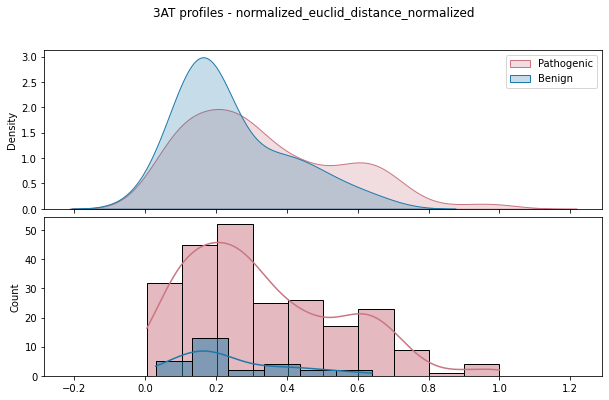

In [53]:
plot_patho_benign(scores=orf_distances_3at, metric="normalized_euclid_distance_normalized", title=f"3AT profiles - normalized_euclid_distance_normalized")

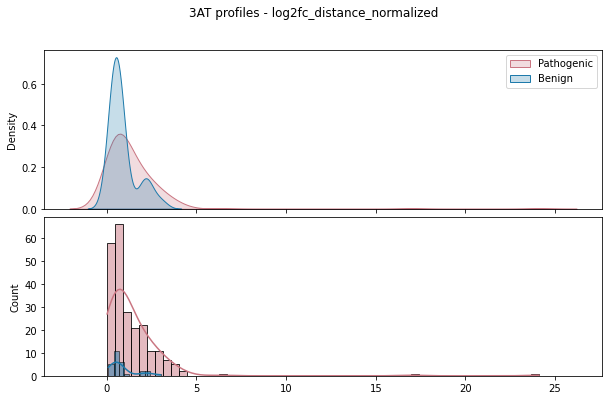

In [54]:
plot_patho_benign(scores=orf_distances_3at, metric="log2fc_distance_normalized", title=f"3AT profiles - log2fc_distance_normalized")

## Only LWA

In [55]:
# Create profiles_lwa for each profiled gene

profiles_lwa = dict()
shape_summary = []
for gene in genes:
    gene_scores = summed_scores.filter((pl.col("db_orf_id") == gene) &
                                       (pl.col("lwa_consensus_score").is_not_null()))
    duplicates = gene_scores.group_by(["ad_orf_id", "db_mut_id"]).len().filter(pl.col("len") > 1)
    profile = gene_scores.pivot(
                values="lwa_consensus_score",
                index="ad_orf_id",
                on="db_mut_id"
            )
    profiles_lwa[gene] = profile

    shape_summary.append({
        "gene": gene,
        "n_interactors": profile.height,
        "n_alleles": profile.width
    })

shape_summary = pl.DataFrame(shape_summary)

In [56]:
zero_col = "0"

orf_distances_lwa = []


for orf, profile in profiles_lwa.items():
    
    columns = [col for col in profile.columns if col != "ad_orf_id"]
    
    if "0" not in columns:
        print(f"Skipping {orf} as no WT (0) column found")
        continue
    
    profile = profile.filter(~pl.col("0").is_null())

    # "impute" missing values as the mean for that variant
    profile_filled = profile.with_columns([
        pl.when(pl.col(col).is_null())
        .then(pl.col(col).mean())
        .otherwise(pl.col(col))
        .alias(col)
        for col in columns
    ])
    
    
    # print('db_orf_id', orf)
    
    # print(profile_filled)
    
    # compute distances
    distance_rows = []
    for col in columns:
        if col == zero_col:
            continue
        
        # Euclidean distance
        diff_squared = (profile_filled[col] - profile_filled[zero_col]) ** 2
        distances = np.sqrt(diff_squared.sum())
        
        log2dc_squared = (np.log2((profile_filled[col] + 0.0001) / (profile_filled[zero_col] + 0.0001))) ** 2
        log2dc_distance = np.sqrt(log2dc_squared.sum())

        # Cosine similarity
        wt = profile_filled.select(zero_col).to_numpy()
        var = profile_filled.select(col).to_numpy()
        
        
        # if wt.ndim == 1:
        #     wt = wt.reshape(-1, 1)
        # if var.ndim == 1:
        #     var = var.reshape(-1, 1)
        # cos_sim = cosine_similarity(wt.T, var.T)
        # cos_dist = 1 - cos_sim
        
        cos_dist = None

        max_perturbation = (profile_filled[zero_col] - profile_filled[col]).max()
        max_perturbation_abs = abs(max_perturbation)
        max_perturbation_fold = (profile_filled[zero_col] / profile_filled[col]).max()
        # max_perturbation_fold = (profile_filled[col] / profile_filled[zero_col]).max()
        max_perturbation_fold_abs = abs(max_perturbation_fold)
        max_relative_perturbation = ((profile_filled[col] - profile_filled[zero_col]) / profile_filled[zero_col]).max()
        # Log2 fold change calculation
        max_log2_fold_change = np.log2(max_perturbation_fold) if max_perturbation_fold > 0 else np.log2(max_perturbation_fold + 0.0001)
        max_log2_fold_change_abs = abs(max_log2_fold_change) if max_log2_fold_change is not None else None

        
        
        
        # Node removal detection metrics
        # perturbations = profile_filled[zero_col] - profile_filled[col] 
        perturbations = profile_filled[col] -  profile_filled[zero_col] 
        relative_perturbations = perturbations / profile_filled[zero_col]
        # all_perturbations.append(relative_perturbations.to_list())
        # print('var', profile_filled[col])
        # print('wt', profile_filled[zero_col])
        # print('perturb',relative_perturbations)
        
        log2fc = np.log2((profile_filled[col] / profile_filled[zero_col]) + 0.0001)
        mean_log2fc = log2fc.mean()
        median_log2fc = log2fc.median()
        # all_log2s.append(log2fc.to_list())
        

        
        mean_wt = profile_filled[zero_col].mean()
        
        # if (relative_perturbations >5).any():
        #     print(db_orf_id, col)
        #     for a in relative_perturbations.to_list():
        #         print(a)
        #     print('WARNING: relative perturbations > 5, check data')

        # Check if all edges are severely perturbed
        severe_perturbation_threshold = 0.50  # 50% decrease
        low_threshold = 0.25 # 10% decrease
        all_edges_perturbed = (relative_perturbations <= -severe_perturbation_threshold).all()
        # print('all_edges_perturbed', all_edges_perturbed)
        fraction_severely_perturbed = (relative_perturbations <= -severe_perturbation_threshold).mean()
        
        no_edges_perturbed = (relative_perturbations > -low_threshold).all()
        
        perturb_list = []
        
        for perturb in relative_perturbations.to_list():
            if perturb <= -severe_perturbation_threshold:
                perturb_list.append('perturbed')
            elif perturb > -low_threshold:
                perturb_list.append('not_perturbed')
            else:
                perturb_list.append('inconclusive')
                
        
        
        inconclusive = (
            (relative_perturbations <= -low_threshold) & 
            (relative_perturbations > -severe_perturbation_threshold)
        ).all()
        
        log2fc_tresh = -1
        
        
        log2fc_all_perturbed = (log2fc <= log2fc_tresh).all()
        log2fc_no_perturbed = (log2fc > log2fc_tresh).all()  # corresponds to <20% decrease
        # log2fc fraction of edges perturbed
        fraction_log2fc_perturbed = (log2fc <= log2fc_tresh).mean()


        # Mean perturbation across all edges
        mean_perturbation = perturbations.mean()
        mean_relative_perturbation = relative_perturbations.mean()

        # Standard deviation of perturbations (low = uniform perturbation)
        std_relative_perturbation = relative_perturbations.std()

        # Minimum edge value (close to 0 = complete loss)
        min_edge_value = profile_filled[col].min()
        min_relative_edge_value = (profile_filled[col] / profile_filled[zero_col]).min()

        # Mahalanobis distance
        try:
            # Calculate covariance matrix from all profile
            profile_matrix = profile_filled.select([col2 for col2 in columns]).to_numpy().T
            cov_matrix = np.cov(profile_matrix)
            
            # Use pseudo-inverse for numerical stability
            inv_cov_matrix = pinv(cov_matrix)
            
            wt_profile = profile_filled.select(zero_col).to_numpy().flatten()
            var_profile = profile_filled.select(col).to_numpy().flatten()
            
            mahal_distance = mahalanobis(var_profile, wt_profile, inv_cov_matrix)
            # print('mahal_distance', mahal_distance, "for", orf, col)
        
        except:
            # Fallback if covariance matrix is singular
            mahal_distance = None
            # print(profile_matrix)
            # print(cov_matrix)
            

        # In your Mahalanobis calculation:
        try:
            profile_matrix = profile_filled.select([col2 for col2 in columns]).to_numpy().T
            
            # Use regularized covariance instead
            lw = LedoitWolf()
            reg_cov = lw.fit(profile_matrix).covariance_
            
            wt_profile = profile_filled.select(zero_col).to_numpy().flatten()
            var_profile = profile_filled.select(col).to_numpy().flatten()
            
            mahal_distance_reg = mahalanobis(var_profile, wt_profile, pinv(reg_cov))
        except Exception as e:
            mahal_distance_reg = None
            # print(f"Mahalanobis failed for {orf}: {e}")
            

        distance_rows.append({
            "db_orf_id": orf,
            "db_mut_id": int(col),
            "euclid_distance": distances,
            "log2fc_distance": log2dc_distance,
            "max_perturbation": max_perturbation,
            "max_relative_perturbation": max_relative_perturbation,
            "max_perturbation_abs": max_perturbation_abs,
            "max_perturbation_fold": max_perturbation_fold,
            "max_perturbation_fold_abs": max_perturbation_fold_abs,
            "max_log2_fold_change": max_log2_fold_change,
            "max_log2_fold_change_abs": max_log2_fold_change_abs,
            "mahalanobis_distance": mahal_distance,
            "mahalanobis_distance_reg": mahal_distance_reg,
            "cosine_distance": cos_dist,
            "mean_log2fc": mean_log2fc,
            "median_log2fc": median_log2fc,
            "num_edges": profile.shape[0],
            "all_edges_severely_perturbed": all_edges_perturbed,
            "fraction_severely_perturbed": fraction_severely_perturbed,
            "mean_perturbation": mean_perturbation,
            "mean_relative_perturbation": mean_relative_perturbation,
            "std_relative_perturbation": std_relative_perturbation,
            "min_edge_value": min_edge_value,
            "min_relative_edge_value": min_relative_edge_value,
            'no_edges_perturbed': no_edges_perturbed,
            'inconclusive': inconclusive,
            "mean_wt": mean_wt,
            "log2fc_perturbed": log2fc_all_perturbed,
            "log2fc_no_perturbed": log2fc_no_perturbed,
            "fraction_log2fc_perturbed": fraction_log2fc_perturbed,
        })


    result_profile = pl.DataFrame(distance_rows)
    orf_distances_lwa.append(result_profile)


orf_distances_lwa = [df for df in orf_distances_lwa if df.shape[0] > 0]
# concatentate and normalize wrt dimensionality
orf_distances_lwa = pl.concat(orf_distances_lwa, how="vertical_relaxed")
orf_distances_lwa = orf_distances_lwa.with_columns(
    (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
    (pl.col("mahalanobis_distance_reg") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_mahal_distance_reg"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
)

orf_distances_lwa = orf_distances_lwa.with_columns(
    (pl.col("normalized_euclid_distance") / pl.col("normalized_euclid_distance").max()).alias("normalized_euclid_distance_normalized"),
)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/4165117917.py:144: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/4165117917.py:144: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: Runtime

Skipping 3689 as no WT (0) column found
Skipping 4692 as no WT (0) column found


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/4165117917.py:144: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/4165117917.py:144: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: Runtime

Skipping 7215 as no WT (0) column found
Skipping 7465 as no WT (0) column found


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/4165117917.py:144: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/4165117917.py:144: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: Runtime

In [57]:
# append metadata and write out scores
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id")
)

orf_distances_lwa = orf_distances_lwa.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")

# Drop alleles that were tested multiple times, keep only one (the one with the highest db_mut_id, which should be the most recent)
# Cast to int for sorting
orf_distances_lwa = orf_distances_lwa.with_columns(
    pl.col("db_mut_id").cast(pl.Int64).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.Int64).alias("db_orf_id")
)

orf_distances_lwa = orf_distances_lwa.sort("db_mut_id", descending=True).unique(subset=["allele_0"], keep="first")
orf_distances_lwa

db_orf_id,db_mut_id,euclid_distance,log2fc_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,cosine_distance,mean_log2fc,median_log2fc,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,null,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str
5066,201832,63.468916,0.434999,62.4317,-0.011977,62.4317,1.348391,1.348391,0.431238,0.431238,null,1.406388,null,NaN,NaN,11,false,0.0,-7.141177,NaN,NaN,0.0,0.741625,false,false,100.064769,false,true,0.0,19.136598,0.424042,0.031681,"""BAG3""","""Pro380Ser""","""1138C>T""","""ENSG00000151929""","""CEGS2""","""2_Benign""",0.000499,2.0,"""BAG3_Pro380Ser"""
70497,3818,323.731377,2.135092,-323.731377,3.392655,323.731377,0.227653,0.227653,-2.135093,2.135093,null,1.831106,null,2.135126,2.135126,1,false,0.0,323.731377,3.392655,null,419.152621,4.392655,true,false,95.421243,false,true,0.0,323.731377,1.831106,0.535948,"""AGXT""","""Asp129His""","""385G>C""","""ENSG00000172482""","""Edgotyping3""","""4_VUS""",0.000117,2.0,"""AGXT_Asp129His"""
8999,203015,28.708824,18.13114,-28.708824,inf,28.708824,0.0,0.0,-13.287712,13.287712,null,1.237675,null,inf,inf,1,false,0.0,28.708824,inf,null,28.708824,inf,true,false,0.0,false,true,0.0,28.708824,1.237675,0.047528,"""TTR""","""Ala129Val""","""386C>T""","""ENSG00000118271""","""CEGS2""","""4_VUS""",0.00001,2.0,"""TTR_Ala129Val"""
4870,215274,304.812719,1.224167,253.392982,0.242267,253.392982,2.027839,2.027839,1.019943,1.019943,null,2.491914,null,-0.435544,-0.600072,3,false,0.333333,-128.702347,-0.201659,0.39336,171.179088,0.493136,false,false,375.232252,false,false,0.333333,175.983705,1.438707,0.291347,"""KRT6A""","""Asn171Asp""","""511A>G""","""ENSG00000205420""","""CEGS2""","""1_Pathogenic""",null,1.0,"""KRT6A_Asn171Asp"""
70497,3805,95.421243,19.863952,95.421243,-1.0,95.421243,inf,inf,inf,inf,null,0.539727,null,-13.287712,-13.287712,1,true,1.0,-95.421243,-1.0,null,0.0,0.0,false,false,95.421243,true,false,1.0,95.421243,0.539727,0.157973,"""AGXT""","""Ala85Asp""","""254C>A""","""ENSG00000172482""","""Edgotyping3""","""1_Pathogenic""",null,null,"""AGXT_Ala85Asp"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
13320,204010,244.449349,1.476055,-244.449349,1.781871,244.449349,0.35947,0.35947,-1.476055,1.476055,null,2.118666,null,1.476107,1.476107,1,false,0.0,244.449349,1.781871,null,381.63628,2.781871,true,false,137.186932,false,true,0.0,244.449349,2.118666,0.404694,"""VHL""","""Leu122Pro""","""365T>C""","""ENSG00000134086""","""CEGS2""","""1_Pathogenic""",null,2.0,"""VHL_Leu122Pro"""
70497,205585,95.421243,19.863952,95.421243,-1.0,95.421243,inf,inf,inf,inf,null,0.539727,null,-13.287712,-13.287712,1,true,1.0,-95.421243,-1.0,null,0.0,0.0,false,false,95.421243,true,false,1.0,95.421243,0.539727,0.157973,"""AGXT""","""Gly156Arg""","""466G>A""","""ENSG00000172482""","""Edgotyping3""","""1_Pathogenic""",0.000015,2.0,"""AGXT_Gly156Arg"""
5723,201967,131.074361,20.953274,89.029413,123.425157,89.029413,inf,inf,inf,inf,null,3.917596,null,-3.164288,-3.164288,2,false,0.5,3.584804,61.212578,87.981872,0.0,0.0,false,false,44.904413,false,false,0.5,92.683569,2.770159,0.153441,"""SFTPC""","""Leu194Pro""","""581T>C""","""ENSG00000168484""","""CEGS2""","""1_Pathogenic""",null,null,"""SFTPC_Leu194Pro"""


In [58]:
orf_distances_lwa = orf_distances_lwa.with_columns(
    (pl.col("log2fc_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("log2fc_distance_normalized")
)


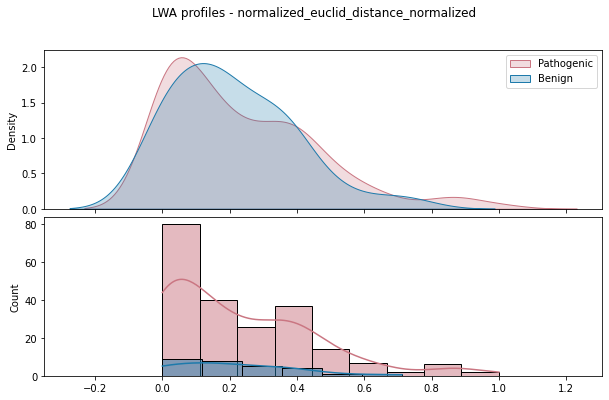

In [59]:
plot_patho_benign(scores=orf_distances_lwa, metric="normalized_euclid_distance_normalized", title=f"LWA profiles - normalized_euclid_distance_normalized")

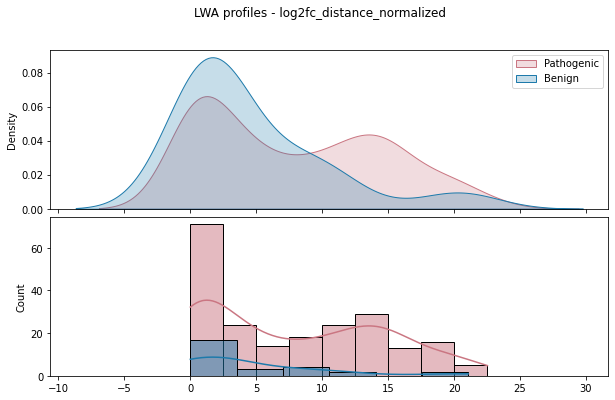

In [60]:
plot_patho_benign(scores=orf_distances_lwa, metric="log2fc_distance_normalized", title=f"LWA profiles - log2fc_distance_normalized")

In [61]:
for a in orf_distances_lwa:
    print(a.shape)

(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)
(447,)


## 3AT weighted

In [62]:
# Create profiles_3at_weighted for each profiled gene

profiles_3at_weighted = dict()
shape_summary = []
for gene in genes:
    gene_scores = summed_scores.filter((pl.col("db_orf_id") == gene) &
                                       (pl.col("3at_weighted_consensus_score").is_not_null()))
    duplicates = gene_scores.group_by(["ad_orf_id", "db_mut_id"]).len().filter(pl.col("len") > 1)
    profile = gene_scores.pivot(
                values="3at_weighted_consensus_score",
                index="ad_orf_id",
                on="db_mut_id"
            )
    profiles_3at_weighted[gene] = profile

    shape_summary.append({
        "gene": gene,
        "n_interactors": profile.height,
        "n_alleles": profile.width
    })

shape_summary = pl.DataFrame(shape_summary)

In [63]:
# zero_col = "0"

# orf_distances_3at_weight = []


# for orf, profile in profiles_3at_weighted.items():
    
#     columns = [col for col in profile.columns if col != "ad_orf_id"]
    
#     if "0" not in columns:
#         print(f"Skipping {orf} as no WT (0) column found")
#         continue
    
#     profile = profile.filter(~pl.col("0").is_null())

#     # "impute" missing values as the mean for that variant
#     profile_filled = profile.with_columns([
#         pl.when(pl.col(col).is_null())
#         .then(pl.col(col).mean())
#         .otherwise(pl.col(col))
#         .alias(col)
#         for col in columns
#     ])
    
    
#     print('db_orf_id', orf)
    
#     print(profile_filled)
    
#     # compute distances
#     distance_rows = []
#     for col in columns:
#         if col == zero_col:
#             continue
        
#         # Euclidean distance
#         diff_squared = (profile_filled[col] - profile_filled[zero_col]) ** 2
#         distances = np.sqrt(diff_squared.sum())
        
#         log2dc_squared = (np.log2((profile_filled[col] + 0.0001) / (profile_filled[zero_col] + 0.0001))) ** 2
#         log2dc_distance = np.sqrt(log2dc_squared.sum())

#         # Cosine similarity
#         wt = profile_filled.select(zero_col).to_numpy()
#         var = profile_filled.select(col).to_numpy()
        
        
#         # if wt.ndim == 1:
#         #     wt = wt.reshape(-1, 1)
#         # if var.ndim == 1:
#         #     var = var.reshape(-1, 1)
#         # cos_sim = cosine_similarity(wt.T, var.T)
#         # cos_dist = 1 - cos_sim
        
#         cos_dist = None

#         max_perturbation = (profile_filled[zero_col] - profile_filled[col]).max()
#         max_perturbation_abs = abs(max_perturbation)
#         max_perturbation_fold = (profile_filled[zero_col] / profile_filled[col]).max()
#         # max_perturbation_fold = (profile_filled[col] / profile_filled[zero_col]).max()
#         max_perturbation_fold_abs = abs(max_perturbation_fold)
#         max_relative_perturbation = ((profile_filled[col] - profile_filled[zero_col]) / profile_filled[zero_col]).max()
#         # Log2 fold change calculation
#         max_log2_fold_change = np.log2(max_perturbation_fold) if max_perturbation_fold > 0 else np.log2(max_perturbation_fold + 0.0001)
#         max_log2_fold_change_abs = abs(max_log2_fold_change) if max_log2_fold_change is not None else None

        
        
        
#         # Node removal detection metrics
#         # perturbations = profile_filled[zero_col] - profile_filled[col] 
#         perturbations = profile_filled[col] -  profile_filled[zero_col] 
#         relative_perturbations = perturbations / profile_filled[zero_col]
#         # all_perturbations.append(relative_perturbations.to_list())
#         # print('var', profile_filled[col])
#         # print('wt', profile_filled[zero_col])
#         # print('perturb',relative_perturbations)
        
#         log2fc = np.log2((profile_filled[col] / profile_filled[zero_col]) + 0.0001)
#         mean_log2fc = log2fc.mean()
#         median_log2fc = log2fc.median()
#         # all_log2s.append(log2fc.to_list())
        

        
#         mean_wt = profile_filled[zero_col].mean()
        
#         # if (relative_perturbations >5).any():
#         #     print(db_orf_id, col)
#         #     for a in relative_perturbations.to_list():
#         #         print(a)
#         #     print('WARNING: relative perturbations > 5, check data')

#         # Check if all edges are severely perturbed
#         severe_perturbation_threshold = 0.50  # 50% decrease
#         low_threshold = 0.25 # 10% decrease
#         all_edges_perturbed = (relative_perturbations <= -severe_perturbation_threshold).all()
#         # print('all_edges_perturbed', all_edges_perturbed)
#         fraction_severely_perturbed = (relative_perturbations <= -severe_perturbation_threshold).mean()
        
#         no_edges_perturbed = (relative_perturbations > -low_threshold).all()
        
#         perturb_list = []
        
#         for perturb in relative_perturbations.to_list():
#             if perturb <= -severe_perturbation_threshold:
#                 perturb_list.append('perturbed')
#             elif perturb > -low_threshold:
#                 perturb_list.append('not_perturbed')
#             else:
#                 perturb_list.append('inconclusive')
                
        
        
#         inconclusive = (
#             (relative_perturbations <= -low_threshold) & 
#             (relative_perturbations > -severe_perturbation_threshold)
#         ).all()
        
#         log2fc_tresh = -1
        
        
#         log2fc_all_perturbed = (log2fc <= log2fc_tresh).all()
#         log2fc_no_perturbed = (log2fc > log2fc_tresh).all()  # corresponds to <20% decrease
#         # log2fc fraction of edges perturbed
#         fraction_log2fc_perturbed = (log2fc <= log2fc_tresh).mean()


#         # Mean perturbation across all edges
#         mean_perturbation = perturbations.mean()
#         mean_relative_perturbation = relative_perturbations.mean()

#         # Standard deviation of perturbations (low = uniform perturbation)
#         std_relative_perturbation = relative_perturbations.std()

#         # Minimum edge value (close to 0 = complete loss)
#         min_edge_value = profile_filled[col].min()
#         min_relative_edge_value = (profile_filled[col] / profile_filled[zero_col]).min()

#         # Mahalanobis distance
#         try:
#             # Calculate covariance matrix from all profile
#             profile_matrix = profile_filled.select([col2 for col2 in columns]).to_numpy().T
#             cov_matrix = np.cov(profile_matrix)
            
#             # Use pseudo-inverse for numerical stability
#             inv_cov_matrix = pinv(cov_matrix)
            
#             wt_profile = profile_filled.select(zero_col).to_numpy().flatten()
#             var_profile = profile_filled.select(col).to_numpy().flatten()
            
#             mahal_distance = mahalanobis(var_profile, wt_profile, inv_cov_matrix)
#             # print('mahal_distance', mahal_distance, "for", orf, col)
        
#         except:
#             # Fallback if covariance matrix is singular
#             mahal_distance = None
#             # print(profile_matrix)
#             # print(cov_matrix)
            

#         # In your Mahalanobis calculation:
#         try:
#             profile_matrix = profile_filled.select([col2 for col2 in columns]).to_numpy().T
            
#             # Use regularized covariance instead
#             lw = LedoitWolf()
#             reg_cov = lw.fit(profile_matrix).covariance_
            
#             wt_profile = profile_filled.select(zero_col).to_numpy().flatten()
#             var_profile = profile_filled.select(col).to_numpy().flatten()
            
#             mahal_distance_reg = mahalanobis(var_profile, wt_profile, pinv(reg_cov))
#         except Exception as e:
#             mahal_distance_reg = None
#             # print(f"Mahalanobis failed for {orf}: {e}")
            

#         distance_rows.append({
#             "db_orf_id": orf,
#             "db_mut_id": int(col),
#             "euclid_distance": distances,
#             "log2fc_distance": log2dc_distance,
#             "max_perturbation": max_perturbation,
#             "max_relative_perturbation": max_relative_perturbation,
#             "max_perturbation_abs": max_perturbation_abs,
#             "max_perturbation_fold": max_perturbation_fold,
#             "max_perturbation_fold_abs": max_perturbation_fold_abs,
#             "max_log2_fold_change": max_log2_fold_change,
#             "max_log2_fold_change_abs": max_log2_fold_change_abs,
#             "mahalanobis_distance": mahal_distance,
#             "mahalanobis_distance_reg": mahal_distance_reg,
#             "cosine_distance": cos_dist,
#             "mean_log2fc": mean_log2fc,
#             "median_log2fc": median_log2fc,
#             "num_edges": profile.shape[0],
#             "all_edges_severely_perturbed": all_edges_perturbed,
#             "fraction_severely_perturbed": fraction_severely_perturbed,
#             "mean_perturbation": mean_perturbation,
#             "mean_relative_perturbation": mean_relative_perturbation,
#             "std_relative_perturbation": std_relative_perturbation,
#             "min_edge_value": min_edge_value,
#             "min_relative_edge_value": min_relative_edge_value,
#             'no_edges_perturbed': no_edges_perturbed,
#             'inconclusive': inconclusive,
#             "mean_wt": mean_wt,
#             "log2fc_perturbed": log2fc_all_perturbed,
#             "log2fc_no_perturbed": log2fc_no_perturbed,
#             "fraction_log2fc_perturbed": fraction_log2fc_perturbed,
#         })


#     result_profile = pl.DataFrame(distance_rows)
#     orf_distances_3at_weight.append(result_profile)


# orf_distances_3at_weight = [df for df in orf_distances_3at_weight if df.shape[0] > 0]
# # concatentate and normalize wrt dimensionality
# orf_distances_3at_weight = pl.concat(orf_distances_3at_weight, how="vertical_relaxed")
# orf_distances_3at_weight = orf_distances_3at_weight.with_columns(
#     (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
#     (pl.col("mahalanobis_distance_reg") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_mahal_distance_reg"),
#     pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
#     pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
# )

# orf_distances_3at_weight = orf_distances.with_columns(
#     (pl.col("normalized_euclid_distance") / pl.col("normalized_euclid_distance").max()).alias("normalized_euclid_distance_normalized"),
# )

In [64]:
# profiles_3at_weighted[2920]

In [65]:
summed_scores_pd = summed_scores.to_pandas()
summed_scores_pd['log2fc'] = [np.log2(var/wt) for var, wt in zip(summed_scores_pd['summed_consensus_score_normalized'], summed_scores_pd['wt_summed_score_normalized'])]
summed_scores_pd_pl = pl.from_pandas(summed_scores_pd)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/3702216332.py:2: RuntimeWarning: divide by zero encountered in log2
  summed_scores_pd['log2fc'] = [np.log2(var/wt) for var, wt in zip(summed_scores_pd['summed_consensus_score_normalized'], summed_scores_pd['wt_summed_score_normalized'])]


In [66]:
summed_scores_pd[summed_scores_pd.clinvar_clnsig_clean == '2_Benign'].symbol.unique()


array(['MLH1', 'STXBP1', 'BAG3', 'SMAD3', 'GRN', 'LITAF', 'AGXT', 'KRT8',
       'PKP2', 'AIPL1', 'MVK', 'KCNJ2', 'PCCA', 'ACSF3', 'VHL', 'TMEM43'],
      dtype=object)

path_thres: 2.6462261159646694


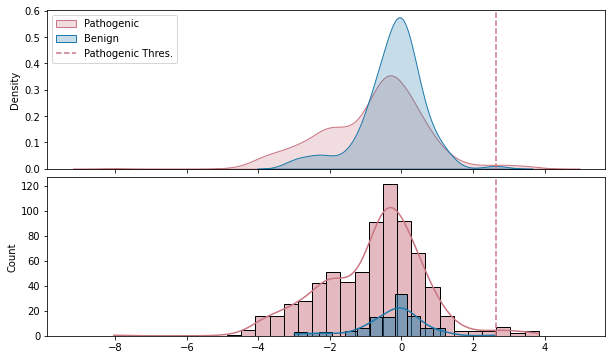

In [67]:

path_thres = summed_scores_pd_pl.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["log2fc"].max() + 0.016
print('path_thres:', path_thres)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=summed_scores_pd_pl.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["log2fc"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean_pillar"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=summed_scores_pd_pl.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["log2fc"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean_pillar"]["2_Benign"], fill=True, ax=axes[0])
axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean_pillar"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(summed_scores_pd_pl.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["log2fc"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean_pillar"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(summed_scores_pd_pl.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["log2fc"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean_pillar"]["2_Benign"], kde=True, ax=axes[1])
axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean_pillar"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
plt.subplots_adjust(hspace=.05)
# if title is not None:
    # plt.suptitle(title)
# else:
    # plt.suptitle(f"Distribution of {"log2fc"} summed_scores_pd_pl")
plt.show()

# Euclid per media then sum?

In [68]:
## Distance per medium then sum approach

# Create separate profiles for each medium
profiles_per_medium = {}
for medium in scoring_conditions:  # ["LWH1", "LWH10", "LWH25", "LWA"]
    profiles_per_medium[medium] = {}
    for gene in genes:
        gene_scores = summed_scores.filter(pl.col("db_orf_id") == gene)
        
        # Get the individual medium score
        if medium == "LWA":
            score_col = "lwa_consensus_score"
        elif medium == "LWH1":
            score_col = "lwh1_consensus_score"
        else:
            # For LWH10 and LWH25, we need to extract from original scores
            gene_scores_orig = scores.filter(
                (pl.col("db_orf_id") == gene) & 
                (pl.col("condition_name") == medium)
            )
            profile = gene_scores_orig.pivot(
                values="consensus_score",
                index="ad_orf_id", 
                on="db_mut_id"
            )
            
                    # has to have WT column
            if "0" not in profile.columns:
                continue
            
            # drop rows where col "0" is null
            # print(gene, medium)
            profile = profile.filter(~pl.col("0").is_null())
            
            profiles_per_medium[medium][gene] = profile
            continue
            
        # For LWA and LWH1, use the aggregated scores
        profile = gene_scores.pivot(
            values=score_col,
            index="ad_orf_id",
            on="db_mut_id"
        )
        
        # has to have WT column
        if "0" not in profile.columns:
            continue
        
        # drop rows where col "0" is null
        # print(gene, medium)
        profile = profile.filter(~pl.col("0").is_null())
        
        profiles_per_medium[medium][gene] = profile

# Now compute distances per medium, then sum
zero_col = "0"
orf_distances_per_medium_summed = []

for orf in genes:
    # Store distances for each medium for this ORF
    medium_distances = {}
    
    for medium in scoring_conditions:
        if orf not in profiles_per_medium[medium]:
            continue
            
        profile = profiles_per_medium[medium][orf]
        columns = [col for col in profile.columns if col != "ad_orf_id"]
        
        if orf == 8999:
            print(f"Profile for {orf} in medium {medium}:")
            print(profile)
        
        if zero_col not in columns:
            continue
            
        # Filter out rows where WT is null
        profile = profile.filter(~pl.col(zero_col).is_null())
        
        # Impute missing values
        profile_filled = profile.with_columns([
            pl.when(pl.col(col).is_null())
            .then(pl.col(col).mean())
            .otherwise(pl.col(col))
            .alias(col)
            for col in columns
        ])
        
        # Compute distances for this medium
        for col in columns:
            if col == zero_col:
                continue
            
            # check if variant column is all null
            if profile_filled[col].is_null().all():
                continue
                
            # Euclidean distance for this medium
            diff_squared = (profile_filled[col] - profile_filled[zero_col]) ** 2
            euclid_distance = np.sqrt(diff_squared.sum())
            if orf == 8999:# and col == '215290':
                print(f"Gene {orf}, Medium {medium}, Variant {col}, Euclid Distance: {euclid_distance}")
            
            # Store in nested dict: medium_distances[variant][medium] = distance
            if col not in medium_distances:
                medium_distances[col] = {}
            medium_distances[col][medium] = euclid_distance
    
    # Now sum distances across media for each variant
    distance_rows = []
    for variant_id, medium_dists in medium_distances.items():
        # Sum euclidean distances across available media
        summed_euclid_distance = sum(medium_dists.values())
        n_media_available = len(medium_dists.keys())
        
        # Get number of edges (use any available medium's profile)
        available_medium = list(medium_dists.keys())[0]
        num_edges = profiles_per_medium[available_medium][orf].shape[0]
        
        distance_rows.append({
            "db_orf_id": orf,
            "db_mut_id": int(variant_id),
            "summed_euclid_distance": summed_euclid_distance,
            "n_media_used": n_media_available,
            "num_edges": num_edges,
            "available_media": list(medium_dists.keys())
        })
    
    if distance_rows:
        result_profile = pl.DataFrame(distance_rows)
        orf_distances_per_medium_summed.append(result_profile)

# Concatenate and normalize
if orf_distances_per_medium_summed:
    orf_distances_per_medium_summed = pl.concat(orf_distances_per_medium_summed, how="vertical_relaxed")
    
    # Normalize by number of edges and number of media
    orf_distances_per_medium_summed = orf_distances_per_medium_summed.with_columns(
        (pl.col("summed_euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_summed_euclid_distance"),
        (pl.col("summed_euclid_distance") / (pl.col("num_edges").cast(pl.Float64).sqrt() * pl.col("n_media_used"))).alias("normalized_summed_euclid_distance_by_media"),
        pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
        pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    )
    
    # Append metadata
    metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
        "orf_id": "db_orf_id",
        "mut_id": "db_mut_id"
    }).with_columns(
        pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.String).alias("db_mut_id")
    )
    
    orf_distances_per_medium_summed = orf_distances_per_medium_summed.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
    
    # Cast back to int for sorting and deduplication
    orf_distances_per_medium_summed = orf_distances_per_medium_summed.with_columns(
        pl.col("db_mut_id").cast(pl.Int64).alias("db_mut_id"),
        pl.col("db_orf_id").cast(pl.Int64).alias("db_orf_id")
    )
    
    orf_distances_per_medium_summed = orf_distances_per_medium_summed.sort("db_mut_id", descending=True).unique(subset=["allele_0"], keep="first")
    
    print(f"Shape: {orf_distances_per_medium_summed.shape}")
    orf_distances_per_medium_summed
else:
    print("No valid data found for distance calculation")

Profile for 8999 in medium LWH1:
shape: (0, 18)
┌───────────┬────────┬────────┬────────┬───┬────────┬────────┬────────┬────────┐
│ ad_orf_id ┆ 202985 ┆ 203012 ┆ 203011 ┆ … ┆ 203002 ┆ 202991 ┆ 203005 ┆ 202990 │
│ ---       ┆ ---    ┆ ---    ┆ ---    ┆   ┆ ---    ┆ ---    ┆ ---    ┆ ---    │
│ i64       ┆ f64    ┆ f64    ┆ f64    ┆   ┆ f64    ┆ f64    ┆ f64    ┆ f64    │
╞═══════════╪════════╪════════╪════════╪═══╪════════╪════════╪════════╪════════╡
└───────────┴────────┴────────┴────────┴───┴────────┴────────┴────────┴────────┘
Profile for 8999 in medium LWH10:
shape: (1, 18)
┌───────────┬────────────┬───────────┬────────┬───┬────────────┬──────────┬───────────┬────────────┐
│ ad_orf_id ┆ 0          ┆ 203000    ┆ 203012 ┆ … ┆ 202979     ┆ 203008   ┆ 202989    ┆ 202991     │
│ ---       ┆ ---        ┆ ---       ┆ ---    ┆   ┆ ---        ┆ ---      ┆ ---       ┆ ---        │
│ i64       ┆ f64        ┆ f64       ┆ f64    ┆   ┆ f64        ┆ f64      ┆ f64       ┆ f64        │
╞═══════════╪

In [69]:
## Distance per medium then sum approach

# Create separate profiles for each medium
profiles_per_medium = {}
for medium in scoring_conditions:  # ["LWH1", "LWH10", "LWH25", "LWA"]
    profiles_per_medium[medium] = {}
    for gene in genes:
        gene_scores = summed_scores.filter(pl.col("db_orf_id") == gene)
        
        # Get the individual medium score
        if medium == "LWA":
            score_col = "lwa_consensus_score"
        elif medium == "LWH1":
            score_col = "lwh1_consensus_score"
        else:
            # For LWH10 and LWH25, we need to extract from original scores
            gene_scores_orig = scores.filter(
                (pl.col("db_orf_id") == gene) & 
                (pl.col("condition_name") == medium)
            )
            profile = gene_scores_orig.pivot(
                values="consensus_score",
                index="ad_orf_id", 
                on="db_mut_id"
            )
            
                    # has to have WT column
            if "0" not in profile.columns:
                continue
            
            # drop rows where col "0" is null
            # print(gene, medium)
            profile = profile.filter(~pl.col("0").is_null())
            
            profiles_per_medium[medium][gene] = profile
            continue
            
        # For LWA and LWH1, use the aggregated scores
        profile = gene_scores.pivot(
            values=score_col,
            index="ad_orf_id",
            on="db_mut_id"
        )
        
        # has to have WT column
        if "0" not in profile.columns:
            continue
        
        # drop rows where col "0" is null
        # print(gene, medium)
        profile = profile.filter(~pl.col("0").is_null())
        
        profiles_per_medium[medium][gene] = profile

# Now compute distances per medium, then sum
zero_col = "0"
orf_distances_per_medium_summed = []

for orf in genes:
    # Store distances for each medium for this ORF
    medium_distances = {}
    
    for medium in scoring_conditions:
        if orf not in profiles_per_medium[medium]:
            continue
            
        profile = profiles_per_medium[medium][orf]
        columns = [col for col in profile.columns if col != "ad_orf_id"]
        
        if zero_col not in columns:
            continue
            
        # Filter out rows where WT is null
        profile = profile.filter(~pl.col(zero_col).is_null())
        
        # Impute missing values
        profile_filled = profile.with_columns([
            pl.when(pl.col(col).is_null())
            .then(pl.col(col).mean())
            .otherwise(pl.col(col))
            .alias(col)
            for col in columns
        ])
        
        # Get the actual number of edges for this medium/gene combination
        num_edges_this_medium = profile_filled.shape[0]
        
        # Compute distances for this medium
        for col in columns:
            if col == zero_col:
                continue
                
            # Euclidean distance for this medium
            diff_squared = (profile_filled[col] - profile_filled[zero_col]) ** 2
            euclid_distance = np.sqrt(diff_squared.sum())
            
            # NORMALIZE BY ACTUAL EDGES USED IN THIS MEDIUM
            normalized_euclid_distance = euclid_distance / np.sqrt(num_edges_this_medium)
            
            # Store in nested dict: medium_distances[variant][medium] = {distance, normalized_distance, num_edges}
            if col not in medium_distances:
                medium_distances[col] = {}
            medium_distances[col][medium] = {
                'raw_distance': euclid_distance,
                'normalized_distance': normalized_euclid_distance,
                'num_edges': num_edges_this_medium
            }
    
    # Now sum normalized distances across media for each variant
    distance_rows = []
    for variant_id, medium_dists in medium_distances.items():
        # Sum NORMALIZED euclidean distances across available media
        summed_normalized_euclid_distance = sum([
            dist_info['normalized_distance'] for dist_info in medium_dists.values()
        ])
        
        # Also sum raw distances for comparison
        summed_raw_euclid_distance = sum([
            dist_info['raw_distance'] for dist_info in medium_dists.values()
        ])
        
        n_media_available = len(medium_dists.keys())
        
        # Get edge counts per medium
        edges_per_medium = {
            medium: dist_info['num_edges'] 
            for medium, dist_info in medium_dists.items()
        }
        
        distance_rows.append({
            "db_orf_id": orf,
            "db_mut_id": int(variant_id),
            "summed_normalized_euclid_distance": summed_normalized_euclid_distance,
            "summed_raw_euclid_distance": summed_raw_euclid_distance,
            "n_media_used": n_media_available,
            "available_media": list(medium_dists.keys()),
            "edges_per_medium": edges_per_medium,
            "total_edges_across_media": sum(edges_per_medium.values())
        })
    
    if distance_rows:
        result_profile = pl.DataFrame(distance_rows)
        orf_distances_per_medium_summed.append(result_profile)

# Concatenate and add final normalizations
if orf_distances_per_medium_summed:
    orf_distances_per_medium_summed = pl.concat(orf_distances_per_medium_summed, how="vertical_relaxed")
    
    # Add additional normalizations
    orf_distances_per_medium_summed = orf_distances_per_medium_summed.with_columns(
        # Normalize summed normalized distance by number of media used
        (pl.col("summed_normalized_euclid_distance") / pl.col("n_media_used")).alias("avg_normalized_euclid_distance"),
        pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
        pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    )
    
    # Append metadata
    metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
        "orf_id": "db_orf_id",
        "mut_id": "db_mut_id"
    }).with_columns(
        pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.String).alias("db_mut_id")
    )
    
    orf_distances_per_medium_summed = orf_distances_per_medium_summed.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
    
    # Cast back to int for sorting and deduplication
    orf_distances_per_medium_summed = orf_distances_per_medium_summed.with_columns(
        pl.col("db_mut_id").cast(pl.Int64).alias("db_mut_id"),
        pl.col("db_orf_id").cast(pl.Int64).alias("db_orf_id")
    )
    
    orf_distances_per_medium_summed = orf_distances_per_medium_summed.sort("db_mut_id", descending=True).unique(subset=["allele_0"], keep="first")
    
    print(f"Shape: {orf_distances_per_medium_summed.shape}")
    orf_distances_per_medium_summed
else:
    print("No valid data found for distance calculation")

Shape: (476, 18)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/2562765555.py:98: RuntimeWarning: invalid value encountered in scalar divide
  normalized_euclid_distance = euclid_distance / np.sqrt(num_edges_this_medium)


In [70]:
## Distance per medium then sum approach

# Create separate profiles for each medium
profiles_per_medium_original = {}
# Get the individual medium score - USE ORIGinalINAL SCORES FOR ALL MEDIA
for medium in scoring_conditions:
    profiles_per_medium_original[medium] = {}
    for gene in genes:
        # Use originalinal scores for ALL media consistently
        gene_scores_original = scores.filter(
            (pl.col("db_orf_id") == gene) & 
            (pl.col("condition_name") == medium)
        )
        profile = gene_scores_original.pivot(
            values="consensus_score",
            index="ad_orf_id", 
            on="db_mut_id"
        )
        
        # has to have WT column
        if "0" not in profile.columns:
            continue
        
        # drop rows where col "0" is null
        # print(gene, medium)
        profile = profile.filter(~pl.col("0").is_null())
        
        profiles_per_medium_original[medium][gene] = profile

# Now compute distances per medium, then sum
zero_col = "0"
orf_distances_per_medium_summed_original = []

for orf in genes:
    # Store distances for each medium for this ORF
    medium_distances = {}
    
    for medium in scoring_conditions:
        if orf not in profiles_per_medium_original[medium]:
            continue
            
        profile = profiles_per_medium_original[medium][orf]
        columns = [col for col in profile.columns if col != "ad_orf_id"]
        
        if orf == 3732:
            print(f"Profile for {orf} in medium {medium}:")
            print(profile)
        
        if zero_col not in columns:
            continue
            
        # Filter out rows where WT is null
        profile = profile.filter(~pl.col(zero_col).is_null())
        
        # Impute missing values
        profile_filled = profile.with_columns([
            pl.when(pl.col(col).is_null())
            .then(pl.col(col).mean())
            .otherwise(pl.col(col))
            .alias(col)
            for col in columns
        ])
        
        # Get the actual number of edges for this medium/gene combination
        num_edges_this_medium = profile_filled.shape[0]
        
        
        # Compute distances for this medium
        for col in columns:
            if col == zero_col:
                continue
                
            # Euclidean distance for this medium
            diff_squared = (profile_filled[col] - profile_filled[zero_col]) ** 2
            euclid_distance = np.sqrt(diff_squared.sum())
            if orf == 4870 and col == '215290':
                print(f"Gene {orf}, Medium {medium}, Variant {col}, Euclid Distance: {euclid_distance}")
                
            
            # NORMALIZE BY ACTUAL EDGES USED IN THIS MEDIUM
            normalized_euclid_distance = euclid_distance / np.sqrt(num_edges_this_medium)
            
            
            # Store in nested dict: medium_distances[variant][medium] = distance
            if col not in medium_distances:
                medium_distances[col] = {}
            medium_distances[col][medium] = normalized_euclid_distance
    
    # Now sum distances across media for each variant
    distance_rows = []
    for variant_id, medium_dists in medium_distances.items():
        # Sum euclidean distances across available media
        summed_euclid_distance = sum(medium_dists.values())
        n_media_available = len(medium_dists.keys())
        
        # Get number of edges (use any available medium's profile)
        available_medium = list(medium_dists.keys())[0]
        num_edges = profiles_per_medium_original[available_medium][orf].shape[0]
        
        distance_rows.append({
            "db_orf_id": orf,
            "db_mut_id": int(variant_id),
            "summed_euclid_distance": summed_euclid_distance,
            "n_media_used": n_media_available,
            "num_edges": num_edges,
            "available_media": list(medium_dists.keys())
        })
    
    if distance_rows:
        result_profile_original = pl.DataFrame(distance_rows)
        orf_distances_per_medium_summed_original.append(result_profile_original)

# Concatenate and normalize
if orf_distances_per_medium_summed_original:
    orf_distances_per_medium_summed_original = pl.concat(orf_distances_per_medium_summed_original, how="vertical_relaxed")
    
    # Normalize by number of edges and number of media
    orf_distances_per_medium_summed_original = orf_distances_per_medium_summed_original.with_columns(
        (pl.col("summed_euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_summed_euclid_distance"),
        (pl.col("summed_euclid_distance") / (pl.col("num_edges").cast(pl.Float64).sqrt() * pl.col("n_media_used"))).alias("normalized_summed_euclid_distance_by_media"),
        pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
        pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    )
    
    # Append metadata
    metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
        "orf_id": "db_orf_id",
        "mut_id": "db_mut_id"
    }).with_columns(
        pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.String).alias("db_mut_id")
    )
    
    orf_distances_per_medium_summed_original = orf_distances_per_medium_summed_original.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
    
    # Cast back to int for sorting and deduplication
    orf_distances_per_medium_summed_original = orf_distances_per_medium_summed_original.with_columns(
        pl.col("db_mut_id").cast(pl.Int64).alias("db_mut_id"),
        pl.col("db_orf_id").cast(pl.Int64).alias("db_orf_id")
    )
    
    orf_distances_per_medium_summed_original = orf_distances_per_medium_summed_original.sort("db_mut_id", descending=True).unique(subset=["allele_0"], keep="first")
    
    print(f"Shape: {orf_distances_per_medium_summed_original.shape}")
    orf_distances_per_medium_summed_original
else:
    print("No valid data found for distance calculation")

Profile for 3732 in medium LWH10:
shape: (1, 7)
┌───────────┬────────────┬────────────┬────────┬───────────┬────────────┬────────────┐
│ ad_orf_id ┆ 0          ┆ 201252     ┆ 201256 ┆ 201253    ┆ 201258     ┆ 201260     │
│ ---       ┆ ---        ┆ ---        ┆ ---    ┆ ---       ┆ ---        ┆ ---        │
│ i64       ┆ f64        ┆ f64        ┆ f64    ┆ f64       ┆ f64        ┆ f64        │
╞═══════════╪════════════╪════════════╪════════╪═══════════╪════════════╪════════════╡
│ 100010020 ┆ 493.550341 ┆ 335.313737 ┆ null   ┆ 17.995752 ┆ 493.699038 ┆ 269.085954 │
└───────────┴────────────┴────────────┴────────┴───────────┴────────────┴────────────┘
Profile for 3732 in medium LWH25:
shape: (1, 7)
┌───────────┬────────────┬────────┬───────────┬───────────┬────────┬───────────┐
│ ad_orf_id ┆ 0          ┆ 201252 ┆ 201256    ┆ 201253    ┆ 201258 ┆ 201260    │
│ ---       ┆ ---        ┆ ---    ┆ ---       ┆ ---       ┆ ---    ┆ ---       │
│ i64       ┆ f64        ┆ f64    ┆ f64       ┆ f64 

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/1477959891.py:81: RuntimeWarning: invalid value encountered in scalar divide
  normalized_euclid_distance = euclid_distance / np.sqrt(num_edges_this_medium)


In [71]:
## Distance per medium then sum approach - CORRECTED

# Create separate profiles for each medium
profiles_per_medium_original = {}
for medium in scoring_conditions:
    profiles_per_medium_original[medium] = {}
    for gene in genes:
        # Use original scores for ALL media consistently
        gene_scores_original = scores.filter(
            (pl.col("db_orf_id") == gene) & 
            (pl.col("condition_name") == medium)
        )
        profile = gene_scores_original.pivot(
            values="consensus_score",
            index="ad_orf_id", 
            on="db_mut_id"
        )
        
        # has to have WT column
        if "0" not in profile.columns:
            continue
        
        # drop rows where col "0" is null
        profile = profile.filter(~pl.col("0").is_null())
        
        profiles_per_medium_original[medium][gene] = profile

# Now compute distances per medium, then sum
zero_col = "0"
orf_distances_per_medium_summed_original = []

for orf in genes:
    # Store distances for each medium for this ORF
    medium_distances = {}
    
    for medium in scoring_conditions:
        if orf not in profiles_per_medium_original[medium]:
            continue
            
        profile = profiles_per_medium_original[medium][orf]
        columns = [col for col in profile.columns if col != "ad_orf_id"]
        
        if zero_col not in columns:
            continue
            
        # Filter out rows where WT is null
        profile = profile.filter(~pl.col(zero_col).is_null())
        
        # Impute missing values
        profile_filled = profile.with_columns([
            pl.when(pl.col(col).is_null())
            .then(pl.col(col).mean())
            .otherwise(pl.col(col))
            .alias(col)
            for col in columns
        ])
        
        # Get the actual number of edges for this medium/gene combination
        num_edges_this_medium = profile_filled.shape[0]
        
        # Compute distances for this medium
        for col in columns:
            if col == zero_col:
                continue
                
            # Euclidean distance for this medium
            diff_squared = (profile_filled[col] - profile_filled[zero_col]) ** 2
            euclid_distance = np.sqrt(diff_squared.sum())
            
            # NORMALIZE BY ACTUAL EDGES USED IN THIS MEDIUM
            normalized_euclid_distance = euclid_distance / np.sqrt(num_edges_this_medium)
            
            # Store in nested dict: medium_distances[variant][medium] = {distance, normalized_distance, num_edges}
            if col not in medium_distances:
                medium_distances[col] = {}
            medium_distances[col][medium] = {
                'raw_distance': euclid_distance,
                'normalized_distance': normalized_euclid_distance,
                'num_edges': num_edges_this_medium
            }
    
    # Now sum normalized distances across media for each variant
    distance_rows = []
    for variant_id, medium_dists in medium_distances.items():
        # Sum NORMALIZED euclidean distances across available media
        summed_normalized_euclid_distance = sum([
            dist_info['normalized_distance'] for dist_info in medium_dists.values()
        ])
        
        # Also sum raw distances for comparison
        summed_raw_euclid_distance = sum([
            dist_info['raw_distance'] for dist_info in medium_dists.values()
        ])
        
        n_media_available = len(medium_dists.keys())
        
        # Get edge counts per medium
        edges_per_medium = {
            medium: dist_info['num_edges'] 
            for medium, dist_info in medium_dists.items()
        }
        
        distance_rows.append({
            "db_orf_id": orf,
            "db_mut_id": int(variant_id),
            "summed_normalized_euclid_distance": summed_normalized_euclid_distance,
            "summed_raw_euclid_distance": summed_raw_euclid_distance,
            "n_media_used": n_media_available,
            "available_media": list(medium_dists.keys()),
            "edges_per_medium": edges_per_medium,
            "total_edges_across_media": sum(edges_per_medium.values())
        })
    
    if distance_rows:
        result_profile_original = pl.DataFrame(distance_rows)
        orf_distances_per_medium_summed_original.append(result_profile_original)

# Concatenate and add final normalizations
if orf_distances_per_medium_summed_original:
    orf_distances_per_medium_summed_original = pl.concat(orf_distances_per_medium_summed_original, how="vertical_relaxed")
    
    # Add additional normalizations
    orf_distances_per_medium_summed_original = orf_distances_per_medium_summed_original.with_columns(
        # Normalize summed normalized distance by number of media used
        (pl.col("summed_normalized_euclid_distance") / pl.col("n_media_used")).alias("avg_normalized_euclid_distance"),
        pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
        pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    )
    
    # Append metadata
    metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
        "orf_id": "db_orf_id",
        "mut_id": "db_mut_id"
    }).with_columns(
        pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.String).alias("db_mut_id")
    )
    
    orf_distances_per_medium_summed_original = orf_distances_per_medium_summed_original.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
    
    # Cast back to int for sorting and deduplication
    orf_distances_per_medium_summed_original = orf_distances_per_medium_summed_original.with_columns(
        pl.col("db_mut_id").cast(pl.Int64).alias("db_mut_id"),
        pl.col("db_orf_id").cast(pl.Int64).alias("db_orf_id")
    )
    
    orf_distances_per_medium_summed_original = orf_distances_per_medium_summed_original.sort("db_mut_id", descending=True).unique(subset=["allele_0"], keep="first")
    
    print(f"Shape: {orf_distances_per_medium_summed_original.shape}")
    orf_distances_per_medium_summed_original
    
    # add num_edges column summing edges_per_medium values and dividing by n_media_used
    orf_distances_per_medium_summed_original = orf_distances_per_medium_summed_original.with_columns(
        (pl.col("total_edges_across_media") / pl.col("n_media_used")).alias("num_edges")
    )
    
    # normalize summed_normalized_euclid_distance to scale of 0-1
    orf_distances_per_medium_summed_original = orf_distances_per_medium_summed_original.with_columns(
        (pl.col("summed_normalized_euclid_distance") / pl.col("summed_normalized_euclid_distance").max()).alias("summed_normalized_euclid_distance_normalized")
    )
    
else:
    print("No valid data found for distance calculation")

Shape: (476, 18)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_97056/2475470682.py:71: RuntimeWarning: invalid value encountered in scalar divide
  normalized_euclid_distance = euclid_distance / np.sqrt(num_edges_this_medium)


In [72]:
orf_distances_per_medium_summed_original.filter((pl.col("db_orf_id") == 4870) & (pl.col("db_mut_id") == 215290))

db_orf_id,db_mut_id,summed_normalized_euclid_distance,summed_raw_euclid_distance,n_media_used,available_media,edges_per_medium,total_edges_across_media,avg_normalized_euclid_distance,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,num_edges,summed_normalized_euclid_distance_normalized
i64,i64,f64,f64,i64,list[str],struct[4],i64,f64,str,str,str,str,str,str,f64,f64,str,f64,f64
4870,215290,1012.79058,1754.204742,4,"[""LWH1"", ""LWH10"", … ""LWA""]","{3,3,3,3}",12,253.197645,"""KRT6A""","""Leu468Pro""","""1403T>C""","""ENSG00000205420""","""CEGS2""","""5_Others""",null,null,"""KRT6A_Leu468Pro""",3.0,0.425625


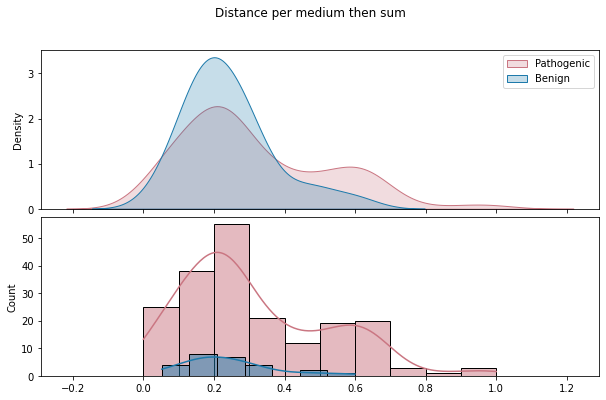

In [73]:
plot_patho_benign(scores=orf_distances_per_medium_summed_original, metric="summed_normalized_euclid_distance_normalized", title="Distance per medium then sum")

Comparison dataset shape: (475, 7)


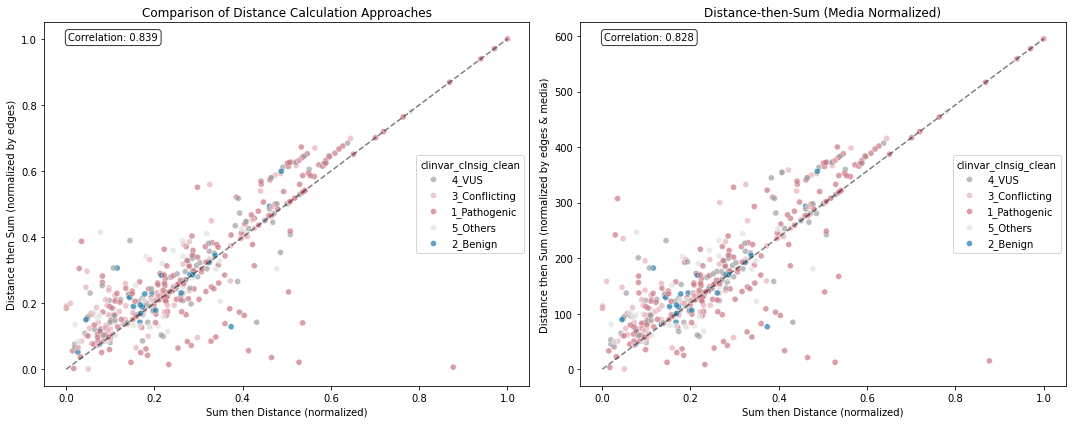


Summary Statistics:
Sum-then-distance range: 0.001 - 1.000
Distance-then-sum range: 0.001 - 1.000
Distance-then-sum (media norm) range: 0.454 - 594.885

Correlation (sum-then-distance vs distance-then-sum): 0.839
Correlation (sum-then-distance vs distance-then-sum media-norm): 0.828


In [74]:
# Compare the two approaches with a scatterplot
# First, we need to merge the two datasets on common variants

# Prepare the sum-then-distance data
sum_then_distance = orf_distances.select([
    "db_orf_id", "db_mut_id", "allele_0", 
    "normalized_euclid_distance_normalized",
    "clinvar_clnsig_clean"
]).rename({
    "normalized_euclid_distance_normalized": "sum_then_distance"
})

# Prepare the distance-then-sum data  
distance_then_sum = orf_distances_per_medium_summed_original.select([
    "db_orf_id", "db_mut_id", "allele_0",
    "summed_normalized_euclid_distance_normalized", 
    "avg_normalized_euclid_distance",
    "clinvar_clnsig_clean"
]).rename({
    "summed_normalized_euclid_distance_normalized": "distance_then_sum",
    "avg_normalized_euclid_distance": "distance_then_sum_by_media"
})

# Merge on allele_0 (unique identifier)
comparison_data = sum_then_distance.join(
    distance_then_sum.select(["allele_0", "distance_then_sum", "distance_then_sum_by_media"]),
    on="allele_0",
    how="inner"
)

print(f"Comparison dataset shape: {comparison_data.shape}")

# Convert to pandas for plotting
comparison_pd = comparison_data.to_pandas()

# Create scatterplot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Raw distance-then-sum vs sum-then-distance
sns.scatterplot(
    data=comparison_pd, 
    x="sum_then_distance", 
    y="distance_then_sum",
    hue="clinvar_clnsig_clean",
    palette=palette_dict["clinvar_clnsig_clean_pillar"],
    alpha=0.7,
    ax=axes[0]
)
axes[0].set_xlabel("Sum then Distance (normalized)")
axes[0].set_ylabel("Distance then Sum (normalized by edges)")
axes[0].set_title("Comparison of Distance Calculation Approaches")
axes[0].plot([0, 1], [0, comparison_pd["distance_then_sum"].max()], 'k--', alpha=0.5, label='Reference line')

# Calculate correlation
corr1 = comparison_pd[["sum_then_distance", "distance_then_sum"]].corr().iloc[0,1]
axes[0].text(0.05, 0.95, f"Correlation: {corr1:.3f}", transform=axes[0].transAxes, 
            bbox=dict(boxstyle="round", facecolor='white', alpha=0.8))

# Plot 2: Media-normalized distance-then-sum vs sum-then-distance  
sns.scatterplot(
    data=comparison_pd,
    x="sum_then_distance", 
    y="distance_then_sum_by_media",
    hue="clinvar_clnsig_clean",
    palette=palette_dict["clinvar_clnsig_clean_pillar"],
    alpha=0.7,
    ax=axes[1]
)
axes[1].set_xlabel("Sum then Distance (normalized)")
axes[1].set_ylabel("Distance then Sum (normalized by edges & media)")
axes[1].set_title("Distance-then-Sum (Media Normalized)")
axes[1].plot([0, 1], [0, comparison_pd["distance_then_sum_by_media"].max()], 'k--', alpha=0.5, label='Reference line')

# Calculate correlation
corr2 = comparison_pd[["sum_then_distance", "distance_then_sum_by_media"]].corr().iloc[0,1]
axes[1].text(0.05, 0.95, f"Correlation: {corr2:.3f}", transform=axes[1].transAxes,
            bbox=dict(boxstyle="round", facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

# Print summary statistics
print("\nSummary Statistics:")
print(f"Sum-then-distance range: {comparison_pd['sum_then_distance'].min():.3f} - {comparison_pd['sum_then_distance'].max():.3f}")
print(f"Distance-then-sum range: {comparison_pd['distance_then_sum'].min():.3f} - {comparison_pd['distance_then_sum'].max():.3f}")
print(f"Distance-then-sum (media norm) range: {comparison_pd['distance_then_sum_by_media'].min():.3f} - {comparison_pd['distance_then_sum_by_media'].max():.3f}")
print(f"\nCorrelation (sum-then-distance vs distance-then-sum): {corr1:.3f}")
print(f"Correlation (sum-then-distance vs distance-then-sum media-norm): {corr2:.3f}")

In [75]:
# Find variants with large discrepancies between the two methods
comparison_pd["discrepancy"] = np.abs(comparison_pd["sum_then_distance"] - comparison_pd["distance_then_sum"])
top_discrepancies = comparison_pd.sort_values(by="discrepancy", ascending=False).head(10)
print("\nTop 10 Variants with Largest Discrepancies:")
print(top_discrepancies[["db_orf_id", "db_mut_id", "allele_0", "sum_then_distance", "distance_then_sum", "discrepancy", "clinvar_clnsig_clean"]])


Top 10 Variants with Largest Discrepancies:
     db_orf_id  db_mut_id         allele_0  sum_then_distance  \
331       7982     202799  HPRT1_Ile132Met           0.877174   
150      14910     218493     HGD_Ser47Leu           0.527739   
447       7982     202808  HPRT1_Asp194Asn           0.465317   
229       4870     215295  KRT6A_Glu461Lys           0.535848   
98        7982     202789   HPRT1_Gly71Arg           0.413287   
249       3732     201256   UROD_Gly281Val           0.034693   
262      13796     218139     HBD_Gly26Asp           0.077826   
172       4723     201746   TPM1_Ala239Thr           0.431888   
465      71892       4003     TH_Cys328Phe           0.029639   
406       4723     201744   TPM1_Asp230Asn           0.503919   

     distance_then_sum  discrepancy clinvar_clnsig_clean  
331           0.006337     0.870837         1_Pathogenic  
150           0.021258     0.506481         1_Pathogenic  
447           0.035694     0.429623         1_Pathogenic  
229

In [76]:
scores.filter(pl.col("db_orf_id") == 7982)

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth
str,str,str,str,str,str,i64,bool,i64,str,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,i64,i64,str,f64,str
"""VUSAPWT1B2r01_008""","""A15""","""VUSAPWT1B2r01_007_008_009_010_…","""VUSAPWT1B2""","""r07""","""LW""",1,false,2860,null,7982,0,"""DisWTY8Dh03""","""H02""","""CEGSint_Y8A_3""","""D10""",4.0,518.128113,false,9.150072,465.86308,"""PRTFDC1""","""HPRT1""",null,null,"""ENSG00000165704""",null,null,null,null,"""HPRT1""","""7982.0_0.0""","""7982.0_0.0_LW_VUSAPWT1B2""","""2860.0_7982.0_0.0_VUSAPWT1B2""","""2860.0_7982.0_VUSAPWT1B2""",1,1,null,362.730401,null
"""VUSAPWT1B2r01_008""","""C15""","""VUSAPWT1B2r01_007_008_009_010_…","""VUSAPWT1B2""","""r07""","""LW""",1,false,7982,null,7982,0,"""DisWTY8Dh03""","""H02""","""CEGSint_Y8A_6""","""G10""",4.0,481.890203,false,9.054985,458.67223,"""HPRT1""","""HPRT1""",null,null,"""ENSG00000165704""",null,null,null,null,"""HPRT1""","""7982.0_0.0""","""7982.0_0.0_LW_VUSAPWT1B2""","""7982.0_7982.0_0.0_VUSAPWT1B2""","""7982.0_7982.0_VUSAPWT1B2""",1,1,null,362.730401,null
"""VUSAPWT1B2r01_026""","""G11""","""VUSAPWT1B2r01_025_026_027_028_…","""VUSAPWT1B2""","""r07""","""LW""",1,false,2860,null,7982,202801,"""VUSMutY8Dh029""","""B07""","""CEGSint_Y8A_3""","""D10""",4.0,508.909813,false,9.126472,352.283014,"""PRTFDC1""","""HPRT1""","""Ala161Ser""","""481G>T""","""ENSG00000165704""","""CEGS2""","""1_Pathogenic""",null,1.0,"""HPRT1_Ala161Ser""","""7982.0_202801.0""","""7982.0_202801.0_LW_VUSAPWT1B2""","""2860.0_7982.0_202801.0_VUSAPWT…","""2860.0_7982.0_VUSAPWT1B2""",1,1,"""Y""",469.217656,null
"""VUSAPWT1B2r01_027""","""C21""","""VUSAPWT1B2r01_025_026_027_028_…","""VUSAPWT1B2""","""r07""","""LW""",1,false,2860,null,7982,202806,"""VUSMutY8Dh029""","""H10""","""CEGSint_Y8A_3""","""D10""",4.0,517.56864,false,9.148651,519.431385,"""PRTFDC1""","""HPRT1""","""Phe199Val""","""595T>G""","""ENSG00000165704""","""CEGS2""","""1_Pathogenic""",null,null,"""HPRT1_Phe199Val""","""7982.0_202806.0""","""7982.0_202806.0_LW_VUSAPWT1B2""","""2860.0_7982.0_202806.0_VUSAPWT…","""2860.0_7982.0_VUSAPWT1B2""",1,1,"""Y""",516.585634,null
"""VUSAPWT1B2r01_027""","""E21""","""VUSAPWT1B2r01_025_026_027_028_…","""VUSAPWT1B2""","""r07""","""LW""",1,false,7982,null,7982,202806,"""VUSMutY8Dh029""","""H10""","""CEGSint_Y8A_6""","""G10""",4.0,525.041842,false,9.167523,509.848379,"""HPRT1""","""HPRT1""","""Phe199Val""","""595T>G""","""ENSG00000165704""","""CEGS2""","""1_Pathogenic""",null,null,"""HPRT1_Phe199Val""","""7982.0_202806.0""","""7982.0_202806.0_LW_VUSAPWT1B2""","""7982.0_7982.0_202806.0_VUSAPWT…","""7982.0_7982.0_VUSAPWT1B2""",1,1,"""Y""",516.585634,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B2r06_032""","""O05""","""VUSAPWT1B2r06_031_032_033_034_…","""VUSAPWT1B2""","""r12""","""LWAH1""",1,false,7982,null,7982,202788,"""VUSMutY8Dh030""","""F12""","""CEGSint_Y8A_6""","""G10""",4.0,491.248386,false,9.080147,503.813746,"""HPRT1""","""HPRT1""","""Gly70Glu""","""209G>A""","""ENSG00000165704""","""CEGS2""","""1_Pathogenic""",null,1.0,"""HPRT1_Gly70Glu""","""7982.0_202788.0""","""7982.0_202788.0_LWAH1_VUSAPWT1…","""7982.0_7982.0_202788.0_VUSAPWT…","""7982.0_7982.0_VUSAPWT1B2""",1,1,"""Y""",7.034641,"""4.0"""
"""VUSAPWT1B2r06_033""","""I03""","""VUSAPWT1B2r06_031_032_033_034_…","""VUSAPWT1B2""","""r12""","""LWAH1""",1,false,2860,null,7982,202787,"""VUSMutY8Dh031""","""C03""","""CEGSint_Y8A_3""","""D

# Other media exploration

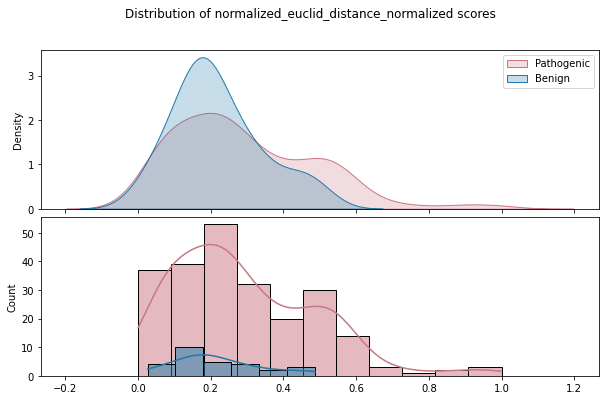

In [77]:
def plot_patho_benign_LLR_thresh(scores=None, metric="normalized_euclid_distance_normalized", num_edge_filter=1, title=None, threshold=None):
    if scores is None:
        scores = orf_distances  # This will use the current state of orf_distances
        
    if threshold:    
        path_thres = scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].max() + 0.016
        print('path_thres:', path_thres)

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")[metric].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean_pillar"]["1_Pathogenic"], fill=True, ax=axes[0])
    sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean_pillar"]["2_Benign"], fill=True, ax=axes[0])
    if threshold:
        axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean_pillar"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
    axes[0].legend()

    sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")[metric].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean_pillar"]["1_Pathogenic"], kde=True, ax=axes[1])
    sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean_pillar"]["2_Benign"], kde=True, ax=axes[1])
    if threshold:
        axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean_pillar"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
    plt.subplots_adjust(hspace=.05)
    if title is not None:
        plt.suptitle(title)
    else:
        plt.suptitle(f"Distribution of {metric} scores")
    plt.show()
    
    if num_edge_filter > 1:
        benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
        # print(benign_scores.shape)

        path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
        # print(path_scores.shape)

        vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
        # print(vus_scores.shape)

        conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
        # print(conf_scores.shape)
    else:
        benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign")
        path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic")
        vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS")
        conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting")
    if threshold:
        print(f"Benign: {benign_scores.filter(pl.col(metric) > path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) > path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
        print(f"Pathogenic: {path_scores.filter(pl.col(metric) > path_thres).shape[0]} ({path_scores.filter(pl.col(metric) > path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
        print(f"VUS: {vus_scores.filter(pl.col(metric) > path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) > path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
        print(f"Conflicting: {conf_scores.filter(pl.col(metric) > path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) > path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")

    
plot_patho_benign()

In [78]:
summed_scores_pd = summed_scores.to_pandas()
summed_scores_pd

,ad_orf_id,db_orf_id,db_mut_id,retest_batch,n_conditions,summed_consensus_score,lwh1_consensus_score,lwa_consensus_score,3at_consensus_score,3at_weighted_consensus_score,...,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,7982,7982,202807,VUSAPWT1B2,4,1796.853661,600.491859,494.984655,1301.869007,10382.949674,...,HPRT1,HPRT1,Asp201Gly,602A>G,ENSG00000165704,CEGS2,1_Pathogenic,0.000000e+00,NaN,HPRT1_Asp201Gly
1,8843,2713,449,VUSAPWT2B1,4,286.127781,196.116016,0.000000,286.127781,2446.410152,...,FAM208B,MLH1,Pro28Leu,83C>T,ENSG00000076242,Edgotyping3,1_Pathogenic,6.840530e-07,3.0,MLH1_Pro28Leu
2,53964,2713,200902,VUSAPWT1B1,4,1496.146773,570.497409,0.000000,1496.146773,16665.667612,...,NFIX,MLH1,Lys751Arg,2252A>G,ENSG00000076242,CEGS2,2_Benign,1.477620e-04,3.0,MLH1_Lys751Arg
3,5772,3535,0,VUSAPWT1B1,3,914.581068,NaN,5.227124,909.353943,NaN,...,BANF1,EMD,None,None,ENSG00000102119,None,None,NaN,NaN,EMD
4,1611,2713,200832,VUSAPWT1B1,4,991.502314,155.613079,0.000000,991.502314,13490.431975,...,SPERT,MLH1,Gly147Arg,439G>C,ENSG00000076242,CEGS2,3_Conflicting,NaN,1.0,MLH1_Gly147Arg
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1803,8186,4062,201433,VUSAPWT2B1,4,521.779536,372.416133,0.000000,521.779536,2731.814870,...,CLEC2D,PLP1,Leu189Pro,566T>C,ENSG00000123560,CEGS2,4_VUS,NaN,1.0,PLP1_Leu189Pro
1804,54668,71337,3938,VUSAPWT1B1,3,162.317651,NaN,18.870588,143.447062,NaN,...,KRT40,ACSF3,Arg10Trp,28C>T,ENSG00000176715,Edgotyping3,4_VUS,2.263420e-04,2.0,ACSF3_Arg10Trp
1805,1611,2713,200818,VUSAPWT1B1,4,262.414710,178.817649,0.000000,262.414710,1821.214738,...,SPERT,MLH1,Leu73Arg,218T>G,ENSG00000076242,CEGS2,1_Pathogenic,NaN,2.0,MLH1_Leu73Arg
1806,100067228,71191,0,VUSAPWT1B2,4,1842.437951,512.050019,417.368307,1425.069645,16001.962029,...,CAMK2A,SUOX,None,None,ENSG00000139531,None,None,NaN,NaN,SUOX


In [79]:
summed_scores_pd['log2fc'] = [np.log2((var + 0.001)/(wt + 0.001)) for var, wt in zip(summed_scores_pd['summed_consensus_score_normalized'], summed_scores_pd['wt_summed_score_normalized'])]
summed_scores_pd_pl = pl.from_pandas(summed_scores_pd)


In [80]:
# # Run LLR threshold method

# summed_scores_pd_pl_alleles = summed_scores_pd_pl.filter(pl.col("db_mut_id") != 0)

# summed_scores_pd_pl_alleles.filter(
#     pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"])
# ).with_columns(
#     pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
#     .then(pl.lit("Positive"))
#     .otherwise(pl.lit("Negative"))
#     .alias("referenceSet"),
#     pl.col("log2fc").alias("score"),
#     pl.col("ppi_group").alias("hgvsp")
# ).select(
#     pl.col(["hgvsp", "score", "referenceSet", "log2fc", "ppi_group", "clinvar_clnsig_clean"])
# ).write_csv("../3_outputs/sqY2H/Edges_referenceSet.csv")

# summed_scores_pd_pl_alleles.with_columns(
#     pl.col("log2fc").alias("score"),
#     pl.col("ppi_group").alias("hgvs_pro")
# ).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/Edges_allScores.csv")

In [81]:
# %%bash
# source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
# conda activate py310

# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/Edges_allScores.csv ../3_outputs/sqY2H/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_bcv.log" --bandwidth "bcv" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/Edges_allScores.csv ../3_outputs/sqY2H/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/Edges_allScores.csv ../3_outputs/sqY2H/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_default.log" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/Edges_allScores.csv ../3_outputs/sqY2H/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_nrd.log" --bandwidth "nrd" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/Edges_allScores.csv ../3_outputs/sqY2H/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_sj.log" --printTransitions --bandwidth "SJ"

## Summed scores

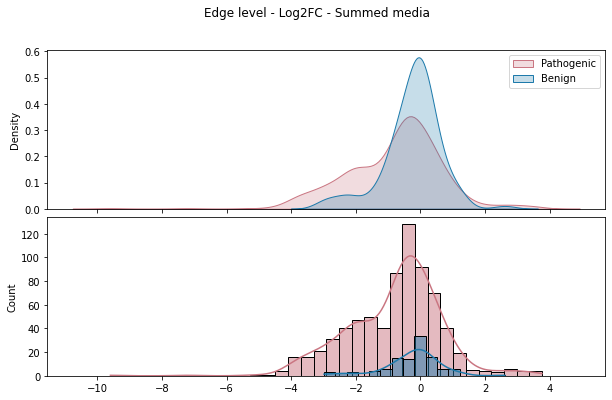

In [82]:
plot_patho_benign(scores=summed_scores_pd_pl, metric="log2fc", title="Edge level - Log2FC - Summed media")

## Selecting media where the WT grows last

In [83]:
scores_pd = scores.to_pandas()

# retain only scoring conditions
scores_pd = scores_pd[scores_pd.condition_name.isin(scoring_conditions)]

scores_pd = scores_pd[scores_pd.consensus_score == scores_pd.consensus_score]  # remove NaNs

# loop through each edge for the WT and identify the last medium where it was scored
wt_media_dict = {} 

min_growth_score = 200

for edge, df in scores_pd[scores_pd.db_mut_id == 0].groupby("edge_group"):
    for media in scoring_conditions:
        media_scores = df[df.condition_name == media]
        if not media_scores.empty and media_scores.consensus_score.values[0] >= min_growth_score:
            wt_media_dict[edge] = media
            
            
# Now filter all scores to only include medium where the WT grew
filtered_scores = []
for edge, df in scores_pd.groupby("edge_group"):
    if edge in wt_media_dict:
        valid_media = wt_media_dict[edge]
        filtered_df = df[df.condition_name == valid_media]
        filtered_scores.append(filtered_df)
    # if edge not in wt_media_dict:
        # print(f"Edge {edge} not found in WT media dict, skipping.")
        
if filtered_scores:
    filtered_scores = pd.concat(filtered_scores, ignore_index=True)
    print(f"Filtered scores shape: {filtered_scores.shape}")
    
# filter for edges with at least a variant and a WT
print(f"Total unique ppis before filtering: {filtered_scores['ppi_group'].nunique()}")
valid_edges = filtered_scores.groupby("edge_group").filter(lambda x: (x.db_mut_id == 0).any() and (x.db_mut_id != 0).any())
print(f"Valid ppis after filtering: {valid_edges['ppi_group'].nunique()}")
    

valid_edges_pl = pl.from_pandas(valid_edges)

# add wt_consensus_score column to compute log2fc

wt_scores = valid_edges_pl.filter(pl.col("db_mut_id") == 0).select(
        [
            "edge_group", "consensus_score"
        ]
    ).rename({"consensus_score": "wt_consensus_score"})

valid_edges_pl = valid_edges_pl.join(
    wt_scores,
    on=["edge_group"],
    how="left"
)

# Compute log2fc
valid_edges_pl = valid_edges_pl.with_columns(
    np.log2(((pl.col("consensus_score") + 1) / (pl.col("wt_consensus_score") + 1)).alias("log2fc")
))

valid_edges_pl

Filtered scores shape: (2141, 40)
Total unique ppis before filtering: 2141
Valid ppis after filtering: 1594


scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc
str,str,str,str,str,str,i64,bool,i64,str,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,i64,i64,str,f64,str,f64,f64
"""VUSAPWT6B1r05_010""","""A01""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""",6,false,100000046,null,7323,216370,"""VUSMutY8Dh020""","""B07""","""CEGSint_Y8A6_1""","""H03""",3.0,616.734667,false,9.380969,590.969958,"""CLDN5""","""PMP22""","""Gly150Cys""","""448G>T""","""ENSG00000109099""","""CEGS2""","""3_Conflicting""",null,1.0,"""PMP22_Gly150Cys""","""7323.0_216370.0""","""7323.0_216370.0_LWH25_VUSAPWT6…","""100000046.0_7323.0_216370.0_VU…","""100000046.0_7323.0_VUSAPWT6B1""",1,1,"""Y""",66.72255,"""3.0""",398.327791,0.56795
"""VUSAPWT6B1r05_010""","""E01""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""",6,false,100000046,null,7323,216371,"""VUSMutY8Dh020""","""H06""","""CEGSint_Y8A6_1""","""H03""",3.0,546.500673,false,9.22038,395.359817,"""CLDN5""","""PMP22""","""Arg157Trp""","""469C>T""","""ENSG00000109099""","""CEGS2""","""1_Pathogenic""",null,2.0,"""PMP22_Arg157Trp""","""7323.0_216371.0""","""7323.0_216371.0_LWH25_VUSAPWT6…","""100000046.0_7323.0_216371.0_VU…","""100000046.0_7323.0_VUSAPWT6B1""",1,1,"""Y""",166.175165,"""3.0""",398.327791,-0.010763
"""VUSAPWT6B1r05_009""","""K23""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""",6,false,100000046,null,7323,0,"""DisWTY8Dh02""","""D09""","""CEGSint_Y8A6_1""","""H03""",3.0,0.0,false,5.643856,398.327791,"""CLDN5""","""PMP22""",null,null,"""ENSG00000109099""",null,null,null,null,"""PMP22""","""7323.0_0.0""","""7323.0_0.0_LWH25_VUSAPWT6B1""","""100000046.0_7323.0_0.0_VUSAPWT…","""100000046.0_7323.0_VUSAPWT6B1""",1,1,null,51.665687,"""3.0""",398.327791,0.0
"""VUSAPWT1B2r03_008""","""I03""","""VUSAPWT1B2r03_007_008_009_010_…","""VUSAPWT1B2""","""r09""","""LWH1""",1,false,100000407,null,53965,0,"""DisWTY8Dh02""","""E12""","""CEGSint_Y8A_3""","""E04""",3.0,418.960792,false,8.873323,434.028112,"""PICK1""","""SMARCB1""",null,null,"""ENSG00000099956""",null,null,null,null,"""SMARCB1""","""53965.0_0.0""","""53965.0_0.0_LWH1_VUSAPWT1B2""","""100000407.0_53965.0_0.0_VUSAPW…","""100000407.0_53965.0_VUSAPWT1B2""",1,1,null,40.631373,"""3.0""",434.028112,0.0
"""VUSAPWT1B2r03_020""","""I11""","""VUSAPWT1B2r03_019_020_021_022_…","""VUSAPWT1B2""","""r09""","""LWH1""",1,false,100000407,null,53965,204888,"""VUSMutY8Dh028""","""H02""","""CEGSint_Y8A_3""","""E04""",0.0,54.798694,false,6.711477,33.988563,"""PICK1""","""SMARCB1""","""Pro48Leu""","""143C>T""","""ENSG00000099956""","""CEGS2""","""4_VUS""",null,1.0,"""SMARCB1_Pro48Leu""","""53965.0_204888.0""","""53965.0_204888.0_LWH1_VUSAPWT1…","""100000407.0_53965.0_204888.0_V…","""100000407.0_53965.0_VUSAPWT1B2""",1,1,"""Y""",44.704249,"""0.0""",434.028112,-3.636153
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r05_029""","""G05""","""VUSAPWT1B1r05_025_026_027_028_…","""VUSAPWT1B1""","""r11""","""LWH25""",1,false,9746,null,54308,3133,"""VUSMutY8Dh015""","""F06""","""CEGSint_Y8A_6""","""C02""",2.0,227.593469,false,8.11683,104.096734,"""MTUS2""","""PKP2""","""Gly68Ser""","""202G>A""","""ENSG00000057294""","""Edgotyping3""","""4_VUS""",null,2.0,"""PKP2_Gly68Ser""","""54308.0_3133.0""","""54308.0_3133.0_LWH25_VUSAPWT1B…","""9746.0_54308.0_3133.0_VUSAPWT1…","""9746.0_54308.0_VUSAPWT1B1""",1,1,"""Y""",150

In [84]:
valid_edges.condition_name.value_counts()

condition_name
LWH25    688
LWA      612
LWH10    183
LWH1     111
Name: count, dtype: int64

In [85]:
# Run LLR threshold method

valid_edges_pl_alleles = valid_edges_pl.filter(pl.col("db_mut_id") != 0)

valid_edges_pl_alleles.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"])
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("log2fc").alias("score"),
    pl.col("ppi_group").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "log2fc", "ppi_group", "clinvar_clnsig_clean"])
).write_csv("../3_outputs/sqY2H/Edges_referenceSet.csv")

valid_edges_pl_alleles.with_columns(
    pl.col("log2fc").alias("score"),
    pl.col("ppi_group").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/Edges_allScores.csv")

In [86]:
# %%bash
# source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
# conda activate py310

# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/Edges_allScores.csv ../3_outputs/sqY2H/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_bcv.log" --bandwidth "bcv" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/Edges_allScores.csv ../3_outputs/sqY2H/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/Edges_allScores.csv ../3_outputs/sqY2H/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_default.log" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/Edges_allScores.csv ../3_outputs/sqY2H/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_nrd.log" --bandwidth "nrd" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/Edges_allScores.csv ../3_outputs/sqY2H/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/Edges_LLR_sj.log" --printTransitions --bandwidth "SJ"

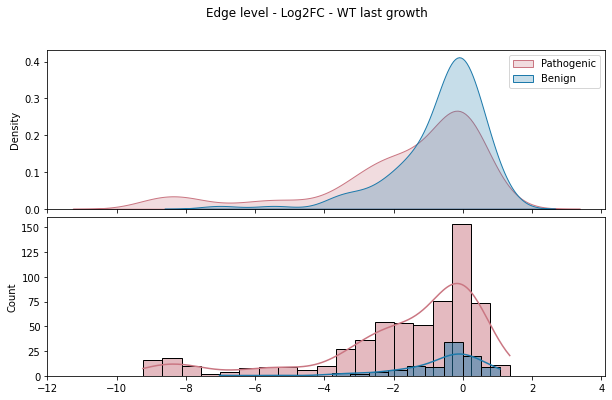

In [87]:
plot_patho_benign(scores=valid_edges_pl, metric="log2fc", title="Edge level - Log2FC - WT last growth")

## Select medium based on last benign growth

In [88]:
scores_pd = scores.to_pandas()

# retain only scoring conditions
scores_pd = scores_pd[scores_pd.condition_name.isin(scoring_conditions)]

scores_pd = scores_pd[scores_pd.consensus_score == scores_pd.consensus_score]  # remove NaNs

# First, build WT media dict as fallback
wt_media_dict = {} 
min_growth_score = 200

for edge, df in scores_pd[scores_pd.db_mut_id == 0].groupby("edge_group"):
    for media in scoring_conditions:
        media_scores = df[df.condition_name == media]
        if not media_scores.empty and media_scores.consensus_score.values[0] >= min_growth_score:
            wt_media_dict[edge] = media

# Now build benign media dict
benign_media_dict = {}

for edge, df in scores_pd[scores_pd.clinvar_clnsig_clean == "2_Benign"].groupby("edge_group"):
    var_dict = {}
    for ppi, ppi_df in df.groupby("ppi_group"):
        var_dict[ppi] = []
        for media in scoring_conditions:
            media_scores = ppi_df[ppi_df.condition_name == media]
            if not media_scores.empty and media_scores.consensus_score.values[0] >= min_growth_score:
                var_dict[ppi].append(media)
                
    if len(var_dict) == 1:
        # only one variant for this edge, take the last media where it grew
        for ppi, media_list in var_dict.items():
            if media_list:
                benign_media_dict[edge] = media_list[-1]
    elif len(var_dict) > 1:
        # multiple benign variants. Take the last media of the most sensible variant (the one that grew in the least media)
        sorted_variants = sorted(var_dict.items(), key=lambda x: len(x[1]))
        for ppi, media_list in sorted_variants:
            if media_list:
                benign_media_dict[edge] = media_list[-1]
                break        

# Combine benign and WT media dicts with benign taking priority
combined_media_dict = {}
for edge in set(list(benign_media_dict.keys()) + list(wt_media_dict.keys())):
    if edge in benign_media_dict:
        combined_media_dict[edge] = benign_media_dict[edge]
        # print(f"Edge {edge}: Using benign methodology -> {benign_media_dict[edge]}")
    elif edge in wt_media_dict:
        combined_media_dict[edge] = wt_media_dict[edge]
        # print(f"Edge {edge}: Fallback to WT methodology -> {wt_media_dict[edge]}")
    # If edge is in neither dict, it will be skipped

print(f"Total edges with benign variants: {len(benign_media_dict)}")
print(f"Total edges with WT fallback: {len(wt_media_dict) - len(benign_media_dict)}")
print(f"Total edges covered: {len(combined_media_dict)}")


            
# Now filter all scores to only include medium where the WT grew
filtered_scores_benigns = []
for edge, df in scores_pd.groupby("edge_group"):
    if edge in combined_media_dict:
        valid_media = combined_media_dict[edge]
        filtered_df = df[df.condition_name == valid_media]
        filtered_scores_benigns.append(filtered_df)
    # if edge not in wt_media_dict:
        # print(f"Edge {edge} not found in WT media dict, skipping.")
        
if filtered_scores_benigns:
    filtered_scores_benigns = pd.concat(filtered_scores_benigns, ignore_index=True)
    print(f"Filtered scores shape: {filtered_scores_benigns.shape}")
    
# filter for edges with at least a variant and a WT
print(f"Total unique ppis before filtering: {filtered_scores_benigns['ppi_group'].nunique()}")
valid_edges_benigns = filtered_scores_benigns.groupby("edge_group").filter(lambda x: (x.db_mut_id == 0).any() and (x.db_mut_id != 0).any())
print(f"Valid ppis after filtering: {valid_edges_benigns['ppi_group'].nunique()}")
    

valid_edges_benigns_pl = pl.from_pandas(valid_edges_benigns)

# add wt_consensus_score column to compute log2fc

wt_scores = valid_edges_benigns_pl.filter(pl.col("db_mut_id") == 0).select(
        [
            "edge_group", "consensus_score"
        ]
    ).rename({"consensus_score": "wt_consensus_score"})

valid_edges_benigns_pl = valid_edges_benigns_pl.join(
    wt_scores,
    on=["edge_group"],
    how="left"
)

# Compute log2fc
valid_edges_benigns_pl = valid_edges_benigns_pl.with_columns(
    np.log2(((pl.col("consensus_score") + 1) / (pl.col("wt_consensus_score") + 1)).alias("log2fc")
))

valid_edges_benigns_pl


Total edges with benign variants: 79
Total edges with WT fallback: 709
Total edges covered: 800
Filtered scores shape: (2187, 40)
Total unique ppis before filtering: 2187
Valid ppis after filtering: 1552


scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc
str,str,str,str,str,str,i64,bool,i64,str,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,i64,i64,str,f64,str,f64,f64
"""VUSAPWT6B1r05_010""","""A01""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""",6,false,100000046,null,7323,216370,"""VUSMutY8Dh020""","""B07""","""CEGSint_Y8A6_1""","""H03""",3.0,616.734667,false,9.380969,590.969958,"""CLDN5""","""PMP22""","""Gly150Cys""","""448G>T""","""ENSG00000109099""","""CEGS2""","""3_Conflicting""",null,1.0,"""PMP22_Gly150Cys""","""7323.0_216370.0""","""7323.0_216370.0_LWH25_VUSAPWT6…","""100000046.0_7323.0_216370.0_VU…","""100000046.0_7323.0_VUSAPWT6B1""",1,1,"""Y""",66.72255,"""3.0""",398.327791,0.56795
"""VUSAPWT6B1r05_010""","""E01""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""",6,false,100000046,null,7323,216371,"""VUSMutY8Dh020""","""H06""","""CEGSint_Y8A6_1""","""H03""",3.0,546.500673,false,9.22038,395.359817,"""CLDN5""","""PMP22""","""Arg157Trp""","""469C>T""","""ENSG00000109099""","""CEGS2""","""1_Pathogenic""",null,2.0,"""PMP22_Arg157Trp""","""7323.0_216371.0""","""7323.0_216371.0_LWH25_VUSAPWT6…","""100000046.0_7323.0_216371.0_VU…","""100000046.0_7323.0_VUSAPWT6B1""",1,1,"""Y""",166.175165,"""3.0""",398.327791,-0.010763
"""VUSAPWT6B1r05_009""","""K23""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""",6,false,100000046,null,7323,0,"""DisWTY8Dh02""","""D09""","""CEGSint_Y8A6_1""","""H03""",3.0,0.0,false,5.643856,398.327791,"""CLDN5""","""PMP22""",null,null,"""ENSG00000109099""",null,null,null,null,"""PMP22""","""7323.0_0.0""","""7323.0_0.0_LWH25_VUSAPWT6B1""","""100000046.0_7323.0_0.0_VUSAPWT…","""100000046.0_7323.0_VUSAPWT6B1""",1,1,null,51.665687,"""3.0""",398.327791,0.0
"""VUSAPWT1B2r03_008""","""I03""","""VUSAPWT1B2r03_007_008_009_010_…","""VUSAPWT1B2""","""r09""","""LWH1""",1,false,100000407,null,53965,0,"""DisWTY8Dh02""","""E12""","""CEGSint_Y8A_3""","""E04""",3.0,418.960792,false,8.873323,434.028112,"""PICK1""","""SMARCB1""",null,null,"""ENSG00000099956""",null,null,null,null,"""SMARCB1""","""53965.0_0.0""","""53965.0_0.0_LWH1_VUSAPWT1B2""","""100000407.0_53965.0_0.0_VUSAPW…","""100000407.0_53965.0_VUSAPWT1B2""",1,1,null,40.631373,"""3.0""",434.028112,0.0
"""VUSAPWT1B2r03_020""","""I11""","""VUSAPWT1B2r03_019_020_021_022_…","""VUSAPWT1B2""","""r09""","""LWH1""",1,false,100000407,null,53965,204888,"""VUSMutY8Dh028""","""H02""","""CEGSint_Y8A_3""","""E04""",0.0,54.798694,false,6.711477,33.988563,"""PICK1""","""SMARCB1""","""Pro48Leu""","""143C>T""","""ENSG00000099956""","""CEGS2""","""4_VUS""",null,1.0,"""SMARCB1_Pro48Leu""","""53965.0_204888.0""","""53965.0_204888.0_LWH1_VUSAPWT1…","""100000407.0_53965.0_204888.0_V…","""100000407.0_53965.0_VUSAPWT1B2""",1,1,"""Y""",44.704249,"""0.0""",434.028112,-3.636153
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r05_029""","""G05""","""VUSAPWT1B1r05_025_026_027_028_…","""VUSAPWT1B1""","""r11""","""LWH25""",1,false,9746,null,54308,3133,"""VUSMutY8Dh015""","""F06""","""CEGSint_Y8A_6""","""C02""",2.0,227.593469,false,8.11683,104.096734,"""MTUS2""","""PKP2""","""Gly68Ser""","""202G>A""","""ENSG00000057294""","""Edgotyping3""","""4_VUS""",null,2.0,"""PKP2_Gly68Ser""","""54308.0_3133.0""","""54308.0_3133.0_LWH25_VUSAPWT1B…","""9746.0_54308.0_3133.0_VUSAPWT1…","""9746.0_54308.0_VUSAPWT1B1""",1,1,"""Y""",150

In [89]:
scores_pd = scores.to_pandas()

# retain only scoring conditions
scores_pd = scores_pd[scores_pd.condition_name.isin(scoring_conditions)]

scores_pd = scores_pd[scores_pd.consensus_score == scores_pd.consensus_score]  # remove NaNs

# First, build WT media dict as fallback
wt_media_dict = {} 
min_growth_score = 200

for edge, df in scores_pd[scores_pd.db_mut_id == 0].groupby("edge_group"):
    for media in scoring_conditions:
        media_scores = df[df.condition_name == media]
        if not media_scores.empty and media_scores.consensus_score.values[0] >= min_growth_score:
            wt_media_dict[edge] = media

# Now build benign media dict
benign_media_dict = {}

for edge, df in scores_pd[scores_pd.clinvar_clnsig_clean == "2_Benign"].groupby("edge_group"):
    var_dict = {}
    for ppi, ppi_df in df.groupby("ppi_group"):
        var_dict[ppi] = []
        for media in scoring_conditions:
            media_scores = ppi_df[ppi_df.condition_name == media]
            if not media_scores.empty and media_scores.consensus_score.values[0] >= min_growth_score:
                var_dict[ppi].append(media)
                
    if len(var_dict) == 1:
        # only one variant for this edge, take the last media where it grew
        for ppi, media_list in var_dict.items():
            if media_list:
                benign_media_dict[edge] = media_list[-1]
    elif len(var_dict) > 1:
        # multiple benign variants. Take the last media of the most sensible variant (the one that grew in the least media)
        sorted_variants = sorted(var_dict.items(), key=lambda x: len(x[1]))
        for ppi, media_list in sorted_variants:
            if media_list:
                benign_media_dict[edge] = media_list[-1]
                break        

# Combine benign and WT media dicts with benign taking priority
combined_media_dict = {}
for edge in set(list(benign_media_dict.keys()) + list(wt_media_dict.keys())):
    if edge in benign_media_dict:
        combined_media_dict[edge] = benign_media_dict[edge]
        # print(f"Edge {edge}: Using benign methodology -> {benign_media_dict[edge]}")
    elif edge in wt_media_dict:
        combined_media_dict[edge] = wt_media_dict[edge]
        # print(f"Edge {edge}: Fallback to WT methodology -> {wt_media_dict[edge]}")
    # If edge is in neither dict, it will be skipped

print(f"Total edges with benign variants: {len(benign_media_dict)}")
print(f"Total edges with WT fallback: {len(wt_media_dict) - len(benign_media_dict)}")
print(f"Total edges covered: {len(combined_media_dict)}")


            
# Now filter all scores to only include medium where the WT grew
filtered_scores_benigns = []
for edge, df in scores_pd.groupby("edge_group"):
    if edge in combined_media_dict:
        valid_media = combined_media_dict[edge]
        filtered_df = df[df.condition_name == valid_media]
        filtered_scores_benigns.append(filtered_df)
    # if edge not in wt_media_dict:
        # print(f"Edge {edge} not found in WT media dict, skipping.")
        
if filtered_scores_benigns:
    filtered_scores_benigns = pd.concat(filtered_scores_benigns, ignore_index=True)
    print(f"Filtered scores shape: {filtered_scores_benigns.shape}")
    
# filter for edges with at least a variant and a WT
print(f"Total unique ppis before filtering: {filtered_scores_benigns['ppi_group'].nunique()}")
valid_edges_benigns = filtered_scores_benigns.groupby("edge_group").filter(lambda x: (x.db_mut_id == 0).any() and (x.db_mut_id != 0).any())
print(f"Valid ppis after filtering: {valid_edges_benigns['ppi_group'].nunique()}")
    

valid_edges_benigns_pl = pl.from_pandas(valid_edges_benigns)

# add wt_consensus_score column to compute log2fc

wt_scores = valid_edges_benigns_pl.filter(pl.col("db_mut_id") == 0).select(
        [
            "edge_group", "consensus_score"
        ]
    ).rename({"consensus_score": "wt_consensus_score"})

valid_edges_benigns_pl = valid_edges_benigns_pl.join(
    wt_scores,
    on=["edge_group"],
    how="left"
)

# Compute log2fc
valid_edges_benigns_pl = valid_edges_benigns_pl.with_columns(
    np.log2(((pl.col("consensus_score") + 1) / (pl.col("wt_consensus_score") + 1)).alias("log2fc")
))

valid_edges_benigns_pl


Total edges with benign variants: 79
Total edges with WT fallback: 709
Total edges covered: 800
Filtered scores shape: (2187, 40)
Total unique ppis before filtering: 2187
Valid ppis after filtering: 1552


scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,automated_log2,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc
str,str,str,str,str,str,i64,bool,i64,str,i64,i64,str,str,str,str,f64,f64,bool,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,i64,i64,str,f64,str,f64,f64
"""VUSAPWT6B1r05_010""","""A01""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""",6,false,100000046,null,7323,216370,"""VUSMutY8Dh020""","""B07""","""CEGSint_Y8A6_1""","""H03""",3.0,616.734667,false,9.380969,590.969958,"""CLDN5""","""PMP22""","""Gly150Cys""","""448G>T""","""ENSG00000109099""","""CEGS2""","""3_Conflicting""",null,1.0,"""PMP22_Gly150Cys""","""7323.0_216370.0""","""7323.0_216370.0_LWH25_VUSAPWT6…","""100000046.0_7323.0_216370.0_VU…","""100000046.0_7323.0_VUSAPWT6B1""",1,1,"""Y""",66.72255,"""3.0""",398.327791,0.56795
"""VUSAPWT6B1r05_010""","""E01""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""",6,false,100000046,null,7323,216371,"""VUSMutY8Dh020""","""H06""","""CEGSint_Y8A6_1""","""H03""",3.0,546.500673,false,9.22038,395.359817,"""CLDN5""","""PMP22""","""Arg157Trp""","""469C>T""","""ENSG00000109099""","""CEGS2""","""1_Pathogenic""",null,2.0,"""PMP22_Arg157Trp""","""7323.0_216371.0""","""7323.0_216371.0_LWH25_VUSAPWT6…","""100000046.0_7323.0_216371.0_VU…","""100000046.0_7323.0_VUSAPWT6B1""",1,1,"""Y""",166.175165,"""3.0""",398.327791,-0.010763
"""VUSAPWT6B1r05_009""","""K23""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""",6,false,100000046,null,7323,0,"""DisWTY8Dh02""","""D09""","""CEGSint_Y8A6_1""","""H03""",3.0,0.0,false,5.643856,398.327791,"""CLDN5""","""PMP22""",null,null,"""ENSG00000109099""",null,null,null,null,"""PMP22""","""7323.0_0.0""","""7323.0_0.0_LWH25_VUSAPWT6B1""","""100000046.0_7323.0_0.0_VUSAPWT…","""100000046.0_7323.0_VUSAPWT6B1""",1,1,null,51.665687,"""3.0""",398.327791,0.0
"""VUSAPWT1B2r03_008""","""I03""","""VUSAPWT1B2r03_007_008_009_010_…","""VUSAPWT1B2""","""r09""","""LWH1""",1,false,100000407,null,53965,0,"""DisWTY8Dh02""","""E12""","""CEGSint_Y8A_3""","""E04""",3.0,418.960792,false,8.873323,434.028112,"""PICK1""","""SMARCB1""",null,null,"""ENSG00000099956""",null,null,null,null,"""SMARCB1""","""53965.0_0.0""","""53965.0_0.0_LWH1_VUSAPWT1B2""","""100000407.0_53965.0_0.0_VUSAPW…","""100000407.0_53965.0_VUSAPWT1B2""",1,1,null,40.631373,"""3.0""",434.028112,0.0
"""VUSAPWT1B2r03_020""","""I11""","""VUSAPWT1B2r03_019_020_021_022_…","""VUSAPWT1B2""","""r09""","""LWH1""",1,false,100000407,null,53965,204888,"""VUSMutY8Dh028""","""H02""","""CEGSint_Y8A_3""","""E04""",0.0,54.798694,false,6.711477,33.988563,"""PICK1""","""SMARCB1""","""Pro48Leu""","""143C>T""","""ENSG00000099956""","""CEGS2""","""4_VUS""",null,1.0,"""SMARCB1_Pro48Leu""","""53965.0_204888.0""","""53965.0_204888.0_LWH1_VUSAPWT1…","""100000407.0_53965.0_204888.0_V…","""100000407.0_53965.0_VUSAPWT1B2""",1,1,"""Y""",44.704249,"""0.0""",434.028112,-3.636153
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r05_029""","""G05""","""VUSAPWT1B1r05_025_026_027_028_…","""VUSAPWT1B1""","""r11""","""LWH25""",1,false,9746,null,54308,3133,"""VUSMutY8Dh015""","""F06""","""CEGSint_Y8A_6""","""C02""",2.0,227.593469,false,8.11683,104.096734,"""MTUS2""","""PKP2""","""Gly68Ser""","""202G>A""","""ENSG00000057294""","""Edgotyping3""","""4_VUS""",null,2.0,"""PKP2_Gly68Ser""","""54308.0_3133.0""","""54308.0_3133.0_LWH25_VUSAPWT1B…","""9746.0_54308.0_3133.0_VUSAPWT1…","""9746.0_54308.0_VUSAPWT1B1""",1,1,"""Y""",150

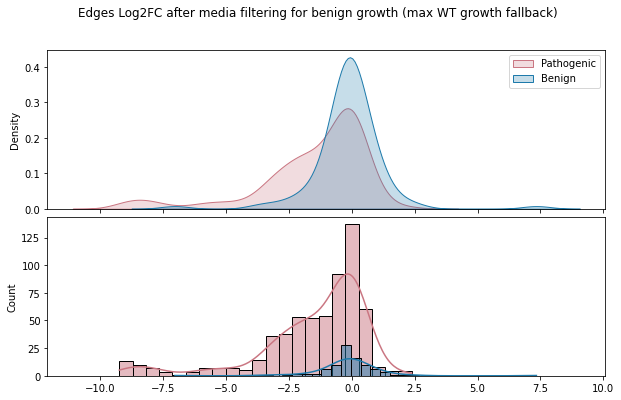

In [90]:
plot_patho_benign(scores=valid_edges_benigns_pl, metric="log2fc", title="Edges Log2FC after media filtering for benign growth (max WT growth fallback)")

# Log2FC edges all media/across medium

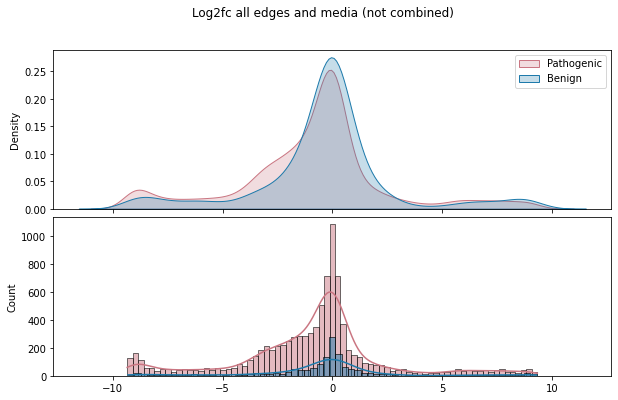

In [91]:
scores_pd = scores.to_pandas()

scores_pd = scores_pd[scores_pd.condition_name.isin(scoring_conditions)]

scores_pd = scores_pd[scores_pd.consensus_score == scores_pd.consensus_score]  # remove NaNs

scores_pd_pl = pl.from_pandas(scores_pd)

wt_scores = scores_pd_pl.filter(pl.col("db_mut_id") == 0).select(
        [
            "edge_group", "consensus_score"
        ]
    ).rename({"consensus_score": "wt_consensus_score"})

scores_pd_pl = scores_pd_pl.join(
    wt_scores,
    on=["edge_group"],
    how="left"
)

# Compute log2fc
scores_pd_pl = scores_pd_pl.with_columns(
    np.log2(((pl.col("consensus_score") + 1) / (pl.col("wt_consensus_score") + 1)).alias("log2fc")
))


plot_patho_benign(scores=scores_pd_pl, metric="log2fc", title="Log2fc all edges and media (not combined)")

Medium: LWH1, shape: (2791, 40)


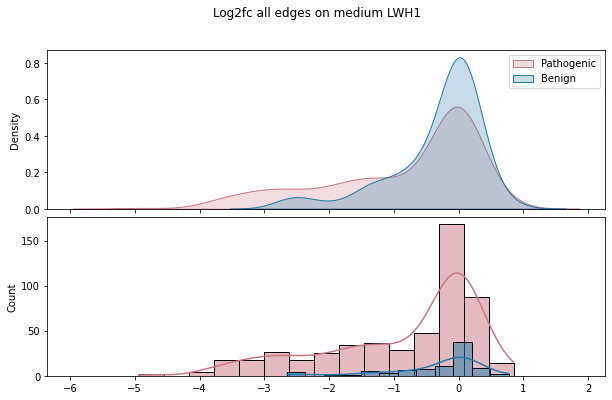

Medium: LWH10, shape: (2939, 40)


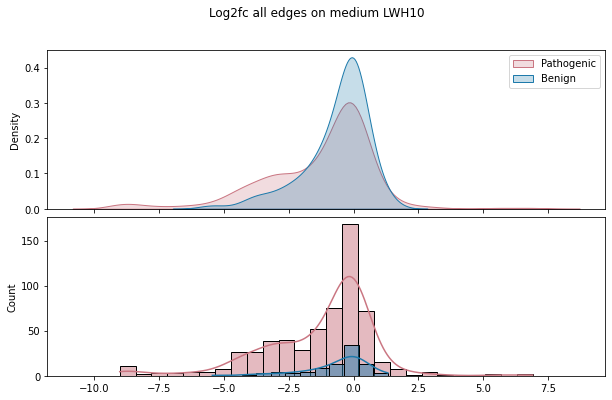

Medium: LWH25, shape: (2945, 40)


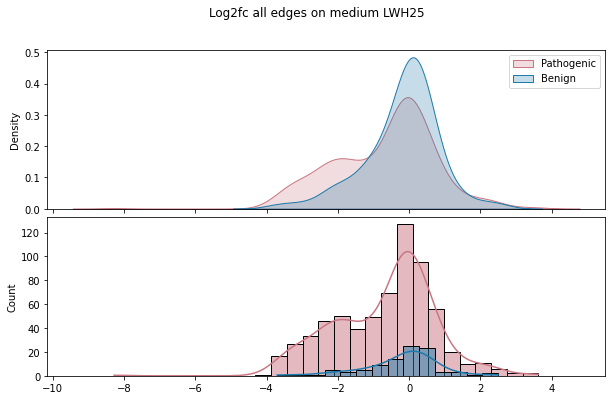

Medium: LWA, shape: (2964, 40)


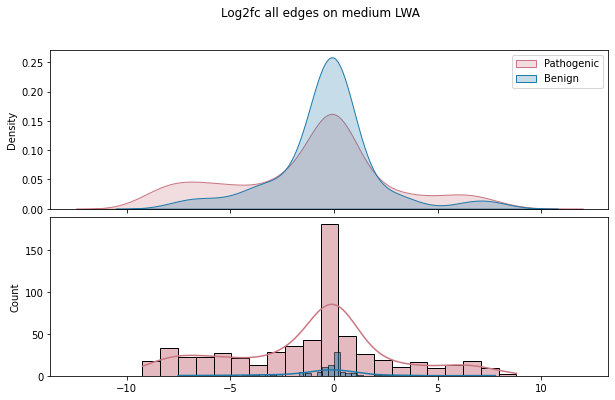

In [92]:
scores_pd = scores.to_pandas()

for medium in scoring_conditions:
    plot_df = scores_pd[scores_pd.condition_name == medium]
    print(f"Medium: {medium}, shape: {plot_df.shape}")

    plot_df = plot_df[plot_df.consensus_score == plot_df.consensus_score]  # remove NaNs

    plot_df_pl = pl.from_pandas(plot_df)

    wt_scores = plot_df_pl.filter(pl.col("db_mut_id") == 0).select(
            [
                "edge_group", "consensus_score"
            ]
        ).rename({"consensus_score": "wt_consensus_score"})

    plot_df_pl = plot_df_pl.join(
        wt_scores,
        on=["edge_group"],
        how="left"
    )

    # Compute log2fc
    plot_df_pl = plot_df_pl.with_columns(
        np.log2(((pl.col("consensus_score") + 1) / (pl.col("wt_consensus_score") + 1)).alias("log2fc")
    ))


    plot_patho_benign(scores=plot_df_pl, metric="log2fc", title=f"Log2fc all edges on medium {medium}")

Medium: LWA, shape: (2964, 40)


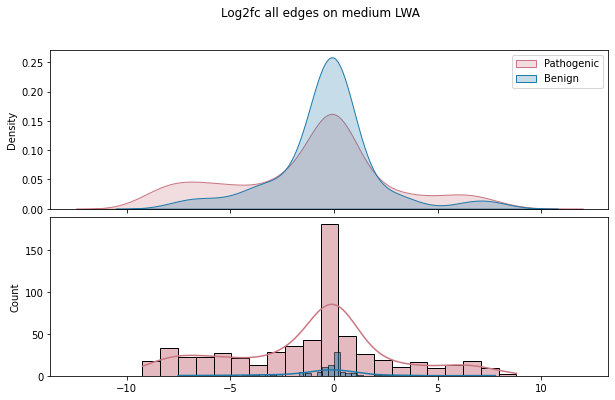

In [93]:
plot_df = scores_pd[scores_pd.condition_name == 'LWA']
print(f"Medium: {medium}, shape: {plot_df.shape}")

plot_df = plot_df[plot_df.consensus_score == plot_df.consensus_score]  # remove NaNs

plot_df_pl = pl.from_pandas(plot_df)

wt_scores = plot_df_pl.filter(pl.col("db_mut_id") == 0).select(
        [
            "edge_group", "consensus_score"
        ]
    ).rename({"consensus_score": "wt_consensus_score"})

plot_df_pl = plot_df_pl.join(
    wt_scores,
    on=["edge_group"],
    how="left"
)

# Compute log2fc
plot_df_pl = plot_df_pl.with_columns(
    np.log2(((pl.col("consensus_score") + 1) / (pl.col("wt_consensus_score") + 1)).alias("log2fc")
))


plot_patho_benign(scores=plot_df_pl, metric="log2fc", title=f"Log2fc all edges on medium {medium}")

In [94]:
plot_df_pl_pd = plot_df_pl.to_pandas()
plot_df_pl_pd[plot_df_pl_pd.log2fc > 2]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc
59,VUSAPWT1B1r02_016,A05,VUSAPWT1B1r02_013_014_015_016_017_018,VUSAPWT1B1,r08,LWA,1,False,3598,None,...,52920.0_2681.0_LWA_VUSAPWT1B1,3598.0_52920.0_2681.0_VUSAPWT1B1,3598.0_52920.0_VUSAPWT1B1,1,1,Y,0.000000,2.0,0.000000,3.394919
65,VUSAPWT1B1r02_016,A23,VUSAPWT1B1r02_013_014_015_016_017_018,VUSAPWT1B1,r08,LWA,1,False,3598,None,...,52920.0_2687.0_LWA_VUSAPWT1B1,3598.0_52920.0_2687.0_VUSAPWT1B1,3598.0_52920.0_VUSAPWT1B1,1,1,Y,0.000000,2.0,0.000000,7.617615
69,VUSAPWT1B1r02_016,C15,VUSAPWT1B1r02_013_014_015_016_017_018,VUSAPWT1B1,r08,LWA,1,False,2845,None,...,52920.0_2685.0_LWA_VUSAPWT1B1,2845.0_52920.0_2685.0_VUSAPWT1B1,2845.0_52920.0_VUSAPWT1B1,1,1,Y,0.000000,0.0,0.000000,2.962144
80,VUSAPWT1B1r02_016,E21,VUSAPWT1B1r02_013_014_015_016_017_018,VUSAPWT1B1,r08,LWA,1,False,2845,None,...,52920.0_2687.0_LWA_VUSAPWT1B1,2845.0_52920.0_2687.0_VUSAPWT1B1,2845.0_52920.0_VUSAPWT1B1,1,1,Y,0.000000,3.0,0.000000,8.912681
83,VUSAPWT1B1r02_016,G07,VUSAPWT1B1r02_013_014_015_016_017_018,VUSAPWT1B1,r08,LWA,1,False,3598,None,...,52920.0_2682.0_LWA_VUSAPWT1B1,3598.0_52920.0_2682.0_VUSAPWT1B1,3598.0_52920.0_VUSAPWT1B1,1,1,Y,0.000000,0.0,0.000000,6.901518
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2590,VUSAPWT1B1r02_033,E17,VUSAPWT1B1r02_031_032_033_034_035_036,VUSAPWT1B1,r08,LWA,1,False,54647,None,...,3535.0_201190.0_LWA_VUSAPWT1B1,54647.0_3535.0_201190.0_VUSAPWT1B1,54647.0_3535.0_VUSAPWT1B1,1,1,Y,0.000000,0.0,0.000000,2.583469
2592,VUSAPWT1B1r02_033,E23,VUSAPWT1B1r02_031_032_033_034_035_036,VUSAPWT1B1,r08,LWA,1,False,6811,None,...,4723.0_201733.0_LWA_VUSAPWT1B1,6811.0_4723.0_201733.0_VUSAPWT1B1,6811.0_4723.0_VUSAPWT1B1,1,1,Y,NaN,3.0,1.870588,3.232476
2608,VUSAPWT1B1r02_036,K19,VUSAPWT1B1r02_031_032_033_034_035_036,VUSAPWT1B1,r08,LWA,1,False,9746,None,...,54308.0_218854.0_LWA_VUSAPWT1B1,9746.0_54308.0_218854.0_VUSAPWT1B1,9746.0_54308.0_VUSAPWT1B1,1,1,Y,14.648039,3.0,0.000000,7.071136
2620,VUSAPWT1B1r02_036,M21,VUSAPWT1B1r02_031_032_033_034_035_036,VUSAPWT1B1,r08,LWA,1,False,9746,None,...,54308.0_218855.0_LWA_VUSAPWT1B1,9746.0_54308.0_218855.0_VUSAPWT1B1,9746.0_54308.0_VUSAPWT1B1,1,1,Y,0.000000,3.0,0.000000,6.318577


# Auroc - PR curves

APPROACH 1: Summed scores (all media)


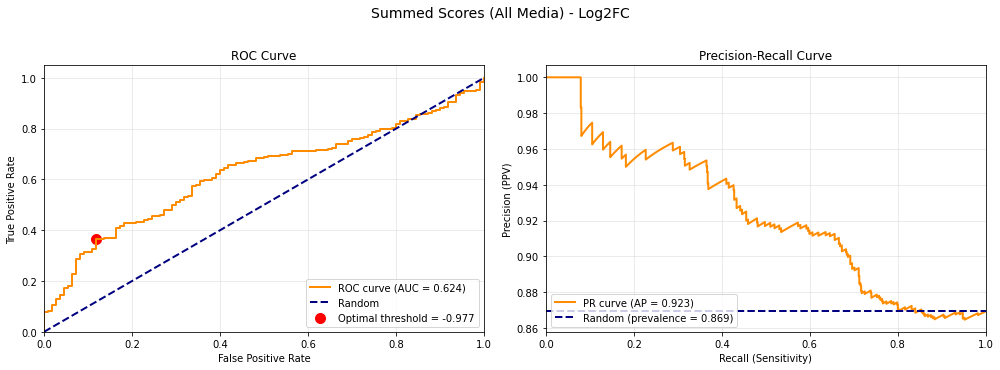


Classification Performance: Summed Scores (All Media) - Log2FC
Dataset: 841 variants (731 pathogenic, 110 benign)

Area Under ROC Curve (AUROC): 0.6239
Area Under PR Curve (AUPRC):  0.9230

Optimal Threshold (Youden): -0.9774

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.3653
  Specificity:           0.8818
  Precision (PPV):       0.9536
  Negative Pred. Value:  0.1729
  Accuracy:              0.4328


APPROACH 2: Media filtered by WT growth


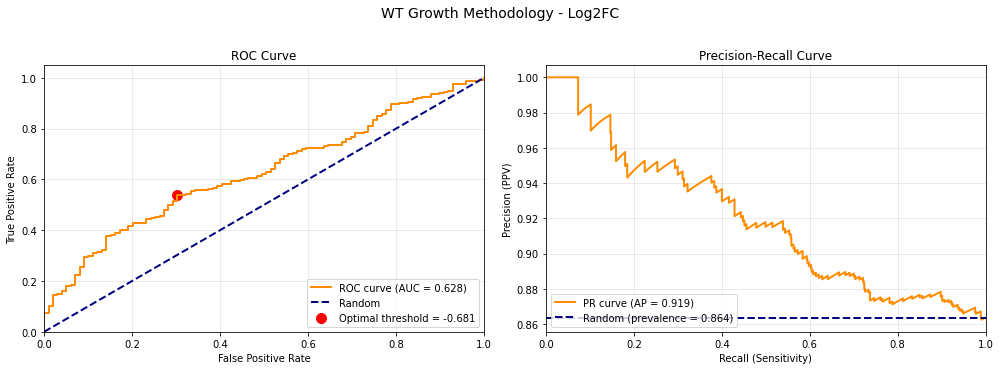


Classification Performance: WT Growth Methodology - Log2FC
Dataset: 726 variants (627 pathogenic, 99 benign)

Area Under ROC Curve (AUROC): 0.6276
Area Under PR Curve (AUPRC):  0.9189

Optimal Threshold (Youden): -0.6807

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.5391
  Specificity:           0.6970
  Precision (PPV):       0.9185
  Negative Pred. Value:  0.1927
  Accuracy:              0.5606


APPROACH 3: Media filtered by benign growth (WT fallback)


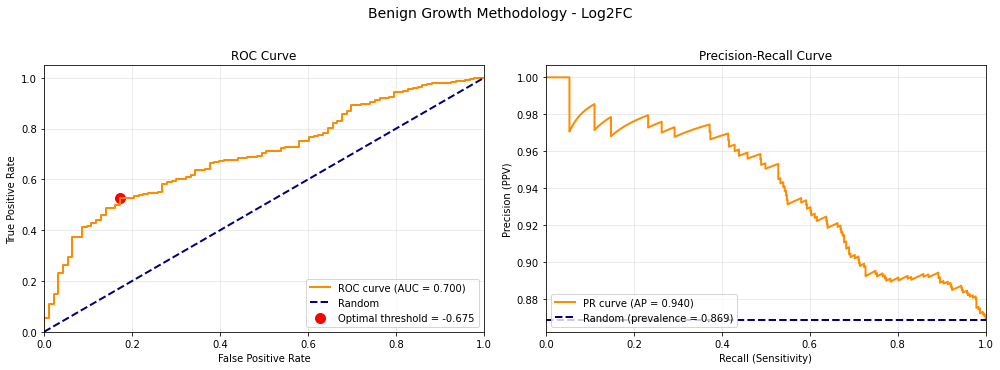


Classification Performance: Benign Growth Methodology - Log2FC
Dataset: 708 variants (615 pathogenic, 93 benign)

Area Under ROC Curve (AUROC): 0.7003
Area Under PR Curve (AUPRC):  0.9397

Optimal Threshold (Youden): -0.6755

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.5285
  Specificity:           0.8280
  Precision (PPV):       0.9531
  Negative Pred. Value:  0.2098
  Accuracy:              0.5678


COMPARISON OF ALL APPROACHES
            Approach    AUROC    AUPRC  Sensitivity  Specificity  N_variants
       Summed Scores 0.623927 0.922968     0.365253     0.881818         841
    WT Growth Filter 0.627600 0.918905     0.539075     0.696970         726
Benign Growth Filter 0.700341 0.939727     0.528455     0.827957         708


In [95]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_classification_performance(scores_df, metric_col, title=None, filter_edges=None):
    """
    Calculate AUROC and Precision-Recall metrics for benign vs pathogenic classification.
    
    Parameters:
    -----------
    scores_df : polars.DataFrame
        DataFrame containing scores and clinical significance
    metric_col : str
        Name of the column containing the metric to evaluate (e.g., 'log2fc')
    title : str, optional
        Title for the plots
    filter_edges : int, optional
        Minimum number of edges required to include a variant
    
    Returns:
    --------
    dict : Dictionary containing AUROC, AUPRC, and other metrics
    """
    
    # Convert to pandas for sklearn compatibility
    scores_pd = scores_df.to_pandas()
    
    # Filter by number of edges if specified
    if filter_edges is not None and 'num_edges' in scores_pd.columns:
        scores_pd = scores_pd[scores_pd['num_edges'] >= filter_edges]
    
    # Filter to only benign and pathogenic
    filtered = scores_pd[scores_pd['clinvar_clnsig_clean'].isin(['1_Pathogenic', '2_Benign'])].copy()
    
    # Remove NaN values in metric column
    filtered = filtered[filtered[metric_col].notna()]
    
    if len(filtered) < 10:
        print(f"Warning: Only {len(filtered)} variants available for evaluation")
        return None
    
    # Create binary labels (1 = Pathogenic, 0 = Benign)
    y_true = (filtered['clinvar_clnsig_clean'] == '1_Pathogenic').astype(int)
    y_scores = filtered[metric_col].values
    
    # For log2fc, more negative = more pathogenic, so we negate for ROC
    # Adjust this based on your metric interpretation
    y_scores_roc = -y_scores  # Negative log2fc indicates loss of function (pathogenic)
    
    # Calculate ROC curve and AUROC
    fpr, tpr, roc_thresholds = roc_curve(y_true, y_scores_roc)
    roc_auc = auc(fpr, tpr)
    
    # Calculate Precision-Recall curve and AUPRC
    precision, recall, pr_thresholds = precision_recall_curve(y_true, y_scores_roc)
    auprc = average_precision_score(y_true, y_scores_roc)
    
    # Calculate optimal threshold (Youden's index for ROC)
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold_roc = -roc_thresholds[optimal_idx]  # Convert back to original scale
    
    # Create plots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # ROC Curve
    axes[0].plot(fpr, tpr, color='darkorange', lw=2, 
                 label=f'ROC curve (AUC = {roc_auc:.3f})')
    axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
    axes[0].scatter(fpr[optimal_idx], tpr[optimal_idx], marker='o', color='red', 
                    s=100, label=f'Optimal threshold = {optimal_threshold_roc:.3f}')
    axes[0].set_xlim([0.0, 1.0])
    axes[0].set_ylim([0.0, 1.05])
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title('ROC Curve')
    axes[0].legend(loc="lower right")
    axes[0].grid(alpha=0.3)
    
    # Precision-Recall Curve
    axes[1].plot(recall, precision, color='darkorange', lw=2,
                 label=f'PR curve (AP = {auprc:.3f})')
    axes[1].axhline(y=y_true.mean(), color='navy', linestyle='--', lw=2,
                    label=f'Random (prevalence = {y_true.mean():.3f})')
    axes[1].set_xlim([0.0, 1.0])
    # axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel('Recall (Sensitivity)')
    axes[1].set_ylabel('Precision (PPV)')
    axes[1].set_title('Precision-Recall Curve')
    axes[1].legend(loc="lower left")
    axes[1].grid(alpha=0.3)
    
    if title:
        fig.suptitle(title, fontsize=14, y=1.02)
    
    plt.tight_layout()
    plt.show()
    
    # Calculate additional metrics at optimal threshold
    y_pred_optimal = (y_scores_roc >= roc_thresholds[optimal_idx]).astype(int)
    
    tp = np.sum((y_pred_optimal == 1) & (y_true == 1))
    fp = np.sum((y_pred_optimal == 1) & (y_true == 0))
    tn = np.sum((y_pred_optimal == 0) & (y_true == 0))
    fn = np.sum((y_pred_optimal == 0) & (y_true == 1))
    
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    # Print summary
    print(f"\n{'='*60}")
    print(f"Classification Performance: {title if title else metric_col}")
    print(f"{'='*60}")
    print(f"Dataset: {len(filtered)} variants ({y_true.sum()} pathogenic, {len(y_true) - y_true.sum()} benign)")
    print(f"\nArea Under ROC Curve (AUROC): {roc_auc:.4f}")
    print(f"Area Under PR Curve (AUPRC):  {auprc:.4f}")
    print(f"\nOptimal Threshold (Youden): {optimal_threshold_roc:.4f}")
    print(f"\nPerformance at Optimal Threshold:")
    print(f"  Sensitivity (Recall):  {sensitivity:.4f}")
    print(f"  Specificity:           {specificity:.4f}")
    print(f"  Precision (PPV):       {ppv:.4f}")
    print(f"  Negative Pred. Value:  {npv:.4f}")
    print(f"  Accuracy:              {accuracy:.4f}")
    print(f"{'='*60}\n")
    
    # Return metrics dictionary
    return {
        'auroc': roc_auc,
        'auprc': auprc,
        'optimal_threshold': optimal_threshold_roc,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'precision': ppv,
        'npv': npv,
        'accuracy': accuracy,
        'n_variants': len(filtered),
        'n_pathogenic': y_true.sum(),
        'n_benign': len(y_true) - y_true.sum(),
        'fpr': fpr,
        'tpr': tpr,
        'roc_thresholds': roc_thresholds,
        'precision_curve': precision,
        'recall_curve': recall,
        'pr_thresholds': pr_thresholds
    }


# Example usage for different approaches:

# 1. Summed scores approach
print("="*80)
print("APPROACH 1: Summed scores (all media)")
print("="*80)
results_summed = evaluate_classification_performance(
    summed_scores_pd_pl.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc',
    title='Summed Scores (All Media) - Log2FC'
)

# 2. WT growth methodology
print("\n" + "="*80)
print("APPROACH 2: Media filtered by WT growth")
print("="*80)
results_wt = evaluate_classification_performance(
    valid_edges_pl.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc',
    title='WT Growth Methodology - Log2FC'
)

# 3. Benign growth methodology (with WT fallback)
print("\n" + "="*80)
print("APPROACH 3: Media filtered by benign growth (WT fallback)")
print("="*80)
results_benign = evaluate_classification_performance(
    valid_edges_benigns_pl.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc',
    title='Benign Growth Methodology - Log2FC'
)

# # 4. All media (not combined)
# print("\n" + "="*80)
# print("APPROACH 4: All edges all media (not combined)")
# print("="*80)
# # results_all = evaluate_classification_performance(
#     scores_pd_pl.filter(pl.col("db_mut_id") != 0),
#     metric_col='log2fc',
#     title='All Media (Not Combined) - Log2FC'
# )


# Compare all approaches
print("\n" + "="*80)
print("COMPARISON OF ALL APPROACHES")
print("="*80)
comparison_results = []
for name, result in [
    ('Summed Scores', results_summed),
    ('WT Growth Filter', results_wt),
    ('Benign Growth Filter', results_benign),
    # ('All Media Separate', results_all)
]:
    if result:
        comparison_results.append({
            'Approach': name,
            'AUROC': result['auroc'],
            'AUPRC': result['auprc'],
            'Sensitivity': result['sensitivity'],
            'Specificity': result['specificity'],
            'N_variants': result['n_variants']
        })

comparison_df = pd.DataFrame(comparison_results)
print(comparison_df.to_string(index=False))

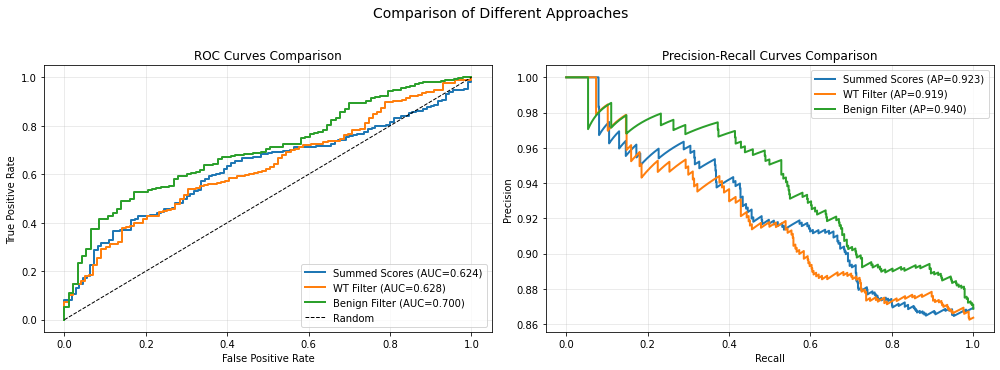

In [96]:
# Create combined comparison plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC curves comparison
for name, result in [
    ('Summed Scores', results_summed),
    ('WT Filter', results_wt),
    ('Benign Filter', results_benign),
    # ('All Media', results_all)
]:
    if result:
        axes[0].plot(result['fpr'], result['tpr'], lw=2, 
                     label=f"{name} (AUC={result['auroc']:.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves Comparison')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3)

# PR curves comparison
for name, result in [
    ('Summed Scores', results_summed),
    ('WT Filter', results_wt),
    ('Benign Filter', results_benign),
    # ('All Media', results_all)
]:
    if result:
        axes[1].plot(result['recall_curve'], result['precision_curve'], lw=2,
                     label=f"{name} (AP={result['auprc']:.3f})")

axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves Comparison')
axes[1].legend(loc='best')
axes[1].grid(alpha=0.3)

plt.suptitle('Comparison of Different Approaches', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

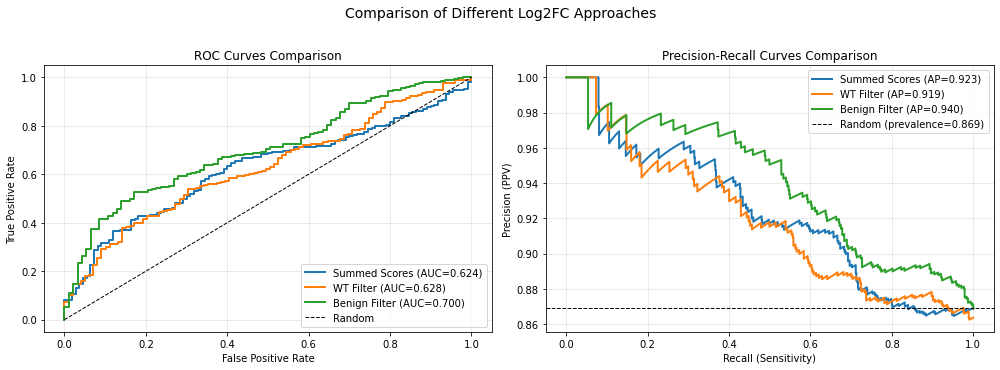


=== Performance Summary (Prevalence-Adjusted) ===

Summed Scores:
  AUROC: 0.624
  AP: 0.923
  Prevalence: 0.869
  AP gain over random: 0.054 (6.2% improvement)

WT Filter:
  AUROC: 0.628
  AP: 0.919
  Prevalence: 0.869
  AP gain over random: 0.050 (5.7% improvement)

Benign Filter:
  AUROC: 0.700
  AP: 0.940
  Prevalence: 0.869
  AP gain over random: 0.071 (8.1% improvement)


In [97]:
# Create combined comparison plot with prevalence information
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC curves comparison
for name, result in [
    ('Summed Scores', results_summed),
    ('WT Filter', results_wt),
    ('Benign Filter', results_benign),
    # ('All Media', results_all)
]:
    if result:
        axes[0].plot(result['fpr'], result['tpr'], lw=2, 
                     label=f"{name} (AUC={result['auroc']:.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves Comparison')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3)

# PR curves comparison with prevalence-adjusted baseline
for name, result in [
    ('Summed Scores', results_summed),
    ('WT Filter', results_wt),
    ('Benign Filter', results_benign),
    # ('All Media', results_all)
]:
    if result:
        prevalence = result.get('prevalence', 0.869)  # Get prevalence from result or use default
        axes[1].plot(result['recall_curve'], result['precision_curve'], lw=2,
                     label=f"{name} (AP={result['auprc']:.3f})")#, prev={prevalence:.2f})")

# Add prevalence baseline for the first dataset (assuming they all have similar prevalence)
if results_summed:
    prevalence = results_summed.get('prevalence', 0.869)
    axes[1].axhline(y=prevalence, color='k', linestyle='--', lw=1, 
                    label=f'Random (prevalence={prevalence:.3f})')

axes[1].set_xlabel('Recall (Sensitivity)')
axes[1].set_ylabel('Precision (PPV)')
axes[1].set_title('Precision-Recall Curves Comparison')
axes[1].legend(loc='best')
axes[1].grid(alpha=0.3)

plt.suptitle('Comparison of Different Log2FC Approaches', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Print prevalence-adjusted performance summary
print("\n=== Performance Summary (Prevalence-Adjusted) ===")
for name, result in [
    ('Summed Scores', results_summed),
    ('WT Filter', results_wt),
    ('Benign Filter', results_benign),
    # ('All Media', results_all)
]:
    if result:
        prevalence = result.get('prevalence', 0.869)
        ap = result['auprc']
        auroc = result['auroc']
        ap_gain = ap - prevalence  # How much better than random
        
        print(f"\n{name}:")
        print(f"  AUROC: {auroc:.3f}")
        print(f"  AP: {ap:.3f}")
        print(f"  Prevalence: {prevalence:.3f}")
        print(f"  AP gain over random: {ap_gain:.3f} ({ap_gain/prevalence*100:.1f}% improvement)")

In [105]:
summed_orfs = summed_scores_pd.db_orf_id.unique().tolist()
benign_orfs = valid_edges_benigns_pl.to_pandas().db_orf_id.unique().tolist()

In [113]:
dropped_orfs = list(set(summed_orfs) - set(benign_orfs))
dropped_orfs

[7651, 12739, 8965, 143]

APPROACH 1: Summed scores (all media) - BALANCED
  Original: {0: 110, 1: 731} -> Balancing to 110 per class


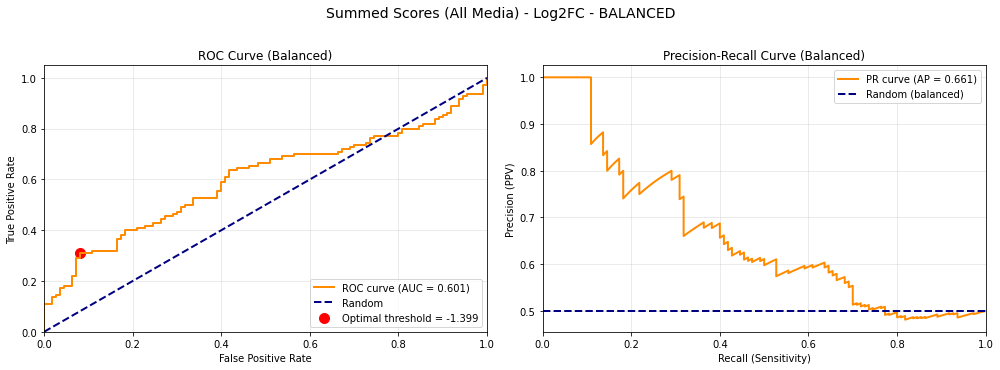


Classification Performance: Summed Scores (All Media) - Log2FC
(BALANCED DATASET)
Dataset: 220 variants (110 pathogenic, 110 benign)

Area Under ROC Curve (AUROC): 0.6007
Area Under PR Curve (AUPRC):  0.6606
  Gain over random:           +0.1606

Optimal Threshold (Youden): -1.3989

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.3091
  Specificity:           0.9182
  Precision (PPV):       0.7907
  Negative Pred. Value:  0.5706
  Accuracy:              0.6136


APPROACH 2: Media filtered by WT growth - BALANCED
  Original: {0: 99, 1: 627} -> Balancing to 99 per class


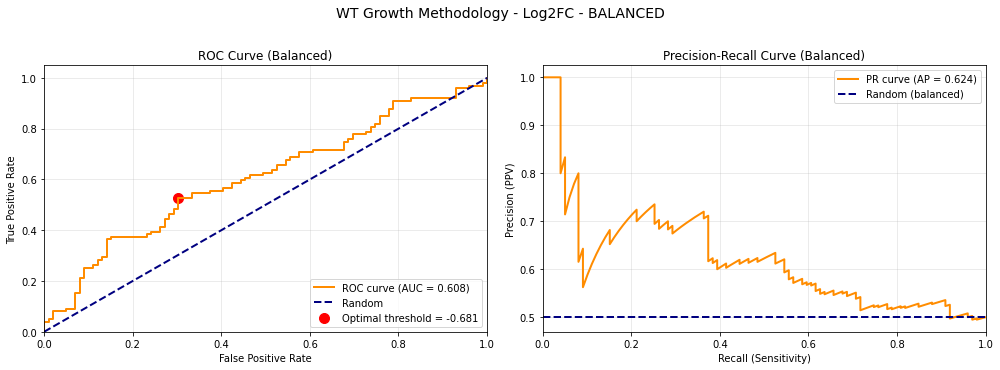


Classification Performance: WT Growth Methodology - Log2FC
(BALANCED DATASET)
Dataset: 198 variants (99 pathogenic, 99 benign)

Area Under ROC Curve (AUROC): 0.6076
Area Under PR Curve (AUPRC):  0.6236
  Gain over random:           +0.1236

Optimal Threshold (Youden): -0.6807

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.5253
  Specificity:           0.6970
  Precision (PPV):       0.6341
  Negative Pred. Value:  0.5948
  Accuracy:              0.6111


APPROACH 3: Media filtered by benign growth (WT fallback) - BALANCED
  Original: {0: 93, 1: 615} -> Balancing to 93 per class


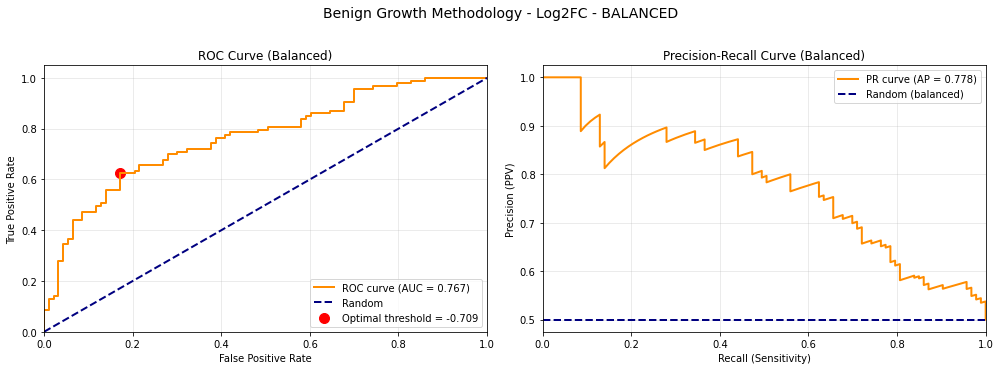


Classification Performance: Benign Growth Methodology - Log2FC
(BALANCED DATASET)
Dataset: 186 variants (93 pathogenic, 93 benign)

Area Under ROC Curve (AUROC): 0.7668
Area Under PR Curve (AUPRC):  0.7783
  Gain over random:           +0.2783

Optimal Threshold (Youden): -0.7089

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.6237
  Specificity:           0.8280
  Precision (PPV):       0.7838
  Negative Pred. Value:  0.6875
  Accuracy:              0.7258


CREATING COMBINED COMPARISON PLOTS


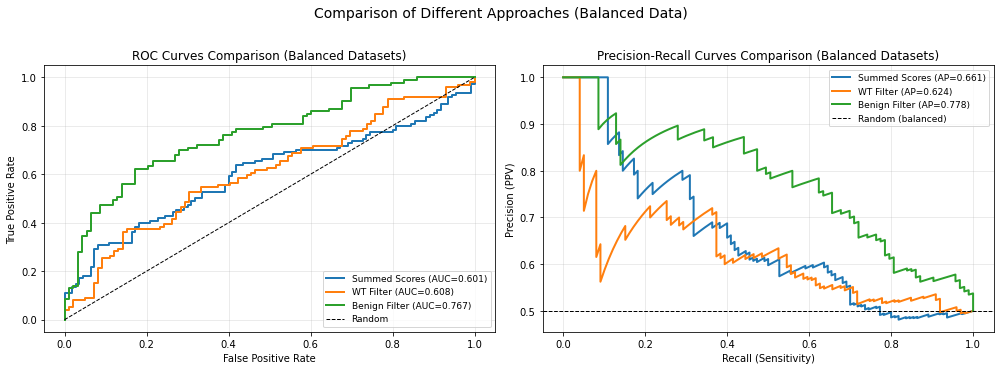


COMPARISON OF ALL APPROACHES (BALANCED)
            Approach  AUROC  AUPRC AP Gain Sensitivity Specificity  N_variants
       Summed Scores 0.6007 0.6606 +0.1606      0.3091      0.9182         220
    WT Growth Filter 0.6076 0.6236 +0.1236      0.5253      0.6970         198
Benign Growth Filter 0.7668 0.7783 +0.2783      0.6237      0.8280         186

Note: AP Gain = AUPRC - 0.5 (gain over random classifier on balanced data)


In [98]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.utils import resample
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

def balance_dataset(y_true, y_scores, random_state=42):
    """
    Balance dataset by undersampling the majority class to match minority class
    
    Parameters:
    -----------
    y_true : array-like
        True labels (0/1)
    y_scores : array-like
        Scores or predictions
    random_state : int
        Random seed for reproducibility
        
    Returns:
    --------
    y_true_balanced, y_scores_balanced : arrays
        Balanced labels and scores
    """
    # Convert to arrays
    y_true = np.array(y_true)
    y_scores = np.array(y_scores)
    
    # Find majority and minority classes
    unique, counts = np.unique(y_true, return_counts=True)
    minority_class = unique[np.argmin(counts)]
    majority_class = unique[np.argmax(counts)]
    
    min_count = counts.min()
    
    print(f"  Original: {dict(zip(unique, counts))} -> Balancing to {min_count} per class")
    
    # Get indices for each class
    minority_idx = np.where(y_true == minority_class)[0]
    majority_idx = np.where(y_true == majority_class)[0]
    
    # Undersample majority class to match minority
    majority_idx_downsampled = resample(majority_idx, 
                                        replace=False,
                                        n_samples=min_count,
                                        random_state=random_state)
    
    # Combine indices
    balanced_idx = np.concatenate([minority_idx, majority_idx_downsampled])
    np.random.seed(random_state)
    np.random.shuffle(balanced_idx)
    
    return y_true[balanced_idx], y_scores[balanced_idx]


def evaluate_classification_performance(scores_df, metric_col, title=None, filter_edges=None, balance=True):
    """
    Calculate AUROC and Precision-Recall metrics for benign vs pathogenic classification.
    
    Parameters:
    -----------
    scores_df : polars.DataFrame
        DataFrame containing scores and clinical significance
    metric_col : str
        Name of the column containing the metric to evaluate (e.g., 'log2fc')
    title : str, optional
        Title for the plots
    filter_edges : int, optional
        Minimum number of edges required to include a variant
    balance : bool
        Whether to balance the dataset before evaluation
    
    Returns:
    --------
    dict : Dictionary containing AUROC, AUPRC, and other metrics
    """
    
    # Convert to pandas for sklearn compatibility
    scores_pd = scores_df.to_pandas()
    
    # Filter by number of edges if specified
    if filter_edges is not None and 'num_edges' in scores_pd.columns:
        scores_pd = scores_pd[scores_pd['num_edges'] >= filter_edges]
    
    # Filter to only benign and pathogenic
    filtered = scores_pd[scores_pd['clinvar_clnsig_clean'].isin(['1_Pathogenic', '2_Benign'])].copy()
    
    # Remove NaN values in metric column
    filtered = filtered[filtered[metric_col].notna()]
    
    if len(filtered) < 10:
        print(f"Warning: Only {len(filtered)} variants available for evaluation")
        return None
    
    # Create binary labels (1 = Pathogenic, 0 = Benign)
    y_true = (filtered['clinvar_clnsig_clean'] == '1_Pathogenic').astype(int).values
    y_scores = filtered[metric_col].values
    
    # For log2fc, more negative = more pathogenic, so we negate for ROC
    y_scores_roc = -y_scores  # Negative log2fc indicates loss of function (pathogenic)
    
    # Balance if requested
    if balance:
        y_true, y_scores_roc = balance_dataset(y_true, y_scores_roc)
    
    # Calculate ROC curve and AUROC
    fpr, tpr, roc_thresholds = roc_curve(y_true, y_scores_roc)
    roc_auc = auc(fpr, tpr)
    
    # Calculate Precision-Recall curve and AUPRC
    precision, recall, pr_thresholds = precision_recall_curve(y_true, y_scores_roc)
    auprc = average_precision_score(y_true, y_scores_roc)
    
    # Calculate optimal threshold (Youden's index for ROC)
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold_roc = -roc_thresholds[optimal_idx]  # Convert back to original scale
    
    # Create plots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # ROC Curve
    axes[0].plot(fpr, tpr, color='darkorange', lw=2, 
                 label=f'ROC curve (AUC = {roc_auc:.3f})')
    axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
    axes[0].scatter(fpr[optimal_idx], tpr[optimal_idx], marker='o', color='red', 
                    s=100, label=f'Optimal threshold = {optimal_threshold_roc:.3f}')
    axes[0].set_xlim([0.0, 1.0])
    axes[0].set_ylim([0.0, 1.05])
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title('ROC Curve' + (' (Balanced)' if balance else ''))
    axes[0].legend(loc="lower right")
    axes[0].grid(alpha=0.3)
    
    # Precision-Recall Curve
    baseline_precision = 0.5 if balance else y_true.mean()
    axes[1].plot(recall, precision, color='darkorange', lw=2,
                 label=f'PR curve (AP = {auprc:.3f})')
    axes[1].axhline(y=baseline_precision, color='navy', linestyle='--', lw=2,
                    label=f'Random ({"balanced" if balance else f"prevalence = {baseline_precision:.3f}"})')
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_xlabel('Recall (Sensitivity)')
    axes[1].set_ylabel('Precision (PPV)')
    axes[1].set_title('Precision-Recall Curve' + (' (Balanced)' if balance else ''))
    axes[1].legend(loc="best")
    axes[1].grid(alpha=0.3)
    
    if title:
        fig.suptitle(title + (' - BALANCED' if balance else ''), fontsize=14, y=1.02)
    
    plt.tight_layout()
    plt.show()
    
    # Calculate additional metrics at optimal threshold
    y_pred_optimal = (y_scores_roc >= roc_thresholds[optimal_idx]).astype(int)
    
    tp = np.sum((y_pred_optimal == 1) & (y_true == 1))
    fp = np.sum((y_pred_optimal == 1) & (y_true == 0))
    tn = np.sum((y_pred_optimal == 0) & (y_true == 0))
    fn = np.sum((y_pred_optimal == 0) & (y_true == 1))
    
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    # Print summary
    print(f"\n{'='*60}")
    print(f"Classification Performance: {title if title else metric_col}")
    if balance:
        print(f"(BALANCED DATASET)")
    print(f"{'='*60}")
    print(f"Dataset: {len(y_true)} variants ({y_true.sum()} pathogenic, {len(y_true) - y_true.sum()} benign)")
    print(f"\nArea Under ROC Curve (AUROC): {roc_auc:.4f}")
    print(f"Area Under PR Curve (AUPRC):  {auprc:.4f}")
    if balance:
        print(f"  Gain over random:           {auprc - 0.5:+.4f}")
    print(f"\nOptimal Threshold (Youden): {optimal_threshold_roc:.4f}")
    print(f"\nPerformance at Optimal Threshold:")
    print(f"  Sensitivity (Recall):  {sensitivity:.4f}")
    print(f"  Specificity:           {specificity:.4f}")
    print(f"  Precision (PPV):       {ppv:.4f}")
    print(f"  Negative Pred. Value:  {npv:.4f}")
    print(f"  Accuracy:              {accuracy:.4f}")
    print(f"{'='*60}\n")
    
    # Return metrics dictionary
    return {
        'auroc': roc_auc,
        'auprc': auprc,
        'optimal_threshold': optimal_threshold_roc,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'precision': ppv,
        'npv': npv,
        'accuracy': accuracy,
        'n_variants': len(y_true),
        'n_pathogenic': int(y_true.sum()),
        'n_benign': int(len(y_true) - y_true.sum()),
        'prevalence': float(y_true.mean()),
        'fpr': fpr,
        'tpr': tpr,
        'roc_thresholds': roc_thresholds,
        'precision_curve': precision,
        'recall_curve': recall,
        'pr_thresholds': pr_thresholds,
        'balanced': balance
    }


# Example usage for different approaches WITH BALANCING:

# 1. Summed scores approach
print("="*80)
print("APPROACH 1: Summed scores (all media) - BALANCED")
print("="*80)
results_summed_balanced = evaluate_classification_performance(
    summed_scores_pd_pl.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc',
    title='Summed Scores (All Media) - Log2FC',
    balance=True
)

# 2. WT growth methodology
print("\n" + "="*80)
print("APPROACH 2: Media filtered by WT growth - BALANCED")
print("="*80)
results_wt_balanced = evaluate_classification_performance(
    valid_edges_pl.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc',
    title='WT Growth Methodology - Log2FC',
    balance=True
)

# 3. Benign growth methodology (with WT fallback)
print("\n" + "="*80)
print("APPROACH 3: Media filtered by benign growth (WT fallback) - BALANCED")
print("="*80)
results_benign_balanced = evaluate_classification_performance(
    valid_edges_benigns_pl.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc',
    title='Benign Growth Methodology - Log2FC',
    balance=True
)

# # 4. All media (not combined)
# print("\n" + "="*80)
# print("APPROACH 4: All edges all media (not combined) - BALANCED")
# print("="*80)
# # results_all = evaluate_classification_performance(
#     scores_pd_pl.filter(pl.col("db_mut_id") != 0),
#     metric_col='log2fc',
#     title='All Media (Not Combined) - Log2FC',
#     balance=True
# )


# COMBINED COMPARISON PLOTS
print("\n" + "="*80)
print("CREATING COMBINED COMPARISON PLOTS")
print("="*80)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC curves comparison (BALANCED DATASETS)
for name, result in [
    ('Summed Scores', results_summed_balanced),
    ('WT Filter', results_wt_balanced),
    ('Benign Filter', results_benign_balanced),
    # ('All Media', results_all)
]:
    if result:
        axes[0].plot(result['fpr'], result['tpr'], lw=2, 
                     label=f"{name} (AUC={result['auroc']:.3f})")#, n={result['n_variants']})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves Comparison (Balanced Datasets)')
axes[0].legend(loc='lower right', fontsize=9)
axes[0].grid(alpha=0.3)

# PR curves comparison (BALANCED DATASETS)
for name, result in [
    ('Summed Scores', results_summed_balanced),
    ('WT Filter', results_wt_balanced),
    ('Benign Filter', results_benign_balanced),
    # ('All Media', results_all)
]:
    if result:
        axes[1].plot(result['recall_curve'], result['precision_curve'], lw=2,
                     label=f"{name} (AP={result['auprc']:.3f})")

# For balanced datasets, random baseline should be at 0.5
axes[1].axhline(y=0.5, color='k', linestyle='--', lw=1, label='Random (balanced)')

axes[1].set_xlabel('Recall (Sensitivity)')
axes[1].set_ylabel('Precision (PPV)')
axes[1].set_title('Precision-Recall Curves Comparison (Balanced Datasets)')
axes[1].legend(loc='best', fontsize=9)
axes[1].grid(alpha=0.3)

plt.suptitle('Comparison of Different Approaches (Balanced Data)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


# Compare all approaches
print("\n" + "="*80)
print("COMPARISON OF ALL APPROACHES (BALANCED)")
print("="*80)
comparison_results = []
for name, result in [
    ('Summed Scores', results_summed_balanced),
    ('WT Growth Filter', results_wt_balanced),
    ('Benign Growth Filter', results_benign_balanced),
    # ('All Media Separate', results_all)
]:
    if result:
        comparison_results.append({
            'Approach': name,
            'AUROC': f"{result['auroc']:.4f}",
            'AUPRC': f"{result['auprc']:.4f}",
            'AP Gain': f"{result['auprc'] - 0.5:+.4f}",
            'Sensitivity': f"{result['sensitivity']:.4f}",
            'Specificity': f"{result['specificity']:.4f}",
            'N_variants': result['n_variants']
        })

comparison_df = pd.DataFrame(comparison_results)
print(comparison_df.to_string(index=False))
print("\nNote: AP Gain = AUPRC - 0.5 (gain over random classifier on balanced data)")